# Visualizations


## Validation Note

This notebook is exploratory/visual. Some sections use task-level visualization or manual cross-validation over the available data, so it should not be used as final test-set evidence. Final experiment-guided configuration estimates live in `05_experiment_guided_config_c_ip.ipynb` and `09_experiment_guided_config_im_ip.ipynb`, where development CV and final holdout evaluation are separated explicitly.


## Searchlight spatiotemporal dynamics

This notebook summarizes the minimal pipeline for studying spatiotemporal information in Congruent vs Pure Incongruent with two final visualizations reusing the same accuracy matrix:

1. Heatmap time × electrode for Theta and Alpha
2. Sequential topomaps + GIF for Theta and Alpha

Workflow:

1. Select subjects from the CSV and limit them with `MAX_SUBJECTS`
2. Load epochs robustly and skip problematic files
3. Define common channels and sliding windows
4. Train the searchlight by band, electrode and window
5. Make the group statistical contrast and draw the maps
6. Generate the sequential topomaps and the GIF

In [5]:
import os
import warnings
from pathlib import Path
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import matplotlib as mpl
import mne
import importlib
from joblib import cpu_count, parallel_backend
from IPython.display import display, Image
from mne.decoding import GeneralizingEstimator, cross_val_multiscore
from scipy.spatial.distance import pdist, squareform
import numpy.ma as ma
from scipy.ndimage import gaussian_filter1d

from scipy.stats import ttest_1samp
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA

# %pip install -q pyriemann
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

# %pip install -q mne-connectivity
from mne_connectivity import spectral_connectivity_epochs
from mne_connectivity.viz import plot_connectivity_circle
from mne.datasets import fetch_fsaverage
from mne.minimum_norm import make_inverse_operator, apply_inverse
from matplotlib.collections import LineCollection
from mne.channels.layout import _find_topomap_coords

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"
else:
    DRIVE_ROOT = Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU")
    PROJECT_DIR = DRIVE_ROOT / "TFG_Nils_2026"

BASE_DIR = PROJECT_DIR
DATA_DIR = PROJECT_DIR / "02_Data" / "01_Preprocessed_epochs"
ANALYSIS_ROOT = PROJECT_DIR / "04_Anàlisi"
ANALYSIS_DIR = ANALYSIS_ROOT / "visualitzacions"
FIGURES_DIR = ANALYSIS_DIR / "figures"
CACHE_DIR = ANALYSIS_DIR / "cache"

for folder in (DATA_DIR, ANALYSIS_ROOT, ANALYSIS_DIR, FIGURES_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = sorted(DATA_DIR.glob("*.fif"))

# BOTH SELECTION FILES
SELECTED_SUBJECTS_C_VS_IP = PROJECT_DIR / "04_Anàlisi" / "exploration" / "tables" / "subjectes_seleccionats.csv"
SELECTED_SUBJECTS_IM_VS_IP = (
    PROJECT_DIR / "04_Anàlisi" / "exploration" / "tables" / "subjectes_seleccionats_im_vs_ip.csv"
)

MAX_SUBJECTS = 24  # None = all
MAX_SUBJECTS_IM = 29  # None = all

BANDS = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}

COND_CODES = {
    "C": [1, 2],
    "IP": [3, 4, 5, 6],
    "IM": [7, 8],
}

ANALYSIS_WINDOW = (0.0, 1.5)
SEARCHLIGHT_ANALYSIS_WINDOW = (-0.5, 1.5)
WINDOW_SEC = 0.5
STEP_SEC = 0.1
CV_SPLITS = 5
RANDOM_STATE = 42
CLASSIFIER = "lda"  # "lda" or "logreg"
UNDERSAMPLE = True
N_JOBS = cpu_count() - 2 if cpu_count() > 2 else cpu_count()

print(f"Environment: {'Colab' if IN_COLAB else 'Local'}")
print(f"Project: {PROJECT_DIR}")
print(f"Data: {DATA_DIR}")
print(f"Results: {ANALYSIS_DIR}")
print(f"FIF Files found: {len(DATA_FILES)}")
print(f"CSV subjects C vs IP: {SELECTED_SUBJECTS_C_VS_IP}")
print(f"CSV subjects IM vs IP: {SELECTED_SUBJECTS_IM_VS_IP}")
print(f"MAX_SUBJECTS: {MAX_SUBJECTS}")
print(f"MAX_SUBJECTS_IM: {MAX_SUBJECTS_IM}")

Environment: Local
Project: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Data: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Results: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions
FIF Files found: 47
CSV subjects C vs IP: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\exploration\tables\subjectes_seleccionats.csv
CSV subjects IM vs IP: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\exploration\tables\subjectes_seleccionats_im_vs_ip.csv
MAX_SUBJECTS: 24
MAX_SUBJECTS_IM: 29


In [6]:
def sl_read_epochs_safe(fif_path):
    path_str = str(fif_path)
    try:
        ep = mne.read_epochs(path_str, preload=True)
        return ep, None
    except Exception as e:
        return None, f"{fif_path.name}: error reading epochs ({type(e).__name__}: {e})"


def sl_choose_clf(kind="lda"):
    if kind == "logreg":
        base_clf = LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE)
    else:
        base_clf = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    return make_pipeline(StandardScaler(), base_clf)


def sl_windows(times, win_sec, step_sec):
    dt = float(np.median(np.diff(times)))
    sfreq = 1.0 / dt
    w = max(2, int(round(win_sec * sfreq)))
    s = max(1, int(round(step_sec * sfreq)))
    starts = np.arange(0, len(times) - w + 1, s)
    stops = starts + w
    labels = [f"{times[a]:.1f}-{times[b - 1]:.1f}s" for a, b in zip(starts, stops)]
    centers = np.array([times[a:b].mean() for a, b in zip(starts, stops)], dtype=float)
    return starts, stops, labels, centers


def sl_balance_epochs(epochs, y, seed=RANDOM_STATE):
    idx_0 = np.where(y == 0)[0]
    idx_1 = np.where(y == 1)[0]
    n_min = min(len(idx_0), len(idx_1))
    if n_min == 0:
        return None, None
    rng = np.random.default_rng(seed)
    keep = np.concatenate(
        [
            rng.choice(idx_0, n_min, replace=False),
            rng.choice(idx_1, n_min, replace=False),
        ]
    )
    rng.shuffle(keep)
    return epochs[keep], y[keep]


def sl_prepare_topomap_info(base_info, ch_names):
    """Secures EEG coordinates for plot_topomap.

    If the original info does not contain digitization points, create a new info
    with a standard 10-20 mount for available channels.
    """
    info = base_info.copy()
    dig = info.get("dig", None)
    if dig is not None and len(dig) > 0:
        return info

    sfreq = float(info["sfreq"]) if "sfreq" in info else 250.0
    fallback = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types="eeg")
    montage = mne.channels.make_standard_montage("standard_1020")
    fallback.set_montage(montage, on_missing="ignore")
    return fallback


CHANNEL_ORDER = [
    "Fp1",
    "Fp2",
    "AF7",
    "AF3",
    "AFz",
    "AF4",
    "AF8",
    "F7",
    "F5",
    "F3",
    "F1",
    "Fz",
    "F2",
    "F4",
    "F6",
    "F8",
    "FT7",
    "FC5",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "FC6",
    "FT8",
    "T7",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "T8",
    "TP7",
    "CP5",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "CP6",
    "TP8",
    "P7",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO7",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]

## 1. Selection of Subjects

We read the list from the CSV, remove duplicates and apply `MAX_SUBJECTS`.

In [7]:
sl_subject_targets_c = pd.read_csv(SELECTED_SUBJECTS_C_VS_IP, usecols=["subject"])["subject"].tolist()
sl_subject_targets_im = pd.read_csv(SELECTED_SUBJECTS_IM_VS_IP, usecols=["subject"])["subject"].tolist()

if MAX_SUBJECTS is not None:
    sl_subject_targets_c = sl_subject_targets_c[:MAX_SUBJECTS]
if MAX_SUBJECTS_IM is not None:
    sl_subject_targets_im = sl_subject_targets_im[:MAX_SUBJECTS_IM]

sl_fif_by_subject = {p.stem: p for p in DATA_FILES}
sl_subject_paths_c = [sl_fif_by_subject[s] for s in sl_subject_targets_c if s in sl_fif_by_subject]
sl_subject_paths_im = [sl_fif_by_subject[s] for s in sl_subject_targets_im if s in sl_fif_by_subject]

print(f"Number of subjects C vs IP: {len(sl_subject_paths_c)}")
print(f"Number of subjects IM vs IP: {len(sl_subject_paths_im)}")

Number of subjects C vs IP: 24
Number of subjects IM vs IP: 29


## 2. Loading Epochs

In [8]:
sl_subjects_c = []
sl_subjects_searchlight_c = []
sl_subjects_im = []
sl_subjects_searchlight_im = []


def sl_load_group_epochs(paths):
    subjects = []
    subjects_sl = []
    for si, fif_path in enumerate(paths):
        ep, err = sl_read_epochs_safe(fif_path)
        if ep is None:
            print(err)
            continue

        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        # Keep all three conditions: C, IP, and IM
        events = ep.events[:, 2]
        mask_c = np.isin(events, COND_CODES["C"])
        mask_ip = np.isin(events, COND_CODES["IP"])
        mask_im = np.isin(events, COND_CODES["IM"])

        ep = ep[mask_c | mask_ip | mask_im].copy()

        ep_task = ep.copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])
        ep_searchlight = ep.copy().crop(tmin=SEARCHLIGHT_ANALYSIS_WINDOW[0], tmax=SEARCHLIGHT_ANALYSIS_WINDOW[1])

        subjects.append({"subject": fif_path.stem, "epochs": ep_task})
        subjects_sl.append({"subject": fif_path.stem, "epochs": ep_searchlight})
    return subjects, subjects_sl


print("Loading C vs IP cohort epochs...")
sl_subjects_c, sl_subjects_searchlight_c = sl_load_group_epochs(sl_subject_paths_c)
print("Loading IM vs IP cohort epochs...")
sl_subjects_im, sl_subjects_searchlight_im = sl_load_group_epochs(sl_subject_paths_im)

# Compatibility aliases
sl_subjects = sl_subjects_c
sl_subjects_searchlight = sl_subjects_searchlight_c

print(f"Valid subjects C vs IP: {len(sl_subjects_c)}")
print(f"Valid subjects IM vs IP: {len(sl_subjects_im)}")

Loading C vs IP cohort epochs...
Loading IM vs IP cohort epochs...
Valid subjects C vs IP: 24
Valid subjects IM vs IP: 29


## 3. Definition of Temporary Windows

We build the sliding windows of `SL_WINDOW_SEC` with step `SL_STEP_SEC`.

In [9]:
sl_times = sl_subjects_searchlight[0]["epochs"].times
sl_starts, sl_stops, sl_window_labels, sl_window_centers = sl_windows(sl_times, WINDOW_SEC, STEP_SEC)

print(f"Generated sliding windows: {len(sl_starts)}")
print(f"First window: {sl_window_labels[0]} | Last window: {sl_window_labels[-1]}")

Generated sliding windows: 16
First window: -0.5--0.0s | Last window: 1.0-1.5s


## 4. Searchlight by Band

For each band (Theta and Alpha), we calculate the `subject × electrode × window' matrix of accuracy.

In [11]:
sl_results = {}

for task in ["c_vs_ip", "im_vs_ip"]:
    cache_searchlight = CACHE_DIR / f"cache_searchlight_results_prestim_{task}.npz"
    print(f"\n==========================================")
    print(f"Loading/Calculating searchlight for task: {task.upper()}")
    print(f"==========================================")

    try:
        z = np.load(cache_searchlight, allow_pickle=True)
        sl_results[task] = {band: dict(z[band].item()) for band in z.files}
        print(f"Searchlight results for {task} loaded from cache: {cache_searchlight}")
    except FileNotFoundError:
        print(f"No cache found for {task} at {cache_searchlight}. Running searchlight analysis...")
        sl_results[task] = {}

        subjects_to_use = sl_subjects_searchlight_c if task == "c_vs_ip" else sl_subjects_searchlight_im
        raw_info_topo = subjects_to_use[0]["epochs"].copy().pick(CHANNEL_ORDER).info
        sl_info_topo = sl_prepare_topomap_info(raw_info_topo, CHANNEL_ORDER)

        # Define condition codes for this contrast
        if task == "c_vs_ip":
            codes_0 = COND_CODES["C"]
            codes_1 = COND_CODES["IP"]
        else:  # im_vs_ip
            codes_0 = COND_CODES["IM"]
            codes_1 = COND_CODES["IP"]

        for band_name, (l_freq, h_freq) in BANDS.items():
            print(f"\nProcessing band {band_name} ({l_freq}-{h_freq} Hz) for {task}...")
            subj_maps = []
            subj_names_ok = []

            for si, s in enumerate(subjects_to_use):
                ep_subj = s["epochs"]
                events = ep_subj.events[:, 2]
                mask_0 = np.isin(events, codes_0)
                mask_1 = np.isin(events, codes_1)

                ep_task_raw = ep_subj[mask_0 | mask_1].copy()
                if len(ep_task_raw) == 0:
                    continue

                # Make labels: 0 for codes_0, 1 for codes_1
                y = np.where(np.isin(ep_task_raw.events[:, 2], codes_0), 0, 1).astype(np.int8)

                ep_band = ep_task_raw.copy().pick(CHANNEL_ORDER)
                ep_band.filter(l_freq=l_freq, h_freq=h_freq, method="fir", phase="zero-double", verbose=False)

                data = ep_band.get_data()  # trials x ch x time

                # Calculate sliding window power
                power = np.empty((data.shape[0], data.shape[1], len(sl_starts)), dtype=float)
                for wi, (a, b) in enumerate(zip(sl_starts, sl_stops)):
                    power[:, :, wi] = np.sqrt(np.mean(data[:, :, a:b] ** 2, axis=2))

                # Undersample balancing
                if UNDERSAMPLE:
                    # Balance power and y
                    idx_0 = np.where(y == 0)[0]
                    idx_1 = np.where(y == 1)[0]
                    n_min = min(len(idx_0), len(idx_1))
                    if n_min < 2:
                        continue
                    rng = np.random.default_rng(RANDOM_STATE + si)
                    keep = np.concatenate(
                        [rng.choice(idx_0, n_min, replace=False), rng.choice(idx_1, n_min, replace=False)]
                    )
                    rng.shuffle(keep)
                    power_bal = power[keep]
                    y_bal = y[keep]
                else:
                    power_bal = power
                    y_bal = y

                min_class = int(np.bincount(y_bal).min())
                n_splits = min(CV_SPLITS, min_class)
                if n_splits < 2:
                    continue

                cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
                clf = sl_choose_clf(CLASSIFIER)

                acc_map = np.full((power_bal.shape[1], power_bal.shape[2]), np.nan, dtype=float)
                for ci in range(power_bal.shape[1]):
                    for wi in range(power_bal.shape[2]):
                        X = power_bal[:, ci, wi].reshape(-1, 1)
                        scores = cross_val_score(clf, X, y_bal, cv=cv, scoring="accuracy")
                        acc_map[ci, wi] = float(np.mean(scores))

                subj_maps.append(acc_map)
                subj_names_ok.append(s["subject"])

            if len(subj_maps) == 0:
                raise RuntimeError(f"No valid subjects per band {band_name} for task {task}")

            acc_tensor = np.stack(subj_maps, axis=0)
            sl_results[task][band_name] = {
                "subjects": subj_names_ok,
                "ch_names": CHANNEL_ORDER,
                "window_labels": sl_window_labels,
                "window_centers": sl_window_centers,
                "acc": acc_tensor,
            }

            print(f"  Accuracy shape: {acc_tensor.shape} (subjects, electrodes, windows)")

        # Save to cache
        np.savez_compressed(
            cache_searchlight, **{band: np.array([sl_results[task][band]], dtype=object) for band in sl_results[task]}
        )
        print(f"Searchlight results for {task} saved to cache: {cache_searchlight}")


Loading/Calculating searchlight for task: C_VS_IP
Searchlight results for c_vs_ip loaded from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\cache\cache_searchlight_results_prestim_c_vs_ip.npz

Loading/Calculating searchlight for task: IM_VS_IP
Searchlight results for im_vs_ip loaded from cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\cache\cache_searchlight_results_prestim_im_vs_ip.npz


## 5. Statistical Contrast and Heatmaps

We perform a one-sample `t-test` against 0.5 and draw heatmaps of `delta_acc` with visual masking of non-significant cells.


Calculating statistics for task: C_VS_IP
[theta]
  Subjects: 24 | Electrodes: 60 | Windows: 16
  Significant cells (p<0.05): 109/960 | 11.4%
[alpha]
  Subjects: 24 | Electrodes: 60 | Windows: 16
  Significant cells (p<0.05): 418/960 | 43.5%


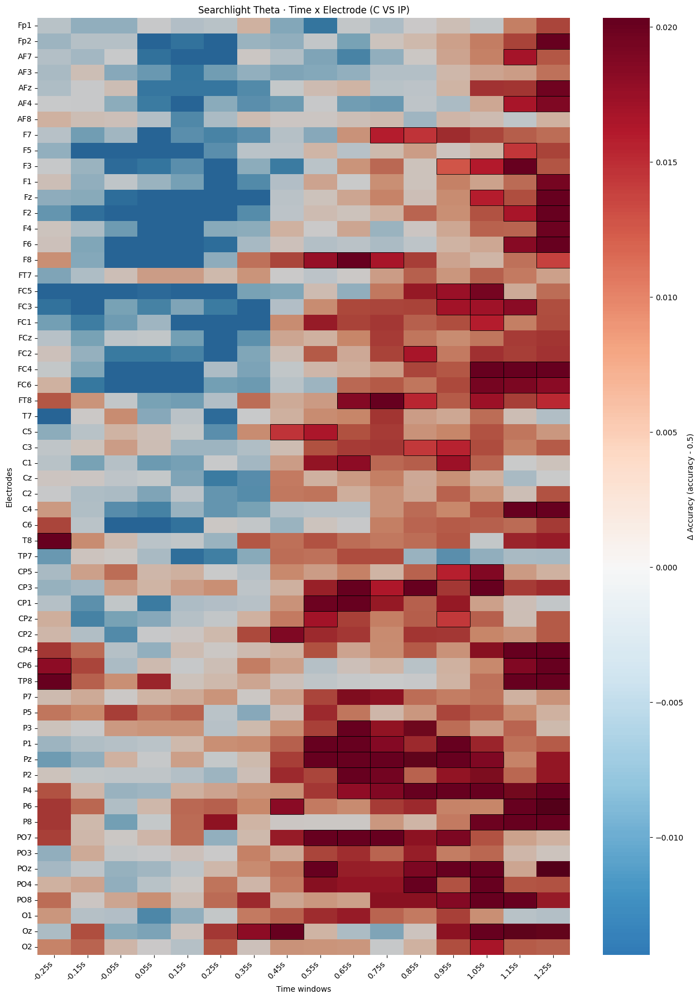

Saved Heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_heatmap_theta_c_vs_ip.png


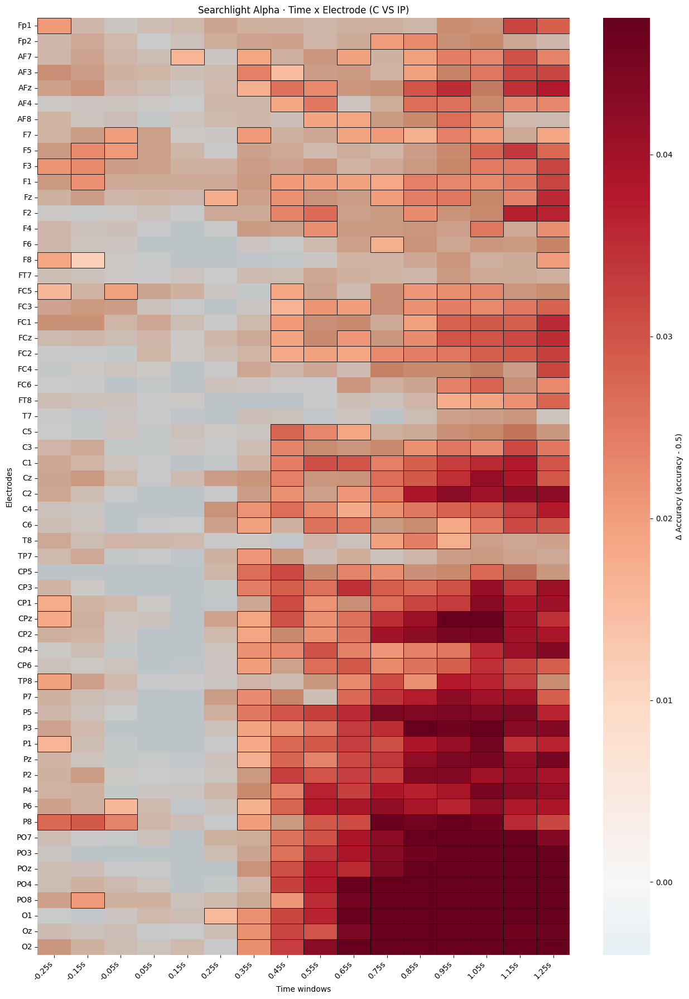

Saved Heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_heatmap_alpha_c_vs_ip.png

Calculating statistics for task: IM_VS_IP
[theta]
  Subjects: 24 | Electrodes: 60 | Windows: 16
  Significant cells (p<0.05): 189/960 | 19.7%
[alpha]
  Subjects: 24 | Electrodes: 60 | Windows: 16
  Significant cells (p<0.05): 172/960 | 17.9%


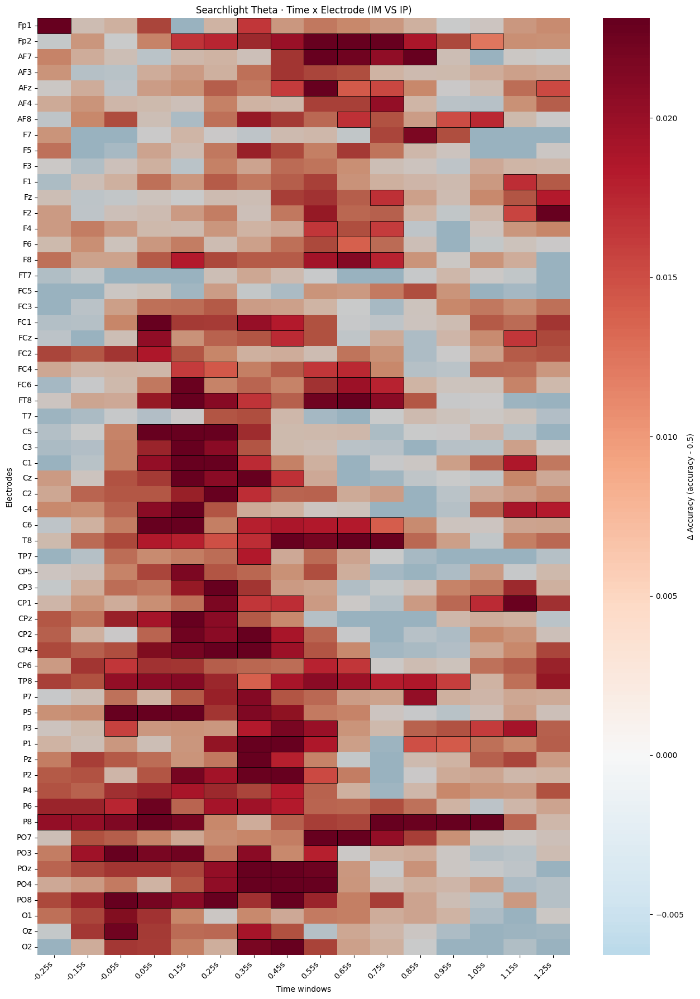

Saved Heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_heatmap_theta_im_vs_ip.png


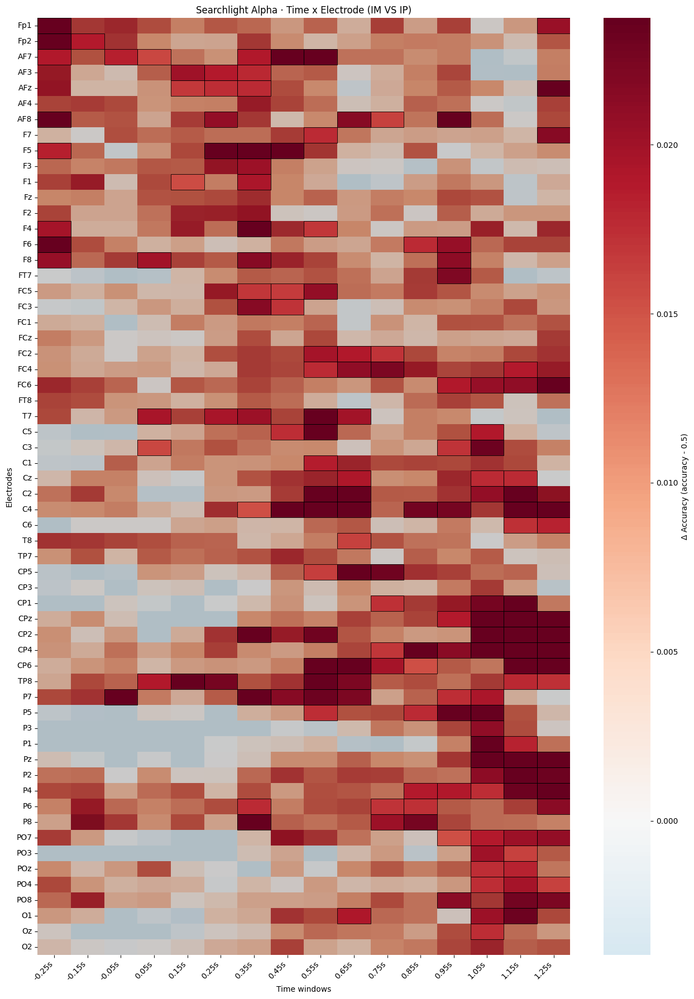

Saved Heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_heatmap_alpha_im_vs_ip.png


In [12]:
sl_stats = {}

for task in ["c_vs_ip", "im_vs_ip"]:
    sl_stats[task] = {}
    print(f"\n==========================================")
    print(f"Calculating statistics for task: {task.upper()}")
    print(f"==========================================")

    for band_name, d in sl_results[task].items():
        acc = d["acc"]  # S x C x W

        # One sample t-test against chance=0.5 (one-tailed: greater)
        t_vals, p_vals = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit", alternative="greater")

        mean_acc = np.nanmean(acc, axis=0)
        delta_acc = mean_acc - 0.5
        sig = p_vals < 0.05

        sl_stats[task][band_name] = {
            "mean_acc": mean_acc,
            "delta_acc": delta_acc,
            "p_vals": p_vals,
            "sig": sig,
            "t_vals": t_vals,
        }

        print(f"[{band_name}]")
        print(f"  Subjects: {acc.shape[0]} | Electrodes: {acc.shape[1]} | Windows: {acc.shape[2]}")
        print(f"  Significant cells (p<0.05): {int(np.sum(sig))}/{sig.size} | {100 * np.sum(sig) / sig.size:.1f}%")

    # Heatmap per band for this task
    for band_name, d in sl_results[task].items():
        ch_names = d["ch_names"]
        win_labels = d["window_labels"]
        # Convert window labels to center times or show range
        win_labels = [f"{float(win.split('-')[-1][:-1]) - 0.25:.2f}s" for win in win_labels]
        ordered_ch = CHANNEL_ORDER
        ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
        ordered_idx = [ch_to_idx[ch] for ch in ordered_ch]

        delta = sl_stats[task][band_name]["delta_acc"]
        sig = sl_stats[task][band_name]["sig"]
        delta = delta[ordered_idx, :]
        sig = sig[ordered_idx, :]

        fig, ax = plt.subplots(figsize=(max(10, len(win_labels) * 0.8), max(8, len(ordered_ch) * 0.3)))
        sns.heatmap(
            delta,
            ax=ax,
            cmap="RdBu_r",
            center=0.0,
            vmin=np.nanpercentile(delta, 5),
            vmax=np.nanpercentile(delta, 95),
            xticklabels=win_labels,
            yticklabels=ordered_ch,
            cbar_kws={"label": "Δ Accuracy (accuracy - 0.5)"},
        )

        # Highlight or darken cells based on significance
        for i in range(delta.shape[0]):
            for j in range(delta.shape[1]):
                if not sig[i, j]:
                    rect = patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.18, linewidth=0)
                    ax.add_patch(rect)
                else:
                    rect = patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=0.6)
                    ax.add_patch(rect)

        ax.set_title(f"Searchlight {band_name.capitalize()} · Time x Electrode ({task.upper().replace('_', ' ')})")
        ax.set_xlabel("Time windows")
        ax.set_ylabel("Electrodes")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()

        out_png = FIGURES_DIR / f"searchlight_heatmap_{band_name}_{task}.png"
        plt.savefig(out_png, dpi=160, bbox_inches="tight")
        plt.show()
        print(f"Saved Heatmap: {out_png}")

## 6. Sequential topomaps and GIFs

From the same average accuracy matrix, a topomap is generated per window and joined in a GIF.

In [13]:
imageio = importlib.import_module("imageio.v2")

for task in ["c_vs_ip", "im_vs_ip"]:
    print(f"\nGenerating sequential topomaps and GIFs for task: {task.upper()}")
    for band_name, d in sl_results[task].items():
        mean_acc = sl_stats[task][band_name]["mean_acc"]  # C x W
        sig = sl_stats[task][band_name]["sig"]
        centers = d["window_centers"]

        # Build robust topomap info at every run
        montage = mne.channels.make_standard_montage("standard_1020")
        available_ch = [ch for ch in d["ch_names"] if ch in montage.ch_names]

        ch_to_idx = {ch: i for i, ch in enumerate(d["ch_names"])}
        keep_idx = [ch_to_idx[ch] for ch in available_ch]

        subjects_list = sl_subjects_searchlight_c if task == "c_vs_ip" else sl_subjects_searchlight_im
        topo_info = mne.create_info(
            ch_names=available_ch,
            sfreq=float(subjects_list[0]["epochs"].info["sfreq"]),
            ch_types="eeg",
        )
        topo_info.set_montage(montage, on_missing="raise")

        band_dir = FIGURES_DIR / f"topomaps_{band_name}_{task}"
        band_dir.mkdir(parents=True, exist_ok=True)

        mean_acc_keep = mean_acc[keep_idx, :]
        sig_keep = sig[keep_idx, :]

        vmin = float(np.nanpercentile(mean_acc_keep, 5))
        vmax = float(np.nanpercentile(mean_acc_keep, 95))
        if vmax <= vmin:
            vmax = vmin + 0.01

        frame_paths = []

        for wi in range(mean_acc_keep.shape[1]):
            values = mean_acc_keep[:, wi]
            sig_mask = sig_keep[:, wi]

            fig, ax = plt.subplots(figsize=(5, 5))
            mne.viz.plot_topomap(
                values,
                topo_info,
                axes=ax,
                show=False,
                cmap="viridis",
                vlim=(vmin, vmax),
                contours=0,
                sensors=True,
                mask=sig_mask,
                mask_params={
                    "marker": "o",
                    "markerfacecolor": "none",
                    "markeredgecolor": "black",
                    "markeredgewidth": 1.8,
                    "linewidth": 0.0,
                    "markersize": 7,
                },
                sphere=(0.0, 0.02, 0.0, 0.096),
                extrapolate="local",
            )
            ax.set_title(f"{band_name.capitalize()} | t={centers[wi]:.2f}s ({task.upper().replace('_', ' ')})")

            out_frame = band_dir / f"frame_{wi:02d}.png"
            plt.savefig(out_frame, dpi=160, bbox_inches="tight")
            plt.close(fig)
            frame_paths.append(out_frame)

        gif_path = FIGURES_DIR / f"searchlight_{band_name}_{task}.gif"
        images = [imageio.imread(p) for p in frame_paths]
        imageio.mimsave(gif_path, images, duration=0.5, loop=0)
        print(f"Saved GIF: {gif_path}")

        # Figure with all topomaps in a single image grid
        n_cols = 4
        n_rows = int(np.ceil(mean_acc_keep.shape[1] / n_cols))
        fig = plt.figure(figsize=(4.5 * n_cols + 2.5, 4.6 * n_rows))

        # Create grid for topomaps with space for legend and colorbar
        gs = fig.add_gridspec(n_rows, n_cols + 1, width_ratios=[1] * n_cols + [0.3], wspace=0.3, hspace=0.4)
        axes_topo = [fig.add_subplot(gs[i, j]) for i in range(n_rows) for j in range(n_cols)]

        for wi in range(mean_acc_keep.shape[1]):
            ax = axes_topo[wi]
            values = mean_acc_keep[:, wi]
            sig_mask = sig_keep[:, wi]

            mne.viz.plot_topomap(
                values,
                topo_info,
                axes=ax,
                show=False,
                cmap="viridis",
                vlim=(vmin, vmax),
                contours=0,
                sensors=True,
                mask=sig_mask,
                mask_params={
                    "marker": "o",
                    "markerfacecolor": "none",
                    "markeredgecolor": "black",
                    "markeredgewidth": 1.8,
                    "linewidth": 0.0,
                    "markersize": 7,
                },
                sphere=(0.0, 0.02, 0.0, 0.096),
                extrapolate="local",
            )
            ax.set_title(f"t={centers[wi]:.2f}s", fontsize=18)

        # Clear remaining unused axes in the grid
        for wi in range(mean_acc_keep.shape[1], len(axes_topo)):
            axes_topo[wi].axis("off")

        # Colorbar and Legend on the right
        ax_cbar = fig.add_subplot(gs[:, n_cols])
        ax_cbar.axis("off")

        norm_cbar = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
        sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm_cbar)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_cbar, fraction=0.4, aspect=20, pad=0.01)
        cbar.set_label("Accuracy", fontsize=20, labelpad=15)
        cbar.ax.tick_params(labelsize=16)

        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                markerfacecolor="none",
                markeredgecolor="black",
                markeredgewidth=1.8,
                markersize=12,
                linewidth=0,
                label="p < 0.05 (one-tailed)",
            )
        ]
        ax_cbar.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(0.1, 0.1), frameon=True, fontsize=16)

        fig.suptitle(
            f"Searchlight Spatiotemporal Evolution ({band_name.capitalize()}) - {task.upper().replace('_', ' ')}",
            fontsize=24,
            fontweight="bold",
            y=0.98,
        )

        out_grid = FIGURES_DIR / f"searchlight_topoplots_grid_{band_name}_{task}.png"
        plt.savefig(out_grid, dpi=180, bbox_inches="tight")
        plt.close(fig)
        print(f"Saved topoplots grid: {out_grid}")


Generating sequential topomaps and GIFs for task: C_VS_IP


Saved GIF: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_c_vs_ip.gif
Saved topoplots grid: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_topoplots_grid_theta_c_vs_ip.png
Saved GIF: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_c_vs_ip.gif
Saved topoplots grid: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_topoplots_grid_alpha_c_vs_ip.png

Generating sequential topomaps and GIFs for task: IM_VS_IP
Saved GIF: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_im_vs_ip.gif
Saved topoplots grid: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\

In [14]:
# 6b. Group-level T-value Topoplots
print("\nGenerating group-level T-value topoplots at target windows...")

target_times = [0.25, 0.45, 0.75, 0.95, 1.25]
time_ranges = {0.25: "0.0–0.5s", 0.45: "0.2–0.7s", 0.75: "0.5–1.0s", 0.95: "0.7–1.2s", 1.25: "1.0–1.5s"}

# 1. First, calculate the global range of t-values across all tasks, bands, and target windows for a shared colorbar
all_t_values = []
for task in ["c_vs_ip", "im_vs_ip"]:
    for band_name in ["theta", "alpha"]:
        d = sl_results[task][band_name]
        centers = d["window_centers"]
        t_vals = sl_stats[task][band_name]["t_vals"]
        for t_target in target_times:
            wi = np.argmin(np.abs(centers - t_target))
            all_t_values.extend(t_vals[:, wi])

all_t_values = np.array(all_t_values)
t_max = float(np.nanmax(np.abs(all_t_values)))
# Use a symmetric range centered at 0 for diverging colormap
vlim_t = (-t_max, t_max)

# 2. Plot the topoplots
montage = mne.channels.make_standard_montage("standard_1020")

for task in ["c_vs_ip", "im_vs_ip"]:
    for band_name in ["theta", "alpha"]:
        d = sl_results[task][band_name]
        centers = d["window_centers"]
        t_vals = sl_stats[task][band_name]["t_vals"]
        p_vals = sl_stats[task][band_name]["p_vals"]

        available_ch = [ch for ch in d["ch_names"] if ch in montage.ch_names]
        ch_to_idx = {ch: i for i, ch in enumerate(d["ch_names"])}
        keep_idx = [ch_to_idx[ch] for ch in available_ch]

        subjects_list = sl_subjects_searchlight_c if task == "c_vs_ip" else sl_subjects_searchlight_im
        topo_info = mne.create_info(
            ch_names=available_ch,
            sfreq=float(subjects_list[0]["epochs"].info["sfreq"]),
            ch_types="eeg",
        )
        topo_info.set_montage(montage, on_missing="raise")

        fig, axes = plt.subplots(1, 5, figsize=(18, 4), constrained_layout=True)

        for idx, t_target in enumerate(target_times):
            wi = np.argmin(np.abs(centers - t_target))
            actual_center = centers[wi]

            # Extract t-values and p-values for available channels
            t_win = t_vals[keep_idx, wi]
            p_win = p_vals[keep_idx, wi]

            # Significance mask (one-tailed p < 0.05)
            sig_mask = p_win < 0.05

            im, _ = mne.viz.plot_topomap(
                t_win,
                topo_info,
                axes=axes[idx],
                show=False,
                cmap="RdBu_r",
                vlim=vlim_t,
                contours=0,
                sensors=True,
                mask=sig_mask,
                mask_params={
                    "marker": "o",
                    "markerfacecolor": "none",
                    "markeredgecolor": "black",
                    "markeredgewidth": 1.8,
                    "linewidth": 0.0,
                    "markersize": 7,
                },
                sphere=(0.0, 0.02, 0.0, 0.096),
                extrapolate="local",
            )
            axes[idx].set_title(f"t = {t_target:.2f}s\n({time_ranges[t_target]})", fontsize=12)

        # Add shared colorbar to the figure
        cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, aspect=20, pad=0.02)
        cbar.set_label("t-value (vs chance = 0.5)", fontsize=12)

        # Add legend for significance
        legend_elements = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                markerfacecolor="none",
                markeredgecolor="black",
                markeredgewidth=1.8,
                markersize=8,
                linewidth=0,
                label="p < 0.05 (one-tailed)",
            )
        ]
        fig.legend(handles=legend_elements, loc="lower right", bbox_to_anchor=(0.95, 0.1), frameon=True, fontsize=10)

        fig.suptitle(
            f"Electrode Importance (T-Values) - {band_name.capitalize()} Band - {task.upper().replace('_', ' ')}",
            fontsize=16,
            fontweight="bold",
            y=1.05,
        )

        out_png = FIGURES_DIR / f"t_value_topoplots_{band_name}_{task}.png"
        plt.savefig(out_png, dpi=300, bbox_inches="tight")
        plt.close(fig)
        print(f"Saved t-value topoplots: {out_png}")


Generating group-level T-value topoplots at target windows...
Saved t-value topoplots: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\t_value_topoplots_theta_c_vs_ip.png
Saved t-value topoplots: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\t_value_topoplots_alpha_c_vs_ip.png
Saved t-value topoplots: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\t_value_topoplots_theta_im_vs_ip.png
Saved t-value topoplots: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\t_value_topoplots_alpha_im_vs_ip.png


## 7. Alpha vs Theta Dominance

At what times and in which areas of the head is the Alpha band more dominant than the Theta (or vice versa) to discriminate C vs IP and IM vs IP?



Alpha vs Theta dominance for task: C_VS_IP


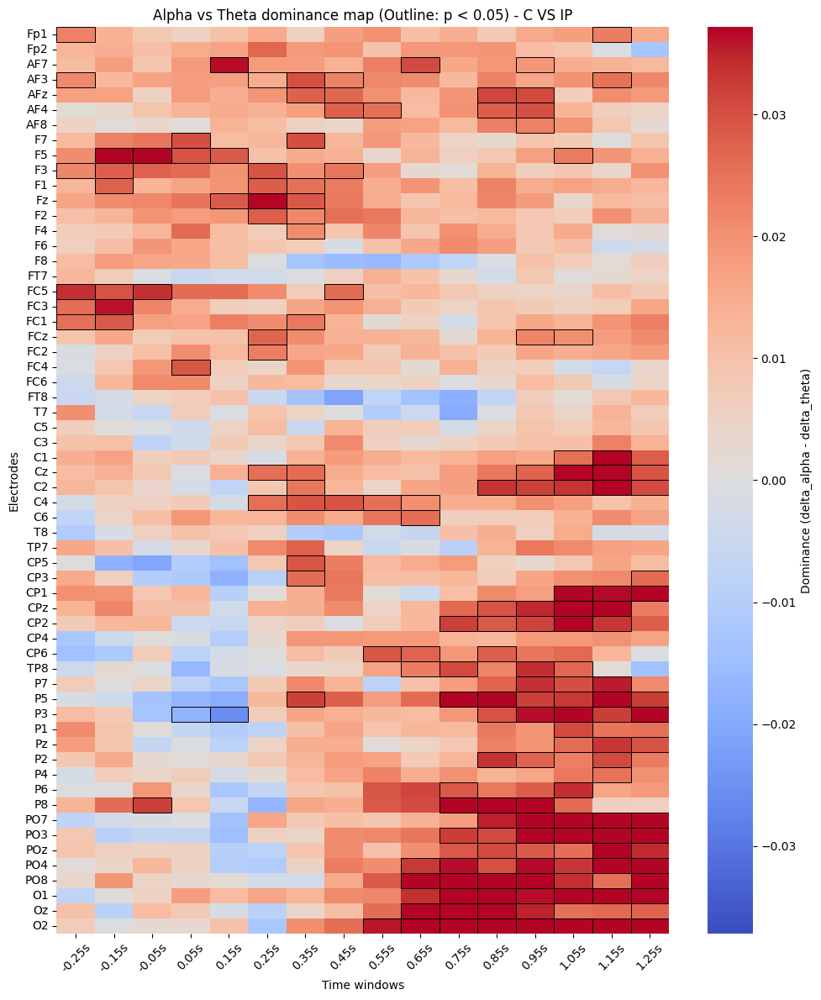

Saved heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_vs_theta_dominance_heatmap_c_vs_ip.png


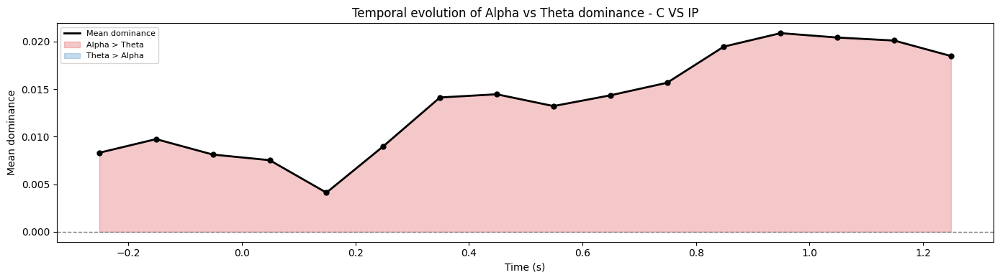

Saved curve: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_vs_theta_dominance_curve_c_vs_ip.png

Alpha vs Theta dominance for task: IM_VS_IP


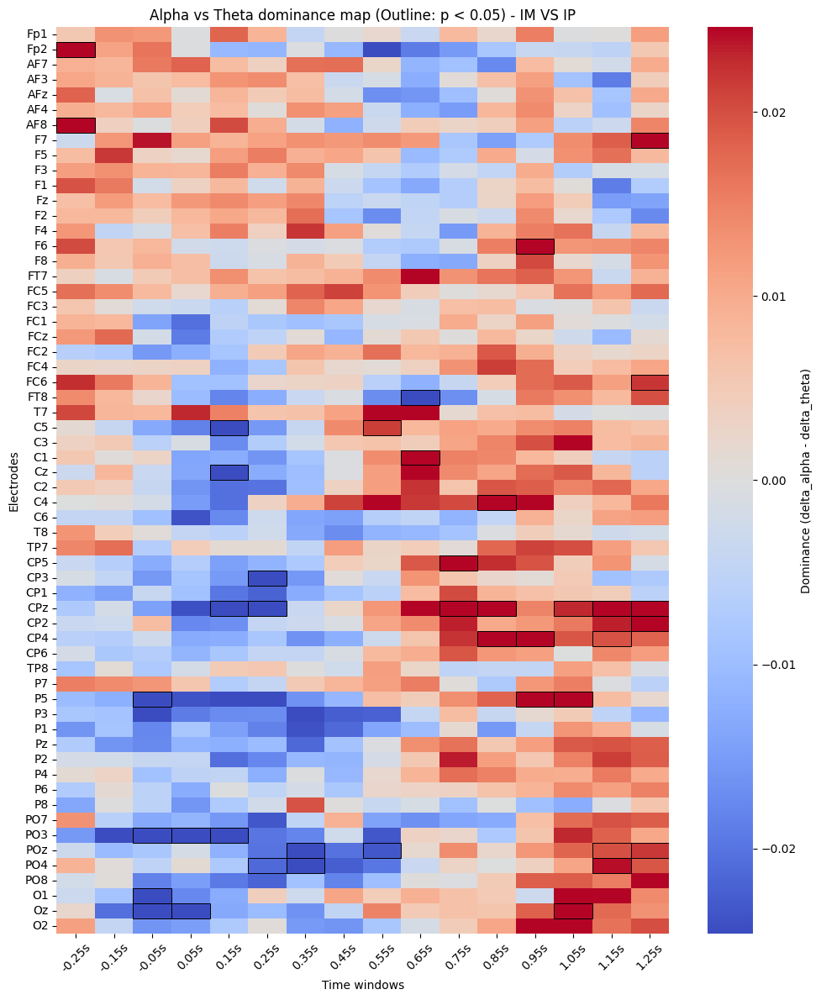

Saved heatmap: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_vs_theta_dominance_heatmap_im_vs_ip.png


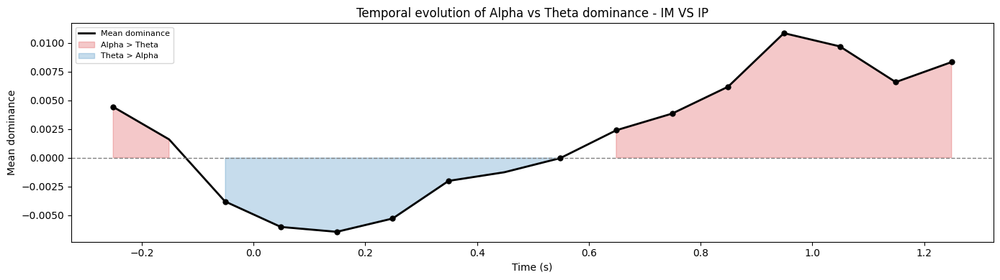

Saved curve: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_vs_theta_dominance_curve_im_vs_ip.png


In [15]:
for task in ["c_vs_ip", "im_vs_ip"]:
    print(f"\n==========================================")
    print(f"Alpha vs Theta dominance for task: {task.upper()}")
    print(f"==========================================")

    alpha_delta = sl_stats[task]["alpha"]["delta_acc"]
    theta_delta = sl_stats[task]["theta"]["delta_acc"]
    dominance = alpha_delta - theta_delta  # >0: alpha dominates, <0: theta dominates

    alpha_acc = sl_results[task]["alpha"]["acc"]  # S x C x W
    theta_acc = sl_results[task]["theta"]["acc"]
    diff_subj = alpha_acc - theta_acc
    _, p_dom = ttest_1samp(diff_subj, popmean=0.0, axis=0, nan_policy="omit", alternative="two-sided")
    sig_dom = p_dom < 0.05

    win_labels = [f"{center:.2f}s" for center in sl_results[task]["alpha"]["window_centers"]]
    ch_names = sl_results[task]["alpha"]["ch_names"]
    ordered_ch = CHANNEL_ORDER
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    ordered_idx = [ch_to_idx[ch] for ch in ordered_ch]
    centers = sl_results[task]["alpha"]["window_centers"]

    # Plot 1: dominance heatmap
    fig, ax = plt.subplots(figsize=(10, 12))
    vmax = float(np.nanpercentile(np.abs(dominance), 95))
    if vmax == 0:
        vmax = 0.01
    dominance_plot = dominance[ordered_idx, :]
    sig_dom_plot = sig_dom[ordered_idx, :]
    sns.heatmap(
        dominance_plot,
        ax=ax,
        cmap="coolwarm",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=win_labels,
        yticklabels=ordered_ch,
        cbar_kws={"label": "Dominance (delta_alpha - delta_theta)"},
    )

    for i in range(dominance_plot.shape[0]):
        for j in range(dominance_plot.shape[1]):
            if sig_dom_plot[i, j]:
                ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor="black", linewidth=0.7))

    ax.set_title(f"Alpha vs Theta dominance map (Outline: p < 0.05) - {task.upper().replace('_', ' ')}")
    ax.set_xlabel("Time windows")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    out_dom_heat = FIGURES_DIR / f"searchlight_alpha_vs_theta_dominance_heatmap_{task}.png"
    plt.savefig(out_dom_heat, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved heatmap: {out_dom_heat}")

    # Plot 2: temporal curve of dominance
    fig, ax = plt.subplots(figsize=(14, 4))
    dom_mean_t = np.nanmean(dominance_plot, axis=0)
    sig_t = np.any(sig_dom_plot, axis=0)

    ax.plot(centers, dom_mean_t, color="black", linewidth=2, label="Mean dominance")
    ax.fill_between(centers, 0, dom_mean_t, where=dom_mean_t >= 0, color="tab:red", alpha=0.25, label="Alpha > Theta")
    ax.fill_between(centers, 0, dom_mean_t, where=dom_mean_t < 0, color="tab:blue", alpha=0.25, label="Theta > Alpha")
    ax.scatter(centers[sig_t], dom_mean_t[sig_t], color="black", s=25, zorder=3, label="")
    ax.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Mean dominance")
    ax.set_title(f"Temporal evolution of Alpha vs Theta dominance - {task.upper().replace('_', ' ')}")
    ax.legend(loc="best", fontsize=8)
    plt.tight_layout()

    out_dom_curve = FIGURES_DIR / f"searchlight_alpha_vs_theta_dominance_curve_{task}.png"
    plt.savefig(out_dom_curve, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved curve: {out_dom_curve}")

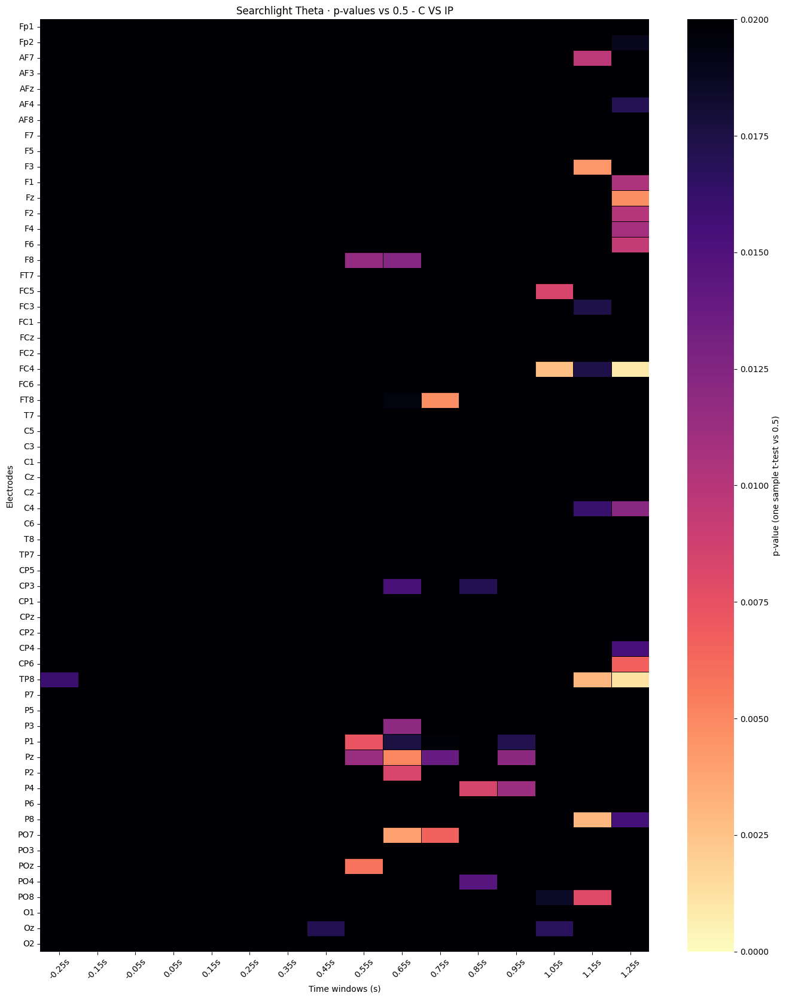

P-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_pvalues_heatmap_c_vs_ip.png


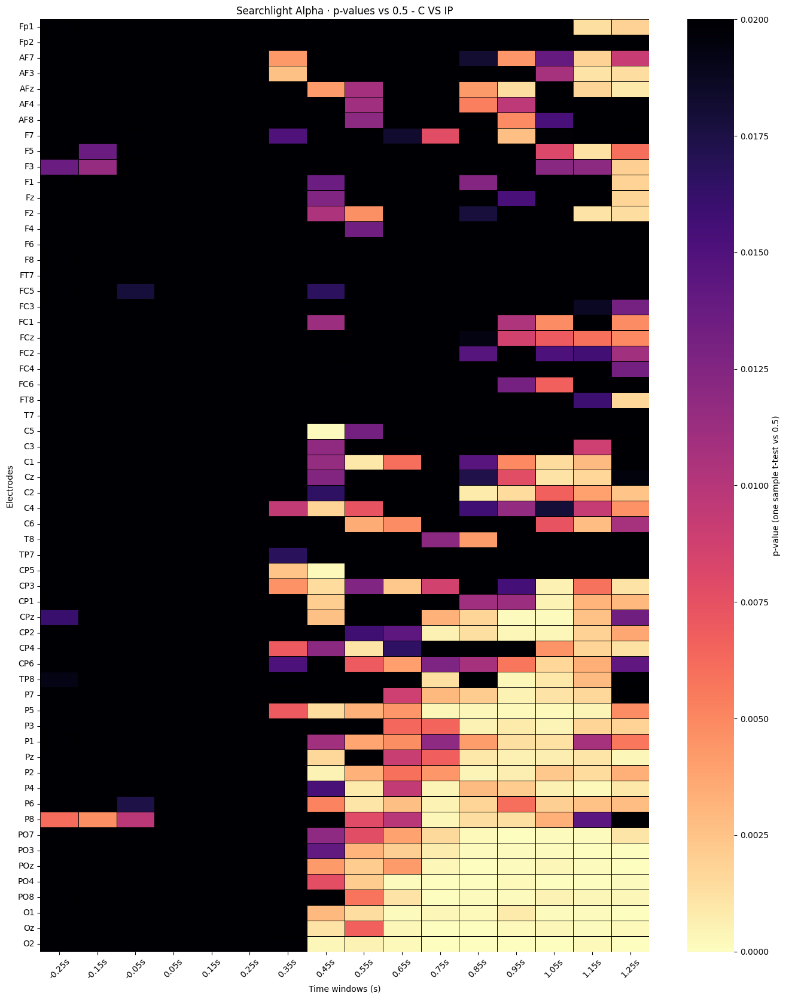

P-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_pvalues_heatmap_c_vs_ip.png


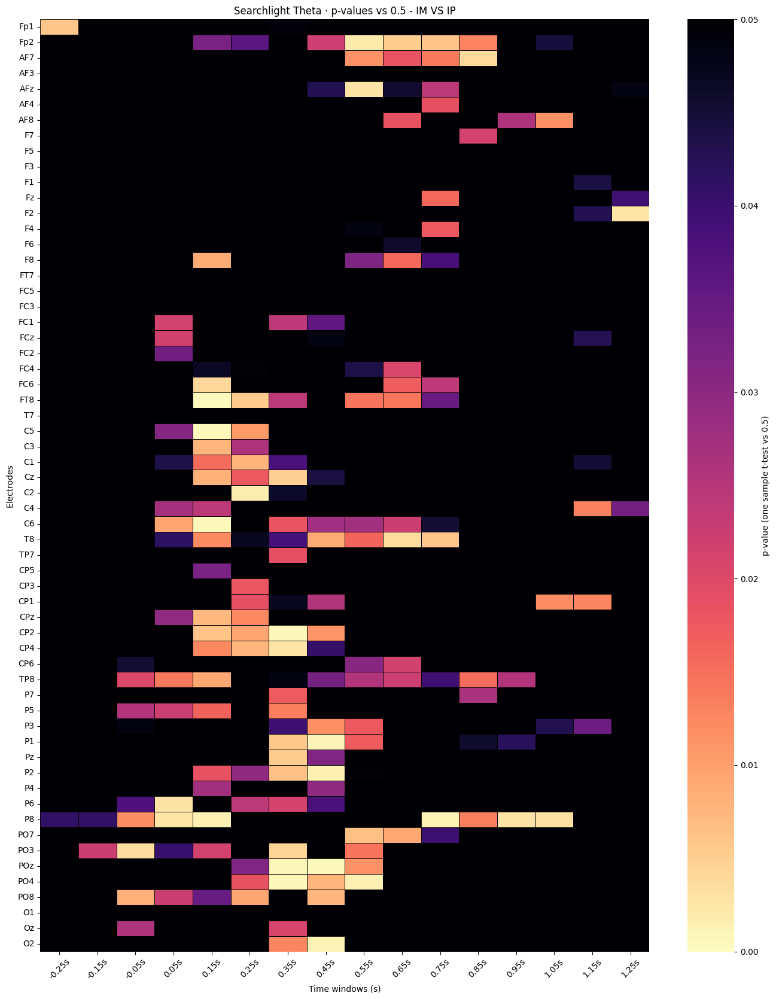

P-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_pvalues_heatmap_im_vs_ip.png


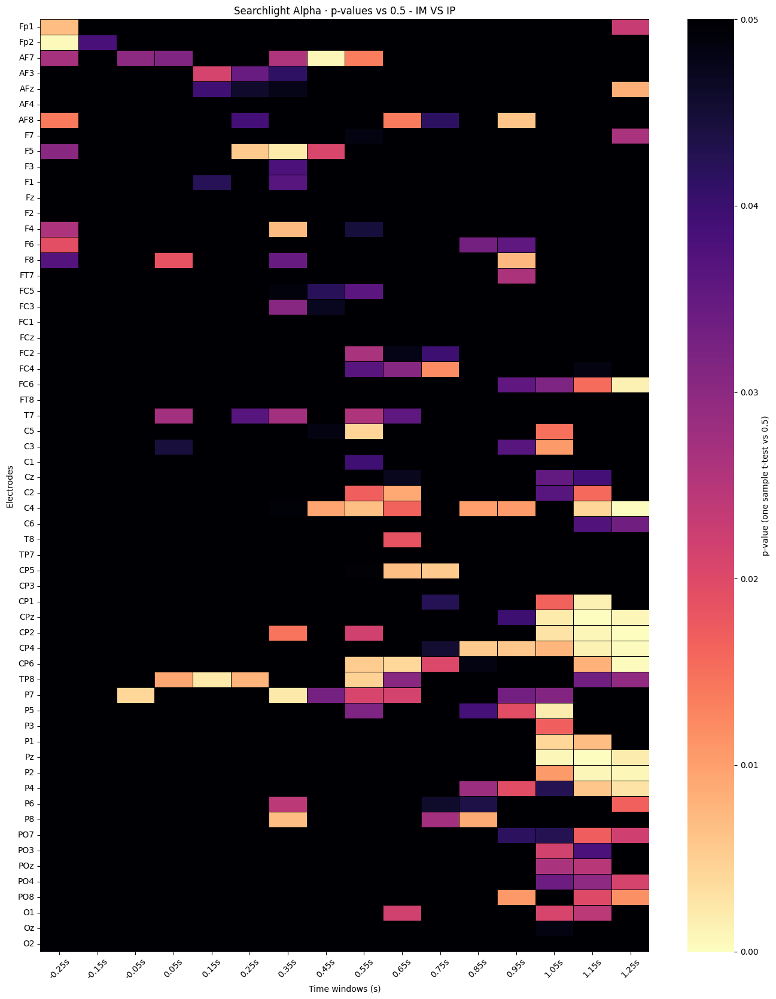

P-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_pvalues_heatmap_im_vs_ip.png


In [16]:
# P-value searchlight plots: paired t-test vs chance level (0.5)


def sl_plot_band_pvalues(task, band_name, out_path):
    acc = sl_results[task][band_name]["acc"]
    ch_names = sl_results[task][band_name]["ch_names"]
    win_labels = [f"{center:.2f}s" for center in sl_results[task][band_name]["window_centers"]]

    # One-sample t-test contra chance level (0.5).
    _, p_vals = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit", alternative="greater")

    ordered_ch = CHANNEL_ORDER
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    ordered_idx = [ch_to_idx[ch] for ch in ordered_ch]
    p_ordered = p_vals[ordered_idx, :]

    fig, ax = plt.subplots(figsize=(max(12, len(win_labels) * 0.85), max(8, len(ordered_ch) * 0.28)))
    sns.heatmap(
        p_ordered,
        ax=ax,
        cmap="magma_r",
        vmin=0.0,
        vmax=0.02 if task == "c_vs_ip" else 0.05,
        xticklabels=win_labels,
        yticklabels=ordered_ch,
        cbar_kws={"label": "p-value (one sample t-test vs 0.5)"},
    )

    for i in range(p_ordered.shape[0]):
        for j in range(p_ordered.shape[1]):
            if p_ordered[i, j] < 0.05:
                ax.add_patch(
                    patches.Rectangle(
                        (j, i),
                        1,
                        1,
                        fill=False,
                        edgecolor="black",
                        linewidth=0.6,
                    )
                )

    ax.set_title(f"Searchlight {band_name.capitalize()} · p-values vs 0.5 - {task.upper().replace('_', ' ')}")
    ax.set_xlabel("Time windows (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"P-value heatmap saved: {out_path}")


for task in ["c_vs_ip", "im_vs_ip"]:
    for band_name in ["theta", "alpha"]:
        out_path = FIGURES_DIR / f"searchlight_{band_name}_pvalues_heatmap_{task}.png"
        sl_plot_band_pvalues(task, band_name, out_path)

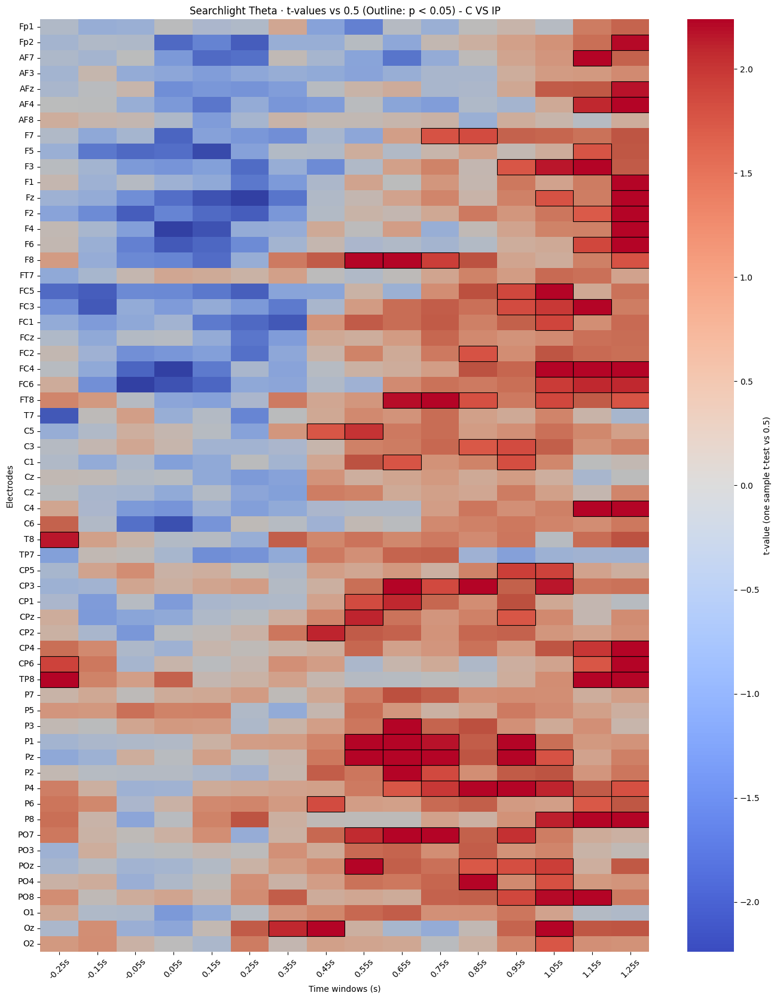

t-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_tvalues_heatmap_c_vs_ip.png


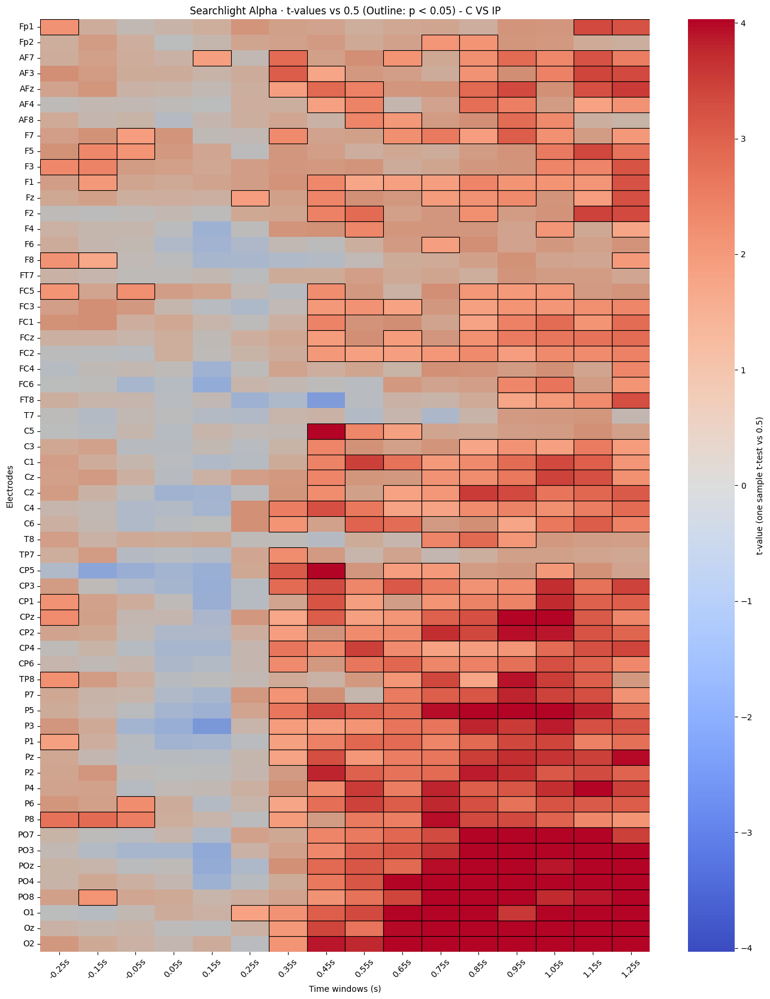

t-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_tvalues_heatmap_c_vs_ip.png


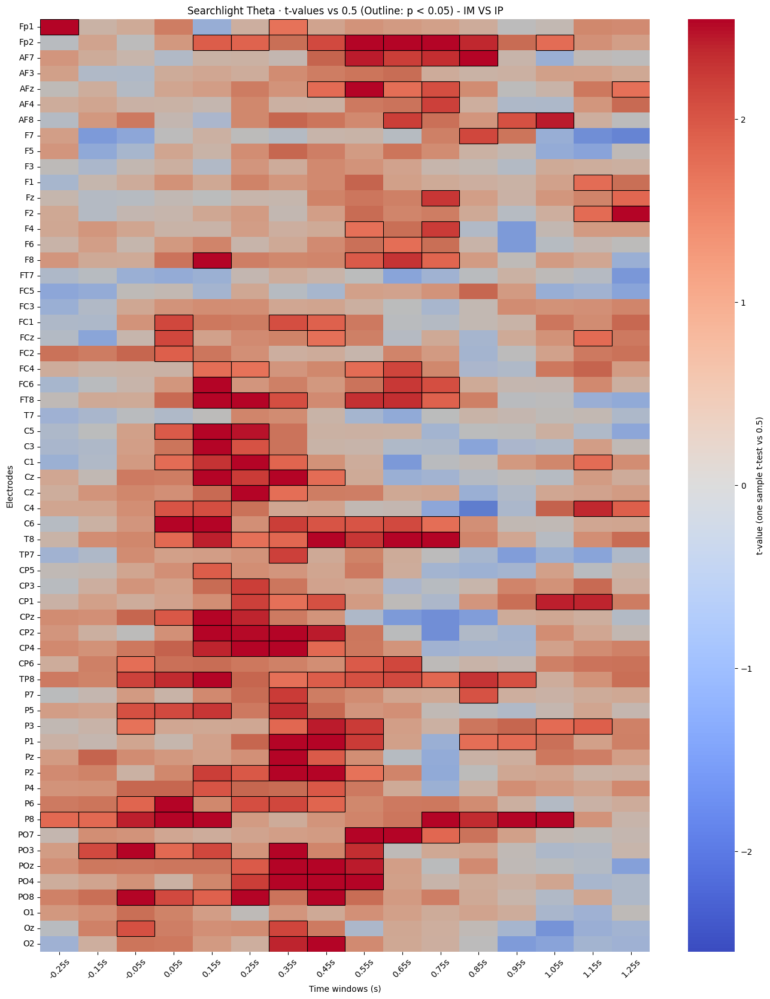

t-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_tvalues_heatmap_im_vs_ip.png


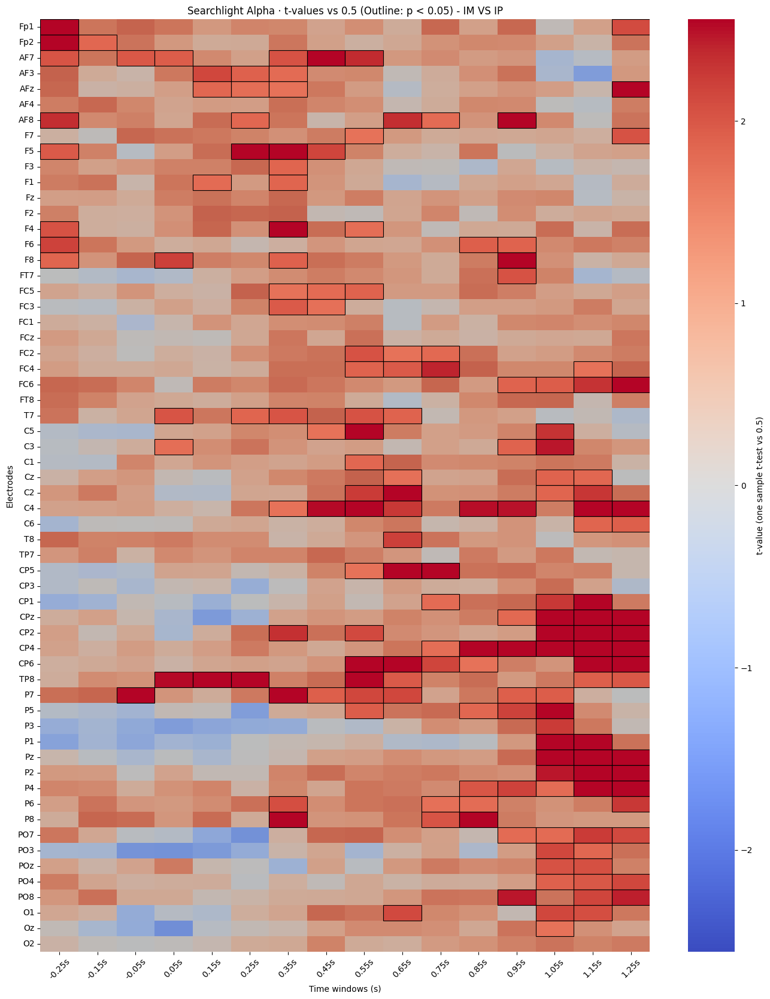

t-value heatmap saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_tvalues_heatmap_im_vs_ip.png


In [17]:
# 8b. Searchlight t-values heatmap


def sl_plot_band_tvalues(task, band_name, out_path):
    acc = sl_results[task][band_name]["acc"]
    ch_names = sl_results[task][band_name]["ch_names"]
    win_labels = [f"{center:.2f}s" for center in sl_results[task][band_name]["window_centers"]]

    # One-sample t-test contra chance level (0.5).
    t_vals, p_vals = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit", alternative="greater")

    ordered_ch = CHANNEL_ORDER
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    ordered_idx = [ch_to_idx[ch] for ch in ordered_ch]
    t_ordered = t_vals[ordered_idx, :]
    p_ordered = p_vals[ordered_idx, :]

    fig, ax = plt.subplots(figsize=(max(12, len(win_labels) * 0.85), max(8, len(ordered_ch) * 0.28)))
    vmax = float(np.nanpercentile(np.abs(t_ordered), 95))
    if vmax == 0:
        vmax = 1.0
    sns.heatmap(
        t_ordered,
        ax=ax,
        cmap="coolwarm",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=win_labels,
        yticklabels=ordered_ch,
        cbar_kws={"label": "t-value (one sample t-test vs 0.5)"},
    )

    for i in range(t_ordered.shape[0]):
        for j in range(t_ordered.shape[1]):
            if p_ordered[i, j] < 0.05:
                ax.add_patch(
                    patches.Rectangle(
                        (j, i),
                        1,
                        1,
                        fill=False,
                        edgecolor="black",
                        linewidth=0.8,
                    )
                )
            else:
                rect = patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.15, linewidth=0)
                ax.add_patch(rect)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · t-values vs 0.5 (Outline: p < 0.05) - {task.upper().replace('_', ' ')}"
    )
    ax.set_xlabel("Time windows (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"t-value heatmap saved: {out_path}")


for task in ["c_vs_ip", "im_vs_ip"]:
    for band_name in ["theta", "alpha"]:
        out_path = FIGURES_DIR / f"searchlight_{band_name}_tvalues_heatmap_{task}.png"
        sl_plot_band_tvalues(task, band_name, out_path)

In [18]:
def sl_plot_band_clustering(task, band_name, out_path, min_time_points=3):
    acc = sl_results[task][band_name]["acc"]  # S x C x W
    ch_names = sl_results[task][band_name]["ch_names"]
    win_labels = [f"{center:.2f}s" for center in sl_results[task][band_name]["window_centers"]]
    win_centers = sl_results[task][band_name]["window_centers"]

    # Transpose to (subjects, windows, channels) and subtract chance level (0.5)
    X = np.transpose(acc, (0, 2, 1)) - 0.5

    # Calculate spatial adjacency using MNE standard_1005 (10-10 system)
    sfreq = float(sl_subjects_searchlight[0]["epochs"].info["sfreq"])
    dummy_info = mne.create_info(ch_names=ch_names, sfreq=sfreq, ch_types="eeg")
    montage = mne.channels.make_standard_montage("standard_1005")
    dummy_info.set_montage(montage, on_missing="ignore")

    print(f"\n[{task.upper()} - {band_name}] Calculating spatial adjacency with standard_1005...")
    adjacency, _ = mne.channels.find_ch_adjacency(dummy_info, "eeg")

    # Run spatio-temporal cluster permutation 1-sample t-test
    print(f"[{task.upper()} - {band_name}] Running spatio-temporal cluster test (tail=1)...")
    t_obs, clusters, cluster_p_values, H0 = mne.stats.spatio_temporal_cluster_1samp_test(
        X, adjacency=adjacency, n_permutations=1000, tail=1, out_type="mask", verbose=False, seed=RANDOM_STATE
    )

    n_windows, n_channels = X.shape[1], X.shape[2]
    sig_cluster_mask = np.zeros((n_windows, n_channels), dtype=bool)

    n_sig_clusters = 0
    for cluster, p_val in zip(clusters, cluster_p_values):
        if p_val < 0.05:
            filtered_cluster = cluster.copy()
            # Filter out electrodes active in < min_time_points (lone wolf electrodes)
            for ch_idx in range(n_channels):
                if np.sum(filtered_cluster[:, ch_idx]) < min_time_points:
                    filtered_cluster[:, ch_idx] = False
            sig_cluster_mask = sig_cluster_mask | filtered_cluster
            n_sig_clusters += 1
            print(f"  Significant cluster found! p-value: {p_val:.4f}")

    print(f"  Total significant clusters: {n_sig_clusters}")

    # Find surviving electrodes and their durations
    surviving_chs = []
    for ch_idx in range(n_channels):
        cnt = np.sum(sig_cluster_mask[:, ch_idx])
        if cnt > 0:
            surviving_chs.append((ch_names[ch_idx], cnt))
    # Sort by duration descending
    surviving_chs.sort(key=lambda x: x[1], reverse=True)

    print(f"  Surviving electrodes ({len(surviving_chs)} channels with min_time_points={min_time_points}):")
    print(f"    " + ", ".join([f"{ch} ({cnt}w)" for ch, cnt in surviving_chs]))

    # Transpose mask back to (channels, windows)
    sig_mask_ordered = sig_cluster_mask.T

    # Reorder channels for the plot
    ordered_ch = CHANNEL_ORDER
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    ordered_idx = [ch_to_idx[ch] for ch in ordered_ch]
    sig_mask_ordered = sig_mask_ordered[ordered_idx, :]

    # Plot t-values showing clusters
    t_vals, _ = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit", alternative="greater")
    t_ordered = t_vals[ordered_idx, :]

    fig, ax = plt.subplots(figsize=(max(12, len(win_labels) * 0.85), max(8, len(ordered_ch) * 0.28)))
    vmax = float(np.nanpercentile(np.abs(t_ordered), 95))
    if vmax == 0:
        vmax = 1.0
    sns.heatmap(
        t_ordered,
        ax=ax,
        cmap="coolwarm",
        center=0.0,
        vmin=-vmax,
        vmax=vmax,
        xticklabels=win_labels,
        yticklabels=ordered_ch,
        cbar_kws={"label": "t-value (t-test vs 0.5)"},
    )

    for i in range(t_ordered.shape[0]):
        for j in range(t_ordered.shape[1]):
            if sig_mask_ordered[i, j]:
                ax.add_patch(
                    patches.Rectangle(
                        (j, i),
                        1,
                        1,
                        fill=False,
                        edgecolor="black",
                        linewidth=1.2,
                    )
                )
            else:
                rect = patches.Rectangle((j, i), 1, 1, fill=True, color="black", alpha=0.22, linewidth=0)
                ax.add_patch(rect)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · Spatio-Temporal Clusters (min_time_points={min_time_points}, p < 0.05) - {task.upper().replace('_', ' ')}"
    )
    ax.set_xlabel("Time windows (s)")
    ax.set_ylabel("Electrodes")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()

    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Cluster heatmap saved to: {out_path}")

    # Plot topomap representation
    topo_path = out_path.parent / out_path.name.replace("heatmap", "topomap")
    active_windows = np.where(np.sum(sig_cluster_mask, axis=1) > 0)[0]
    if len(active_windows) == 0:
        # If no significant clusters, average over post-stimulus windows (>= 0.0s)
        active_windows = np.where(win_centers >= 0.0)[0]
        if len(active_windows) == 0:
            active_windows = np.arange(len(win_centers))

    t_avg = np.mean(t_vals[:, active_windows], axis=1)

    sig_channels = [ch_to_idx[ch] for ch, _ in surviving_chs]
    sig_mask = np.zeros(len(ch_names), dtype=bool)
    sig_mask[sig_channels] = True

    fig, ax = plt.subplots(figsize=(5, 5))
    mne.viz.plot_topomap(
        t_avg,
        dummy_info,
        axes=ax,
        mask=sig_mask,
        mask_params=dict(marker="o", markerfacecolor="red", markersize=6, markeredgecolor="k"),
        cmap="coolwarm",
        show=False,
    )
    ax.set_title(f"Cluster Topomap: {task.upper()} - {band_name.capitalize()}")
    plt.tight_layout()
    plt.savefig(topo_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Cluster topomap saved to: {topo_path}")

    return [ch for ch, _ in surviving_chs]

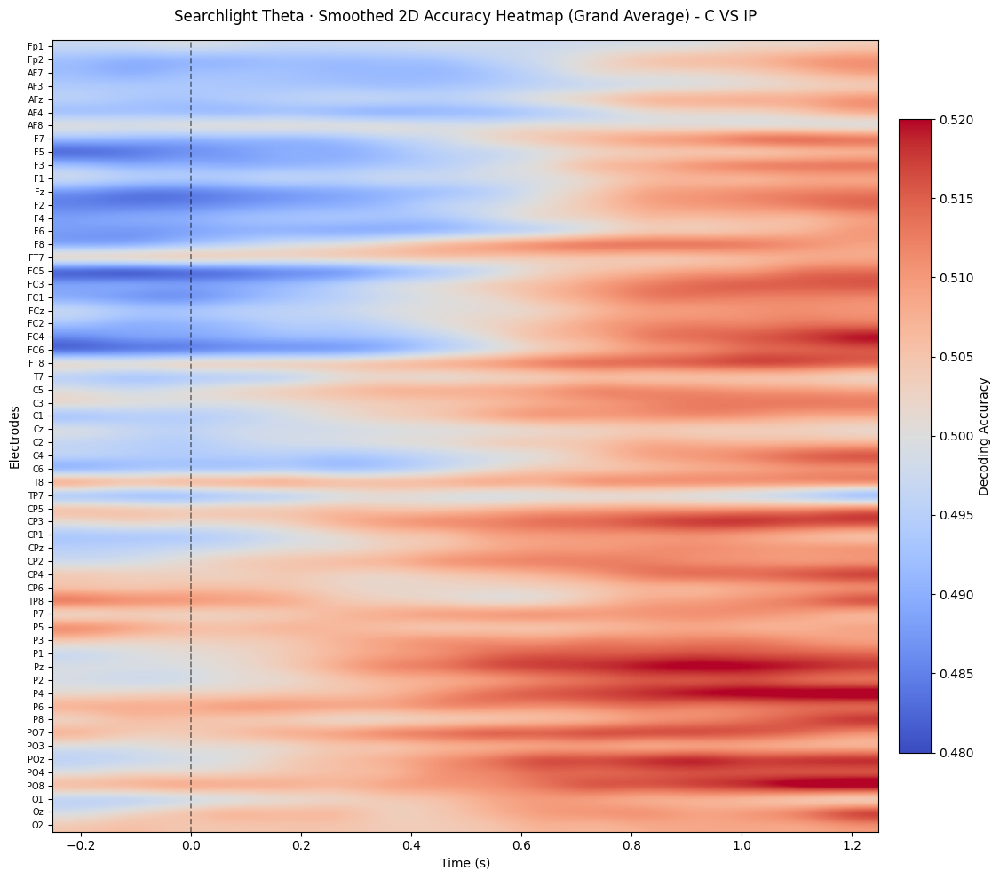

Continuous Grand Average saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_grand_average_c_vs_ip.png (vmin=0.48, vmax=0.52)


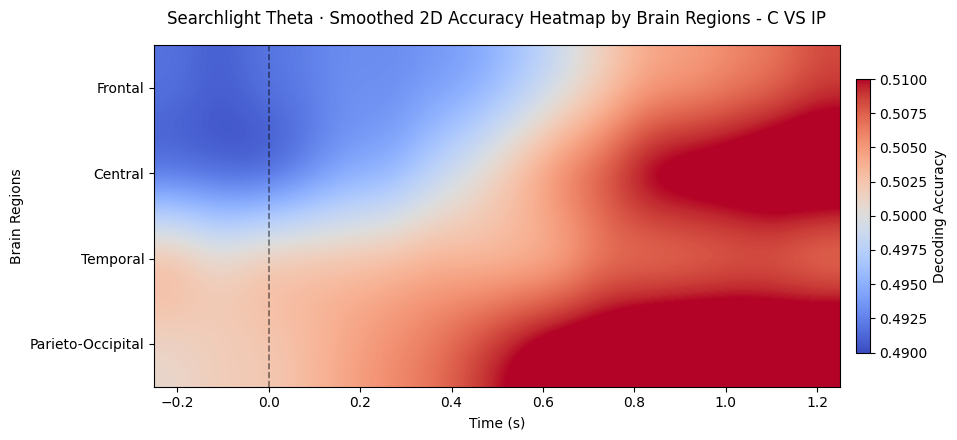

Continuous Regional Evolution saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_regional_c_vs_ip.png (vmin=0.49, vmax=0.51)


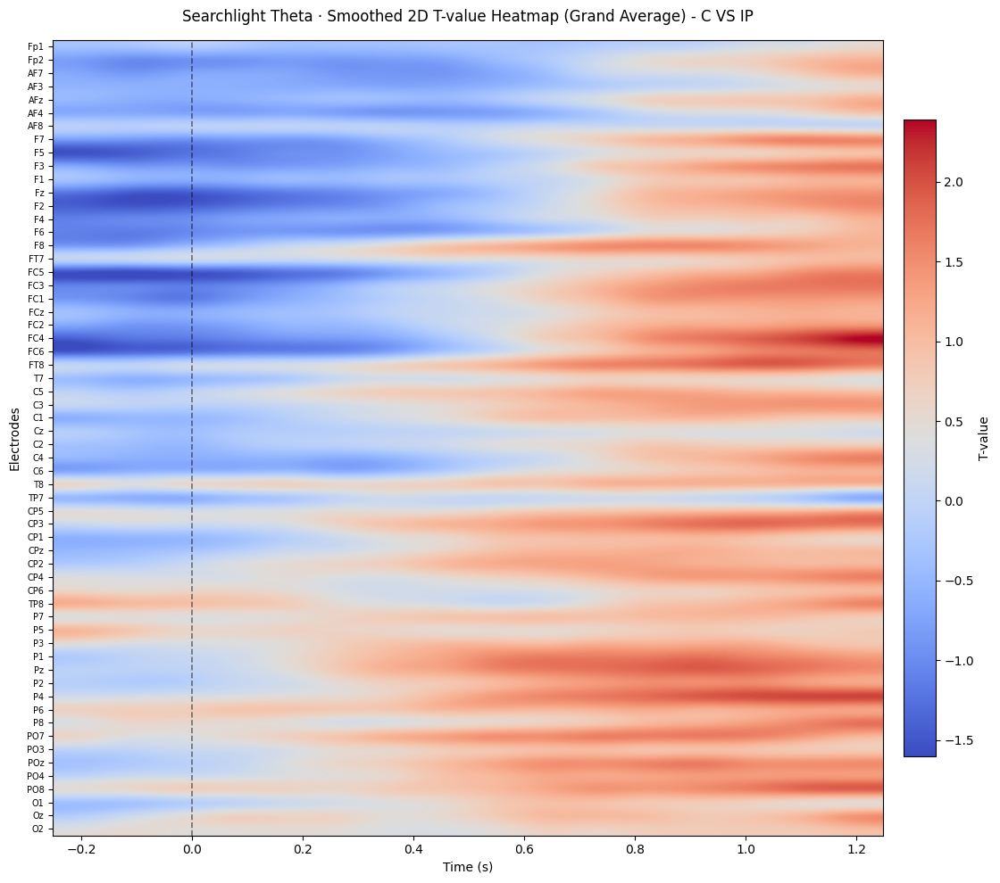

Continuous Grand Average T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_grand_average_tval_c_vs_ip.png (vmin=-1.6, vmax=2.39)


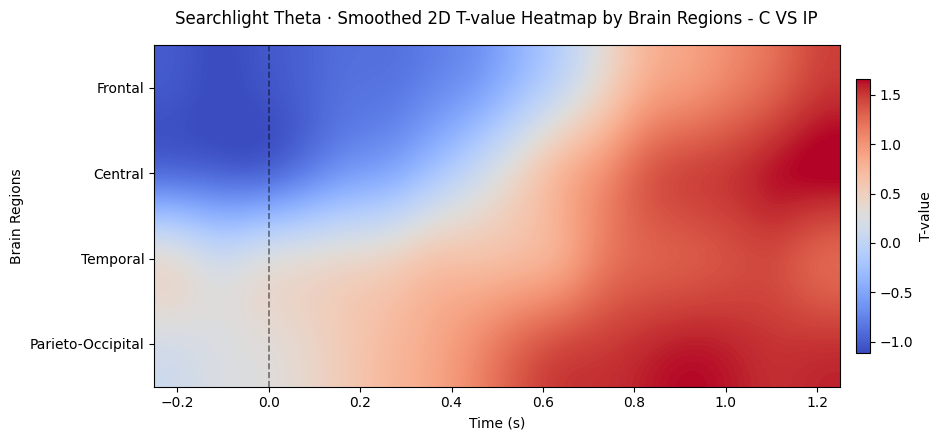

Continuous Regional Evolution T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_regional_tval_c_vs_ip.png (vmin=-1.11, vmax=1.66)


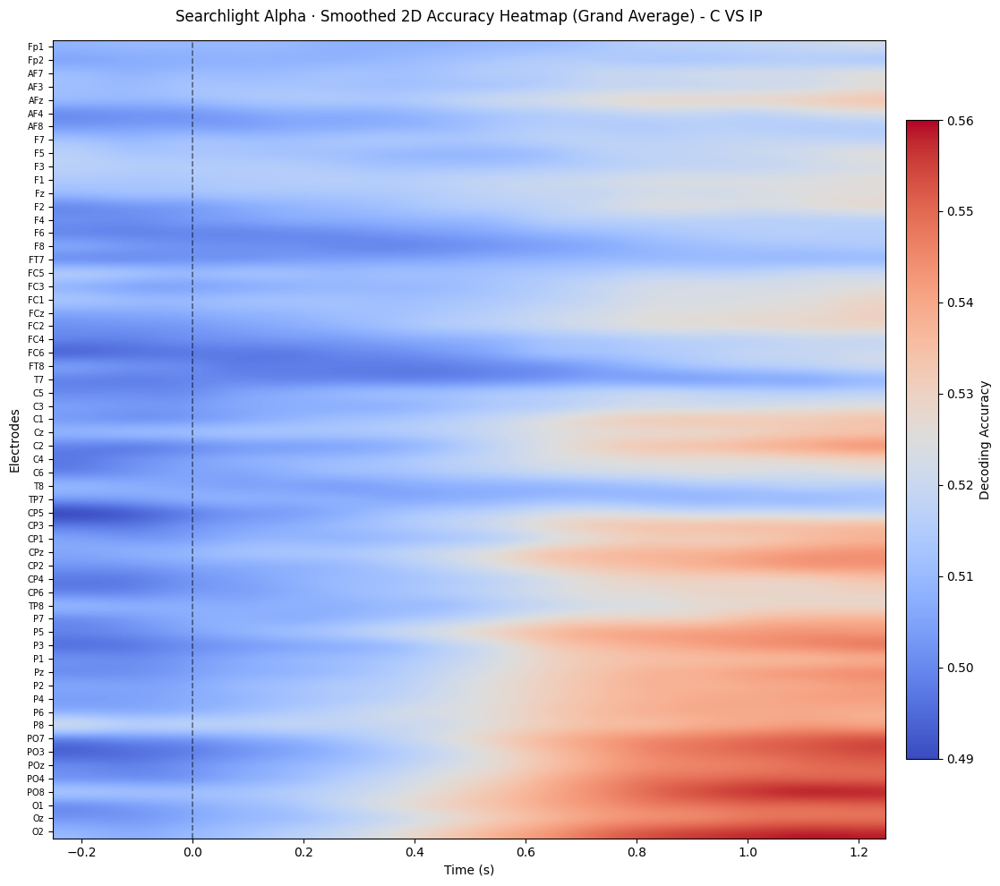

Continuous Grand Average saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_grand_average_c_vs_ip.png (vmin=0.49, vmax=0.56)


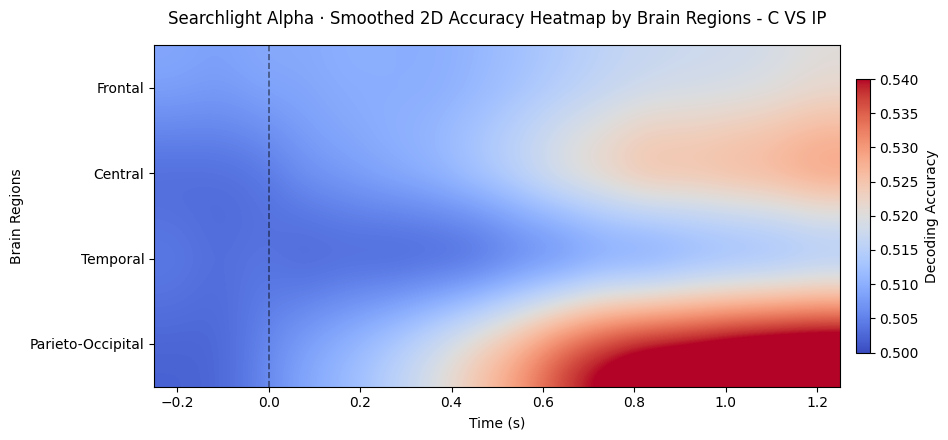

Continuous Regional Evolution saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_regional_c_vs_ip.png (vmin=0.5, vmax=0.54)


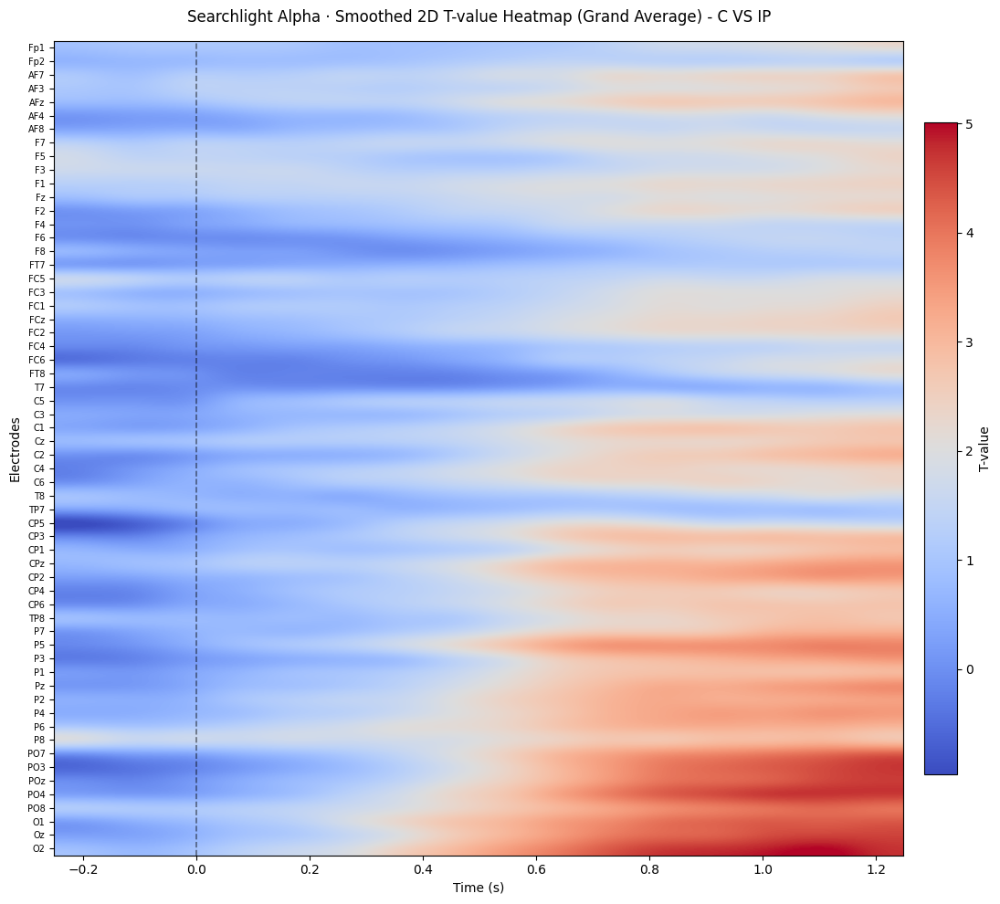

Continuous Grand Average T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_grand_average_tval_c_vs_ip.png (vmin=-0.96, vmax=5.01)


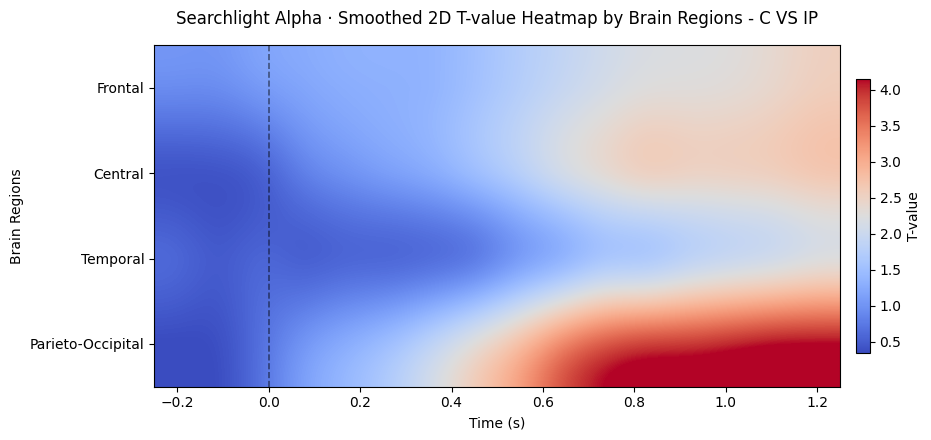

Continuous Regional Evolution T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_regional_tval_c_vs_ip.png (vmin=0.35, vmax=4.15)


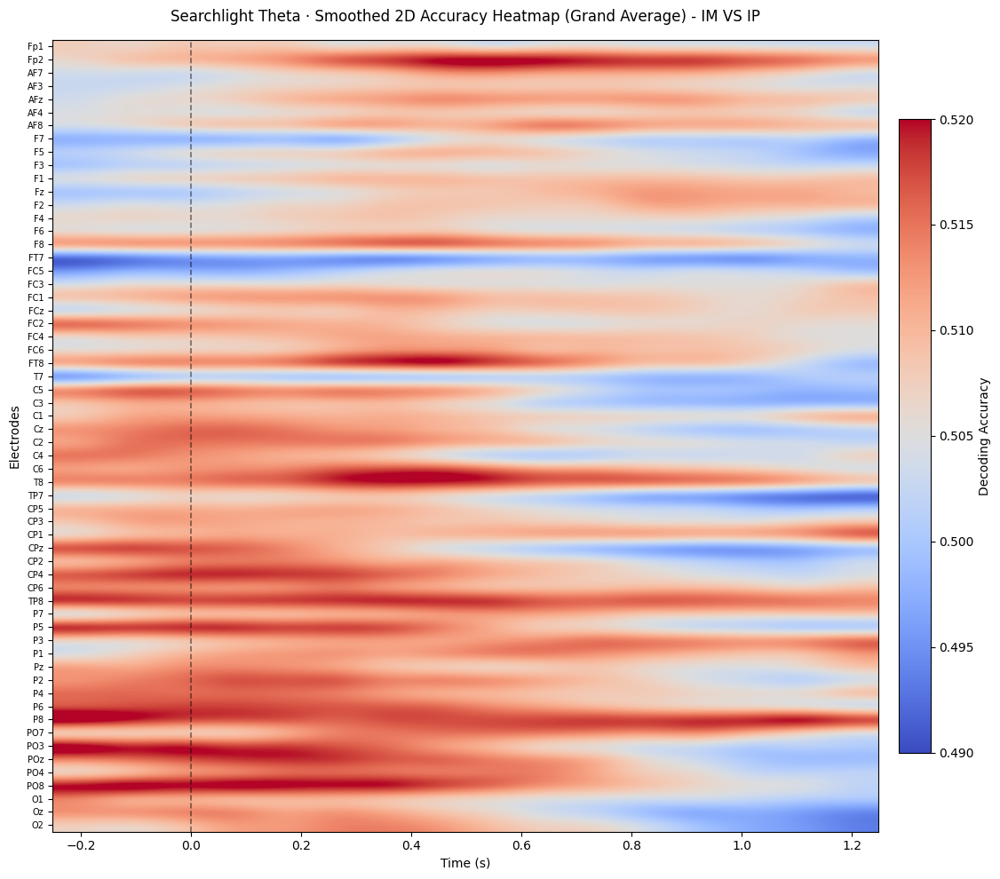

Continuous Grand Average saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_grand_average_im_vs_ip.png (vmin=0.49, vmax=0.52)


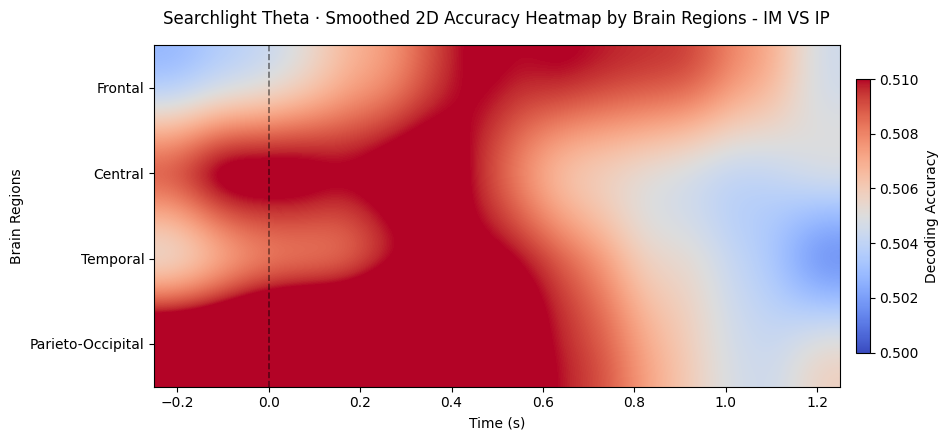

Continuous Regional Evolution saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_regional_im_vs_ip.png (vmin=0.5, vmax=0.51)


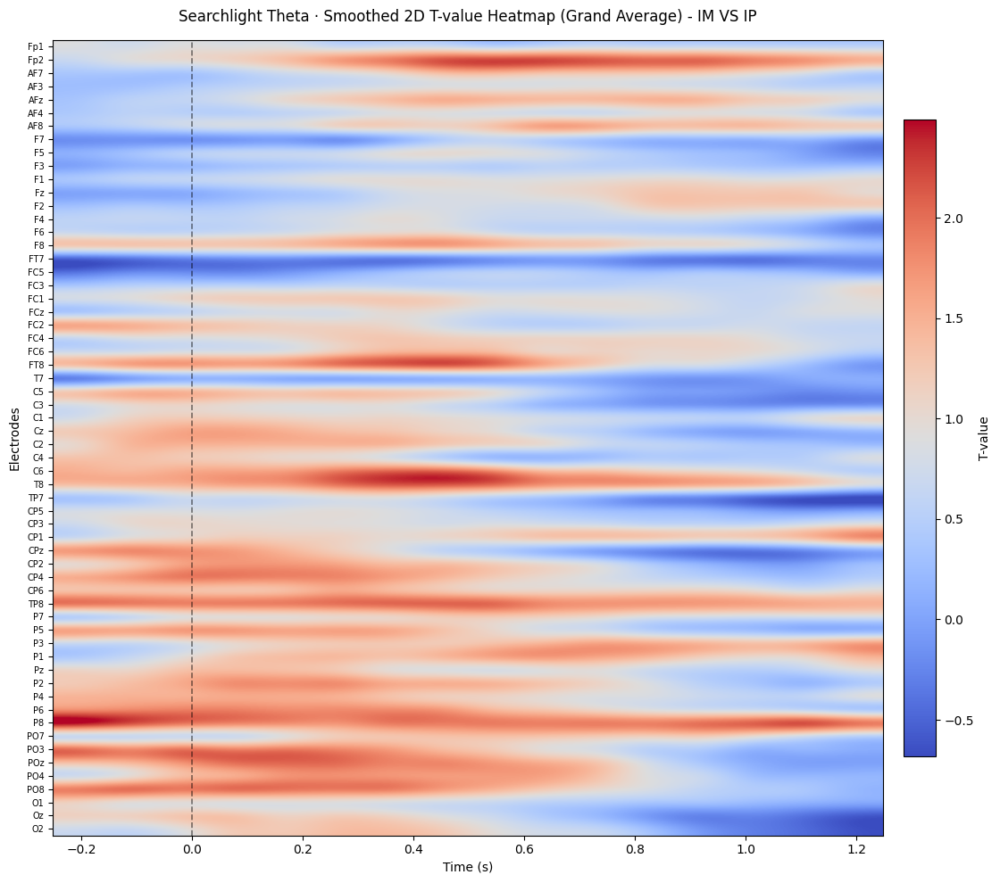

Continuous Grand Average T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_grand_average_tval_im_vs_ip.png (vmin=-0.68, vmax=2.49)


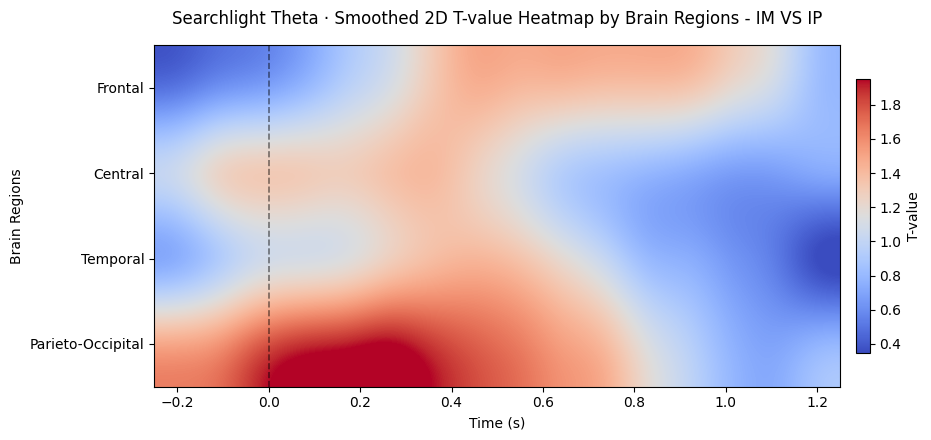

Continuous Regional Evolution T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_theta_continuous_regional_tval_im_vs_ip.png (vmin=0.35, vmax=1.95)


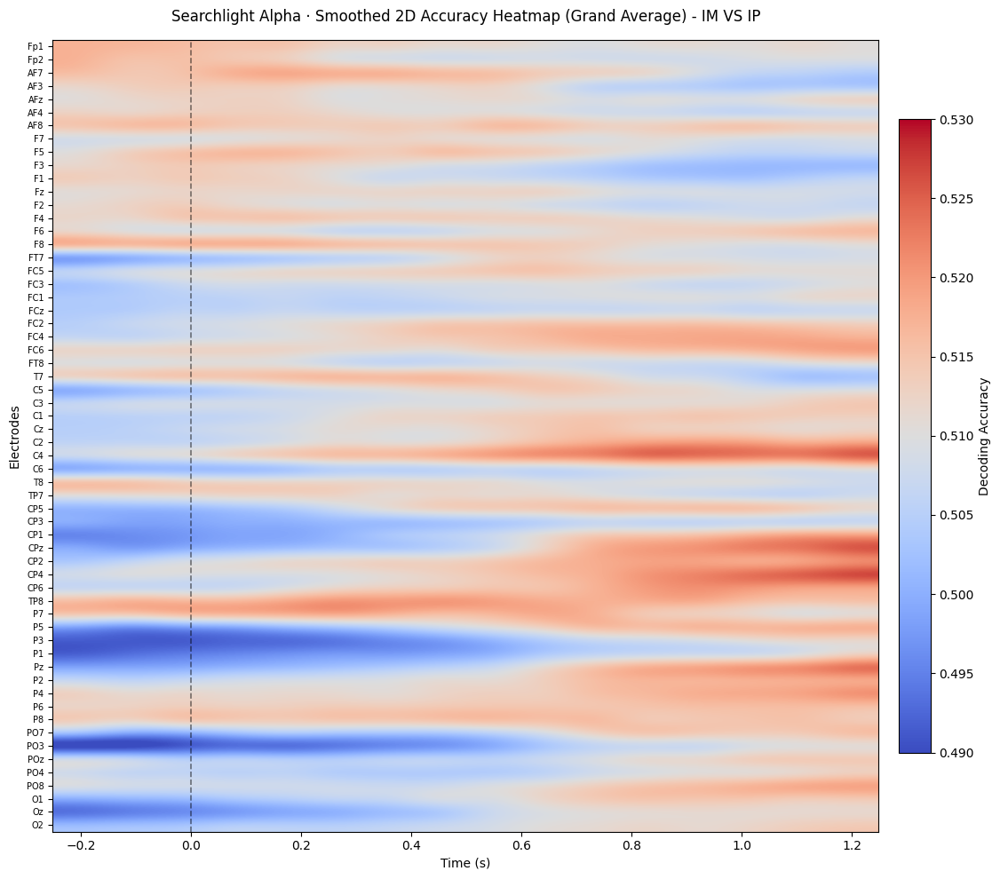

Continuous Grand Average saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_grand_average_im_vs_ip.png (vmin=0.49, vmax=0.53)


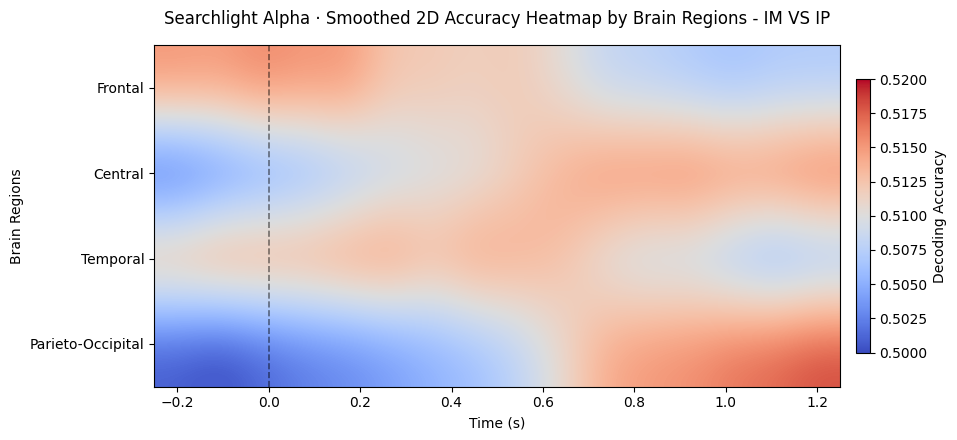

Continuous Regional Evolution saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_regional_im_vs_ip.png (vmin=0.5, vmax=0.52)


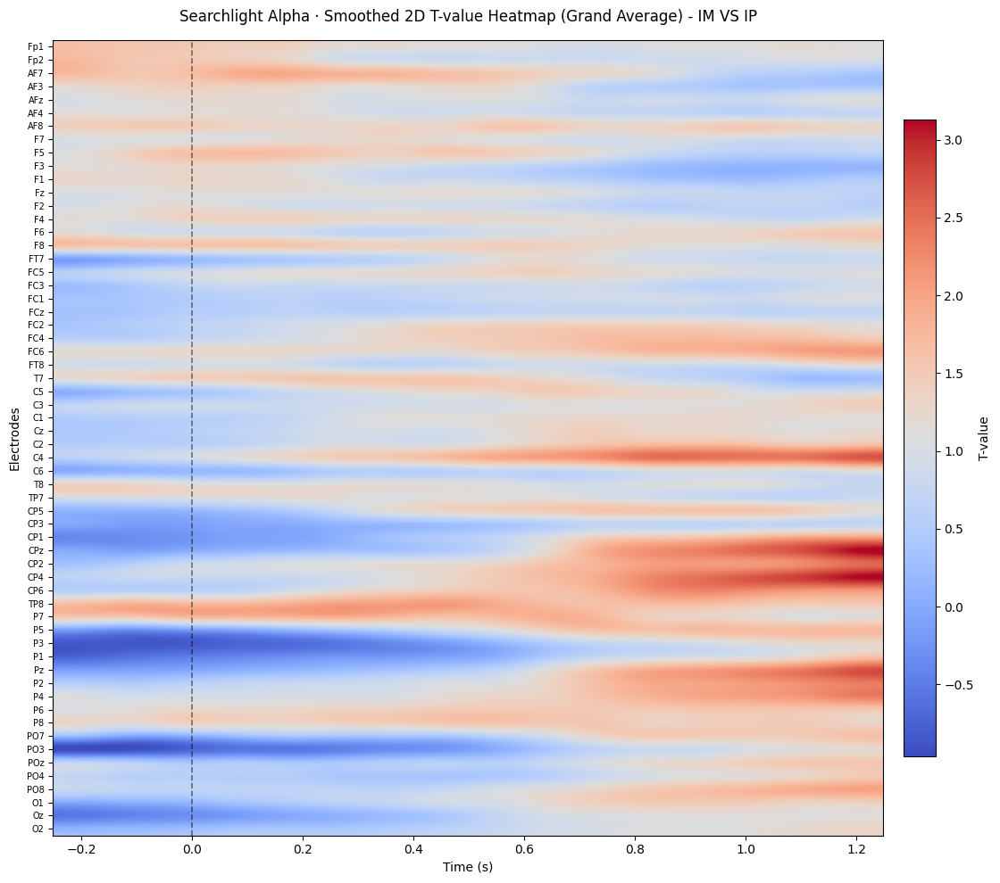

Continuous Grand Average T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_grand_average_tval_im_vs_ip.png (vmin=-0.96, vmax=3.13)


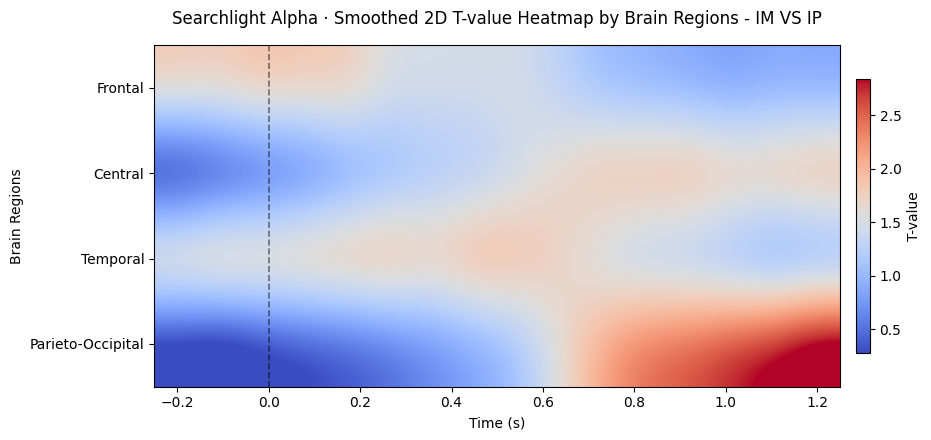

Continuous Regional Evolution T-value saved to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\searchlight_alpha_continuous_regional_tval_im_vs_ip.png (vmin=0.28, vmax=2.84)


In [19]:
# 8d. Continuous searchlight heatmaps (Grand Average + Regional trajectory)


def plot_continuous_searchlight(task, band_name, out_dir):
    import pandas as pd
    from scipy.stats import ttest_1samp

    acc = sl_results[task][band_name]["acc"]  # S x C x W
    ch_names = sl_results[task][band_name]["ch_names"]
    centers = sl_results[task][band_name]["window_centers"]

    # Define channels for standard brain regions
    FRONTAL_CH = ["Fp1", "Fp2", "AF7", "AF3", "AFz", "AF4", "AF8", "F7", "F5", "F3", "F1", "Fz", "F2", "F4", "F6", "F8"]
    CENTRAL_CH = ["FC5", "FC3", "FC1", "FCz", "FC2", "FC4", "FC6", "C5", "C3", "C1", "Cz", "C2", "C4", "C6"]
    TEMPORAL_CH = ["FT7", "FT8", "T7", "T8", "TP7", "TP8"]
    PARIETO_OCCIPITAL_CH = [
        "CP5",
        "CP3",
        "CP1",
        "CPz",
        "CP2",
        "CP4",
        "CP6",
        "P7",
        "P5",
        "P3",
        "P1",
        "Pz",
        "P2",
        "P4",
        "P6",
        "P8",
        "PO7",
        "PO3",
        "POz",
        "PO4",
        "PO8",
        "O1",
        "Oz",
        "O2",
    ]

    # Helper function for moving average smoothing along columns
    def smooth_2d(matrix, window_len=9):
        smoothed = np.zeros_like(matrix)
        for i in range(matrix.shape[0]):
            smoothed[i, :] = (
                pd.Series(matrix[i, :]).rolling(window=window_len, center=True, min_periods=1).mean().values
            )
        return smoothed

    # ------------------ ACCURACY HEATMAPS ------------------

    # 1. Grand Average Accuracy
    mean_acc = np.mean(acc, axis=0)  # shape: (C, W)
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    ordered_idx = [ch_to_idx[ch] for ch in CHANNEL_ORDER if ch in ch_to_idx]
    mean_acc_ordered = mean_acc[ordered_idx, :]
    smoothed_acc = smooth_2d(mean_acc_ordered, window_len=9)

    vmin_acc = float(np.round(np.nanmin(smoothed_acc), 2))
    vmax_acc = float(np.round(np.nanmax(smoothed_acc), 2))
    if vmin_acc == vmax_acc:
        vmin_acc -= 0.01
        vmax_acc += 0.01

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(
        smoothed_acc,
        aspect="auto",
        cmap="coolwarm",
        origin="upper",
        extent=[centers[0], centers[-1], len(CHANNEL_ORDER) - 0.5, -0.5],
        interpolation="spline36",
        vmin=vmin_acc,
        vmax=vmax_acc,
    )
    ax.set_yticks(np.arange(len(CHANNEL_ORDER)))
    ax.set_yticklabels(CHANNEL_ORDER, fontsize=7)
    ax.axvline(0.0, color="black", linestyle="--", alpha=0.5, linewidth=1.2)
    cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
    cbar.set_label("Decoding Accuracy", fontsize=10)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · Smoothed 2D Accuracy Heatmap (Grand Average) - {task.upper().replace('_', ' ')}",
        fontsize=12,
        pad=15,
    )
    ax.set_xlabel("Time (s)", fontsize=10)
    ax.set_ylabel("Electrodes", fontsize=10)

    plt.tight_layout()
    out_path_ga = out_dir / f"searchlight_{band_name}_continuous_grand_average_{task}.png"
    plt.savefig(out_path_ga, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Continuous Grand Average saved to: {out_path_ga} (vmin={vmin_acc}, vmax={vmax_acc})")

    # 2. Regional trajectory Accuracy
    regions = {
        "Frontal": FRONTAL_CH,
        "Central": CENTRAL_CH,
        "Temporal": TEMPORAL_CH,
        "Parieto-Occipital": PARIETO_OCCIPITAL_CH,
    }
    reg_names = list(regions.keys())
    reg_acc = []
    for r_name in reg_names:
        r_chs = regions[r_name]
        r_indices = [ch_names.index(ch) for ch in r_chs if ch in ch_names]
        r_mean = np.mean(acc[:, r_indices, :], axis=(0, 1))
        reg_acc.append(r_mean)
    reg_acc = np.array(reg_acc)
    smoothed_reg = smooth_2d(reg_acc, window_len=9)

    vmin_reg = float(np.round(np.nanmin(smoothed_reg), 2))
    vmax_reg = float(np.round(np.nanmax(smoothed_reg), 2))
    if vmin_reg == vmax_reg:
        vmin_reg -= 0.01
        vmax_reg += 0.01

    fig, ax = plt.subplots(figsize=(10, 4.5))
    im_reg = ax.imshow(
        smoothed_reg,
        aspect="auto",
        cmap="coolwarm",
        origin="upper",
        extent=[centers[0], centers[-1], len(reg_names) - 0.5, -0.5],
        interpolation="spline36",
        vmin=vmin_reg,
        vmax=vmax_reg,
    )
    ax.set_yticks(np.arange(len(reg_names)))
    ax.set_yticklabels(reg_names, fontsize=10)
    ax.axvline(0.0, color="black", linestyle="--", alpha=0.5, linewidth=1.2)
    cbar_reg = fig.colorbar(im_reg, ax=ax, shrink=0.8, pad=0.02)
    cbar_reg.set_label("Decoding Accuracy", fontsize=10)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · Smoothed 2D Accuracy Heatmap by Brain Regions - {task.upper().replace('_', ' ')}",
        fontsize=12,
        pad=15,
    )
    ax.set_xlabel("Time (s)", fontsize=10)
    ax.set_ylabel("Brain Regions", fontsize=10)

    plt.tight_layout()
    out_path_reg = out_dir / f"searchlight_{band_name}_continuous_regional_{task}.png"
    plt.savefig(out_path_reg, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Continuous Regional Evolution saved to: {out_path_reg} (vmin={vmin_reg}, vmax={vmax_reg})")

    # ------------------ T-VALUE HEATMAPS ------------------

    # 3. Grand Average T-value (Channel-by-Time Heatmap)
    t_vals, _ = ttest_1samp(acc, popmean=0.5, axis=0, nan_policy="omit")  # shape: (C, W)
    t_vals_ordered = t_vals[ordered_idx, :]
    smoothed_t = smooth_2d(t_vals_ordered, window_len=9)

    vmin_t = float(np.round(np.nanmin(smoothed_t), 2))
    vmax_t = float(np.round(np.nanmax(smoothed_t), 2))
    if vmin_t == vmax_t:
        vmin_t -= 0.1
        vmax_t += 0.1

    fig, ax = plt.subplots(figsize=(12, 10))
    im_t = ax.imshow(
        smoothed_t,
        aspect="auto",
        cmap="coolwarm",
        origin="upper",
        extent=[centers[0], centers[-1], len(CHANNEL_ORDER) - 0.5, -0.5],
        interpolation="spline36",
        vmin=vmin_t,
        vmax=vmax_t,
    )
    ax.set_yticks(np.arange(len(CHANNEL_ORDER)))
    ax.set_yticklabels(CHANNEL_ORDER, fontsize=7)
    ax.axvline(0.0, color="black", linestyle="--", alpha=0.5, linewidth=1.2)
    cbar_t = fig.colorbar(im_t, ax=ax, shrink=0.8, pad=0.02)
    cbar_t.set_label("T-value", fontsize=10)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · Smoothed 2D T-value Heatmap (Grand Average) - {task.upper().replace('_', ' ')}",
        fontsize=12,
        pad=15,
    )
    ax.set_xlabel("Time (s)", fontsize=10)
    ax.set_ylabel("Electrodes", fontsize=10)

    plt.tight_layout()
    out_path_ga_t = out_dir / f"searchlight_{band_name}_continuous_grand_average_tval_{task}.png"
    plt.savefig(out_path_ga_t, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Continuous Grand Average T-value saved to: {out_path_ga_t} (vmin={vmin_t}, vmax={vmax_t})")

    # 4. Regional trajectory T-value (Region-by-Time Heatmap)
    reg_acc_subj = []
    for r_name in reg_names:
        r_chs = regions[r_name]
        r_indices = [ch_names.index(ch) for ch in r_chs if ch in ch_names]
        r_mean_subj = np.mean(acc[:, r_indices, :], axis=1)  # shape: (S, W)
        reg_acc_subj.append(r_mean_subj)
    reg_acc_subj = np.stack(reg_acc_subj, axis=1)  # shape: (S, R, W)

    t_vals_reg, _ = ttest_1samp(reg_acc_subj, popmean=0.5, axis=0, nan_policy="omit")  # shape: (R, W)
    smoothed_reg_t = smooth_2d(t_vals_reg, window_len=9)

    vmin_reg_t = float(np.round(np.nanmin(smoothed_reg_t), 2))
    vmax_reg_t = float(np.round(np.nanmax(smoothed_reg_t), 2))
    if vmin_reg_t == vmax_reg_t:
        vmin_reg_t -= 0.1
        vmax_reg_t += 0.1

    fig, ax = plt.subplots(figsize=(10, 4.5))
    im_reg_t = ax.imshow(
        smoothed_reg_t,
        aspect="auto",
        cmap="coolwarm",
        origin="upper",
        extent=[centers[0], centers[-1], len(reg_names) - 0.5, -0.5],
        interpolation="spline36",
        vmin=vmin_reg_t,
        vmax=vmax_reg_t,
    )
    ax.set_yticks(np.arange(len(reg_names)))
    ax.set_yticklabels(reg_names, fontsize=10)
    ax.axvline(0.0, color="black", linestyle="--", alpha=0.5, linewidth=1.2)
    cbar_reg_t = fig.colorbar(im_reg_t, ax=ax, shrink=0.8, pad=0.02)
    cbar_reg_t.set_label("T-value", fontsize=10)

    ax.set_title(
        f"Searchlight {band_name.capitalize()} · Smoothed 2D T-value Heatmap by Brain Regions - {task.upper().replace('_', ' ')}",
        fontsize=12,
        pad=15,
    )
    ax.set_xlabel("Time (s)", fontsize=10)
    ax.set_ylabel("Brain Regions", fontsize=10)

    plt.tight_layout()
    out_path_reg_t = out_dir / f"searchlight_{band_name}_continuous_regional_tval_{task}.png"
    plt.savefig(out_path_reg_t, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Continuous Regional Evolution T-value saved to: {out_path_reg_t} (vmin={vmin_reg_t}, vmax={vmax_reg_t})")


for task in ["c_vs_ip", "im_vs_ip"]:
    plot_continuous_searchlight(task, "theta", FIGURES_DIR)
    plot_continuous_searchlight(task, "alpha", FIGURES_DIR)

## 9. Temporal Generalization Matrix (TGM)

In this step, the idea is to train models in one part of the trial (ex: 300ms) and do the test in another (ex: 600ms) to see if the pattern lasts over time. If the performance remains high, it means that there are similar patterns in the two time instants.

The problem is that the arrays have a gigantic dimension of up to 22 million cells (496 samples × 60 electrodes × 751 windows). But that's with 500Hz sampling. According to the Nyquist theorem, we need at least twice the peak frequency of interest to capture the patterns. Since we are interested in Theta (4-8 Hz) and Alpha (8-12 Hz), 24 Hz is the theoretical lower limit, and I double it for a margin of safety, reaching 48 Hz. Therefore, one could downsample to 50 Hz without losing relevant information, which would drastically reduce the dimension of the arrays and make the computation more manageable.

Cache Loaded TGM for c_vs_ip: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\cache\cache_tgm_minim_c_vs_ip.npz


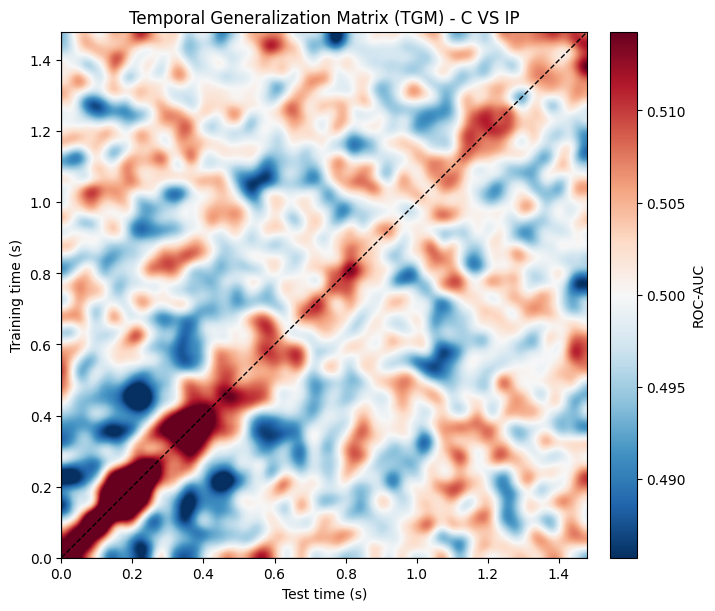

Saved TGM matrix for c_vs_ip: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\tgm_matrix_only_c_vs_ip.png
Cache Loaded TGM for im_vs_ip: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\cache\cache_tgm_minim_im_vs_ip.npz


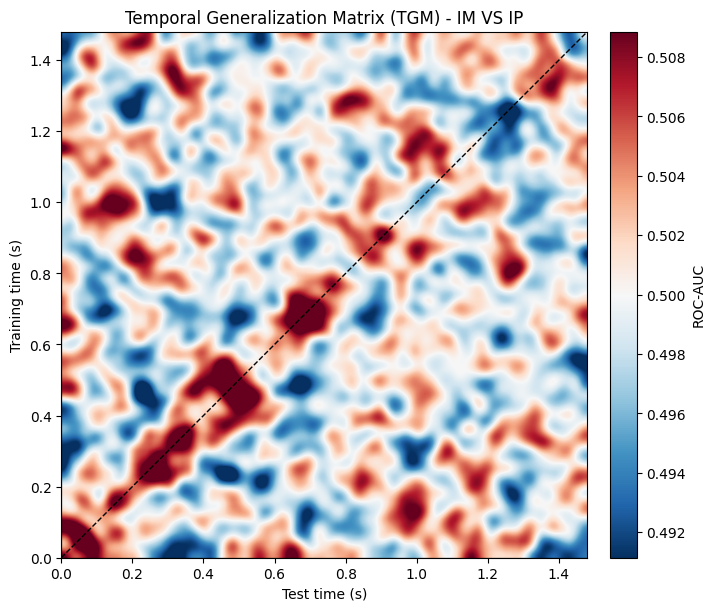

Saved TGM matrix for im_vs_ip: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\visualitzacions\figures\tgm_matrix_only_im_vs_ip.png


In [21]:
import sklearn.utils.validation as skval

# Store the true original exactly once (survives multiple cell runs)
if not hasattr(skval, "_orig_check_X_y"):
    skval._orig_check_X_y = skval.check_X_y


def _patched_check_X_y(*args, **kwargs):
    kwargs.pop("force_writeable", None)
    return skval._orig_check_X_y(*args, **kwargs)


# Explicitly patch all known modules to ensure compatibility
skval.check_X_y = _patched_check_X_y

try:
    import sklearn.utils as skutils

    skutils.check_X_y = _patched_check_X_y
except Exception:
    pass

try:
    import mne.decoding._fixes as _fixes

    _fixes.check_X_y = _patched_check_X_y
except Exception:
    pass

try:
    import mne.decoding.transformer as _mne_transformer

    _mne_transformer.check_X_y = _patched_check_X_y
except Exception:
    pass

try:
    import mne.decoding.search_light as _mne_sl

    _mne_sl.check_X_y = _patched_check_X_y
except Exception:
    pass

for task in ["c_vs_ip", "im_vs_ip"]:
    cache_tgm = CACHE_DIR / f"cache_tgm_minim_{task}.npz"
    subjects_to_use = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    subjects_actuals = np.array([s["subject"] for s in subjects_to_use], dtype=str)

    if task == "c_vs_ip":
        codes_0 = COND_CODES["C"]
        codes_1 = COND_CODES["IP"]
    else:
        codes_0 = COND_CODES["IM"]
        codes_1 = COND_CODES["IP"]

    try:
        z = np.load(cache_tgm, allow_pickle=False)
        tgm_tensor_cache = z["tgm_tensor"]
        times_tgm_cache = z["times_tgm"]
        subjects_cache = z["subjects"]

        # We reuse only if the subject list matches exactly.
        if np.array_equal(subjects_cache.astype(str), subjects_actuals):
            tgm_tensor = tgm_tensor_cache
            times_tgm = times_tgm_cache
            print(f"Cache Loaded TGM for {task}: {cache_tgm}")
        else:
            print(f"The file exists but the subjects have changed since the last execution")
            raise FileNotFoundError("Subjects in cache do not match current subjects.")

    except FileNotFoundError as e:
        print(f"Failed to load TGM cache for {task} at {cache_tgm} ({type(e).__name__}). Recalculating...")

        tgm_scores_all = []
        for si, s in enumerate(subjects_to_use):
            ep_tgm = s["epochs"].copy().load_data()
            ep_tgm._data = np.array(ep_tgm.get_data(), copy=True, order="C")

            # Select task trials
            events = ep_tgm.events[:, 2]
            mask_0 = np.isin(events, codes_0)
            mask_1 = np.isin(events, codes_1)
            ep_tgm = ep_tgm[mask_0 | mask_1].copy()
            if len(ep_tgm) == 0:
                continue

            y_tgm = np.where(np.isin(ep_tgm.events[:, 2], codes_0), 0, 1).astype(np.int8)

            ep_tgm.filter(l_freq=None, h_freq=30.0, method="fir", phase="zero-double", verbose=False)
            ep_tgm = ep_tgm.resample(50, npad="auto", verbose=False)

            X_tgm = ep_tgm.get_data()

            # Balance epochs
            if UNDERSAMPLE:
                idx_0 = np.where(y_tgm == 0)[0]
                idx_1 = np.where(y_tgm == 1)[0]
                n_min = min(len(idx_0), len(idx_1))
                if n_min < 2:
                    continue
                rng = np.random.default_rng(RANDOM_STATE + si)
                keep = np.concatenate(
                    [rng.choice(idx_0, n_min, replace=False), rng.choice(idx_1, n_min, replace=False)]
                )
                rng.shuffle(keep)
                X_tgm = X_tgm[keep]
                y_tgm = y_tgm[keep]

            clf_tgm = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", tol=1e-3))
            time_gen = GeneralizingEstimator(clf_tgm, scoring="roc_auc", verbose=False)

            # 3-fold CV per subject.
            scores = cross_val_multiscore(time_gen, X_tgm, y_tgm, cv=3, n_jobs=1)
            tgm_scores_all.append(np.mean(scores, axis=0))

        tgm_tensor = np.stack(tgm_scores_all, axis=0)  # (subjects, train_t, test_t)
        times_tgm = subjects_to_use[0]["epochs"].copy().decimate(10).times

        np.savez_compressed(
            cache_tgm,
            tgm_tensor=tgm_tensor,
            times_tgm=times_tgm,
            subjects=subjects_actuals,
        )
        print(f"Cached TGM for {task}: {cache_tgm}")

    # Global TGM matrix
    n_t = min(tgm_tensor.shape[1], len(times_tgm))
    times = np.asarray(times_tgm)[:n_t]
    tgm_tensor_use = tgm_tensor[:, :n_t, :n_t]

    # Significance to separate p<0.05 and p>0.05.
    _, p_vals = ttest_1samp(tgm_tensor_use, popmean=0.5, axis=0, alternative="greater")
    sig_mask = p_vals < 0.05

    tgm_ga = np.mean(tgm_tensor_use, axis=0)
    tgm_ga_smooth = gaussian_filter(tgm_ga, sigma=1.0)

    fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)

    vmax_real = float(np.percentile(tgm_ga_smooth, 98))
    vmin_real = 0.5 - (vmax_real - 0.5)

    im = ax.imshow(
        tgm_ga_smooth,
        interpolation="lanczos",
        origin="lower",
        cmap="RdBu_r",
        extent=[times[0], times[-1], times[0], times[-1]],
        vmin=vmin_real,
        vmax=vmax_real,
    )

    ax.axhline(0.0, color="k", linestyle="-", linewidth=1, alpha=0.5)
    ax.axvline(0.0, color="k", linestyle="-", linewidth=1, alpha=0.5)
    ax.plot([times[0], times[-1]], [times[0], times[-1]], color="k", linestyle="--", linewidth=1)

    ax.set_xlabel("Test time (s)")
    ax.set_ylabel("Training time (s)")
    ax.set_title(f"Temporal Generalization Matrix (TGM) - {task.upper().replace('_', ' ')}")

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("ROC-AUC")

    out_tgm_matrix = FIGURES_DIR / f"tgm_matrix_only_{task}.png"
    plt.savefig(out_tgm_matrix, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved TGM matrix for {task}: {out_tgm_matrix}")

## 10. Latency Maps

Here we want to see which area of the brain is the first to be able to classify C-IP significantly. It is done with a one-sample t-test against 0.5 for each electrode and window, and a topomap is drawn where the color indicates the onset latency (first instant of time with acc > 0.5 significant). If there is no significant instant, it is simply done with the first instant where acc > 0.5 (relaxed onset: 6/60 electrodes in theta, 0/60 in alpha).

[theta] strict onset: 57 | relaxed onset: 3


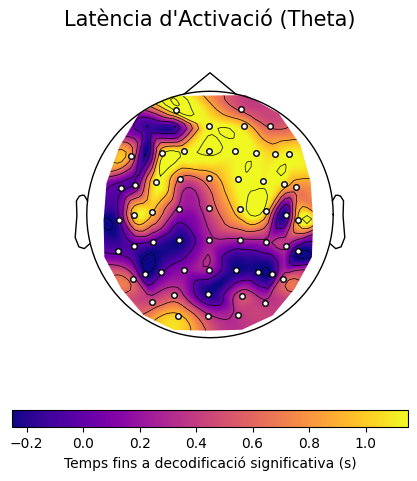

Onset theta desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\onset_map_theta.png
[alpha] strict onset: 60 | relaxed onset: 0


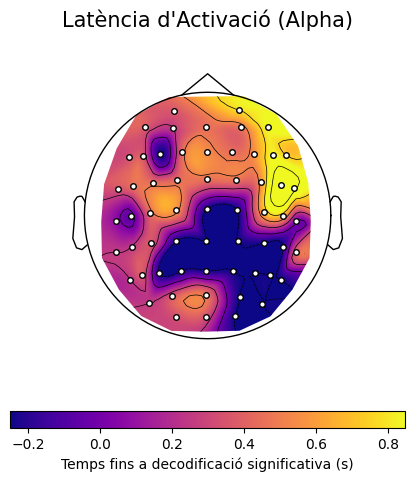

Onset alpha desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\onset_map_alpha.png


In [ ]:
def sl_prepare_onset_topo(result_dict, sfreq):
    """Create a stable topomap info aligned with result channels."""
    montage = mne.channels.make_standard_montage("standard_1020")
    ch_names = result_dict["ch_names"]

    available_ch = [ch for ch in ch_names if ch in montage.ch_names]
    if len(available_ch) < 4:
        raise RuntimeError("Not enough channels with valid position in montage standard_1020.")

    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    keep_idx = [ch_to_idx[ch] for ch in available_ch]

    topo_info = mne.create_info(
        ch_names=available_ch,
        sfreq=float(sfreq),
        ch_types="eeg",
    )
    topo_info.set_montage(montage, on_missing="raise")
    return topo_info, keep_idx


def plot_onset_map(accuracy_matrix, times, topo_info, keep_idx, band_name, task, out_dir):
    acc = accuracy_matrix[:, keep_idx, :]
    n_electrodes = acc.shape[1]
    onset_times = np.full(n_electrodes, np.nan, dtype=float)
    sig_ch = np.zeros(n_electrodes, dtype=bool)
    n_strict, n_relaxed = 0, 0

    for ch_idx in range(n_electrodes):
        _, p_vals = ttest_1samp(
            acc[:, ch_idx, :],
            popmean=0.5,
            axis=0,
            nan_policy="omit",
            alternative="greater",
        )
        mean_acc_time = np.nanmean(acc[:, ch_idx, :], axis=0)

        # Strict onset: first statistically significant timepoint above chance.
        strict_idx = np.where((p_vals < 0.05) & (mean_acc_time > 0.5))[0]
        if len(strict_idx) > 0:
            onset_times[ch_idx] = float(times[strict_idx[0]])
            sig_ch[ch_idx] = True
            n_strict += 1
            continue

        # Relaxed onset: first crossing above chance.
        relaxed_idx = np.where(mean_acc_time > 0.5)[0]
        if len(relaxed_idx) > 0:
            onset_times[ch_idx] = float(times[relaxed_idx[0]])
            n_relaxed += 1
            continue

    mask_invalid = np.isnan(onset_times)
    if np.all(mask_invalid):
        print(f"[{task.upper()} - {band_name}] No valid onsets; cannot plot map.")
        return

    finite_vals = onset_times[~mask_invalid]
    if finite_vals.size > 1:
        vmin = float(np.nanpercentile(finite_vals, 5))
        vmax = float(np.nanpercentile(finite_vals, 95))
    else:
        vmin = float(finite_vals[0] - 0.05)
        vmax = float(finite_vals[0] + 0.05)
    if vmax <= vmin:
        vmax = vmin + 1e-3

    # Impute missing channels for interpolation only, to avoid blank maps.
    onset_plot = onset_times.copy()
    if np.any(mask_invalid):
        onset_plot[mask_invalid] = float(np.nanmedian(finite_vals))

    fig = plt.figure(figsize=(5.1, 4.8))
    gs = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[18, 1], hspace=0.2)
    ax = fig.add_subplot(gs[0, 0])
    cax = fig.add_subplot(gs[1, 0])

    im, _ = mne.viz.plot_topomap(
        onset_plot,
        topo_info,
        axes=ax,
        cmap="plasma",
        vlim=(vmin, vmax),
        mask=sig_ch,
        mask_params={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "black",
            "linewidth": 0.0,
            "markersize": 4,
        },
        contours=6,
        sensors=True,
        extrapolate="local",
        sphere=(0.0, 0.02, 0.0, 0.096),
        show=False,
    )
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(f"Activation Latency ({band_name.capitalize()}) - {task.upper().replace('_', ' ')}\n", fontsize=12)
    cbar = fig.colorbar(im, cax=cax, orientation="horizontal")
    cbar.set_label("Time to significant decoding (s)")

    print(f"[{task.upper()} - {band_name}] strict onset: {n_strict} | relaxed onset: {n_relaxed}")

    out_onset = out_dir / f"onset_map_{band_name}_{task}.png"
    plt.savefig(out_onset, dpi=300, bbox_inches="tight", pad_inches=0.05)
    plt.close(fig)
    print(f"Onset {band_name} saved to: {out_onset}")


sfreq_ref = float(sl_subjects_searchlight_c[0]["epochs"].info["sfreq"])
for task in ["c_vs_ip", "im_vs_ip"]:
    for band_name, d in sl_results[task].items():
        topo_info, keep_idx = sl_prepare_onset_topo(d, sfreq_ref)
        plot_onset_map(d["acc"], d["window_centers"], topo_info, keep_idx, band_name, task, FIGURES_DIR)

## 11. Correlations depending on the distance between electrodes


Processant subjecte: P057
Utilitzant 1770 parells d'elèctrodes.


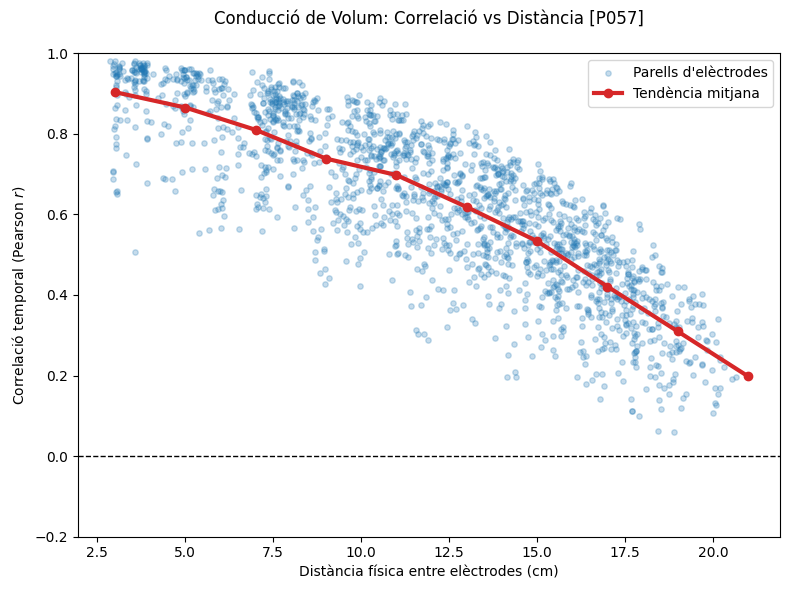

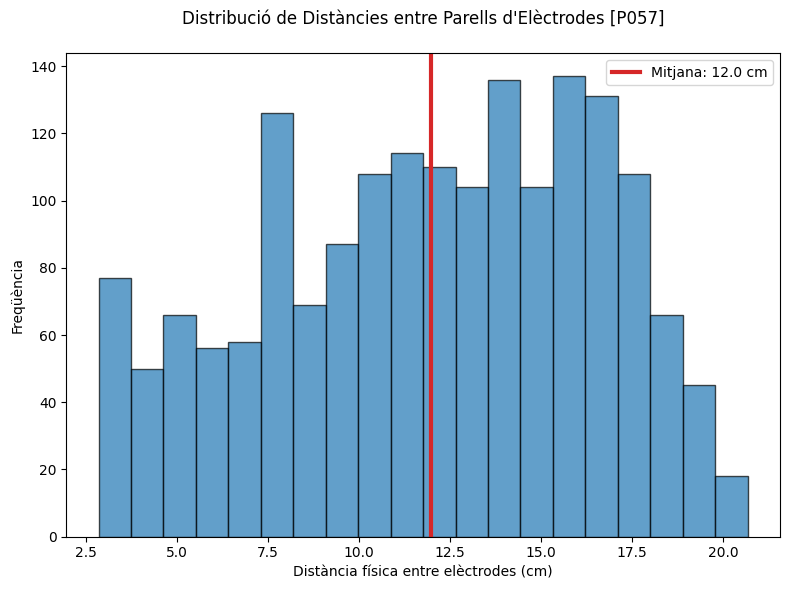

Utilitzant 38940 parells d'elèctrodes.


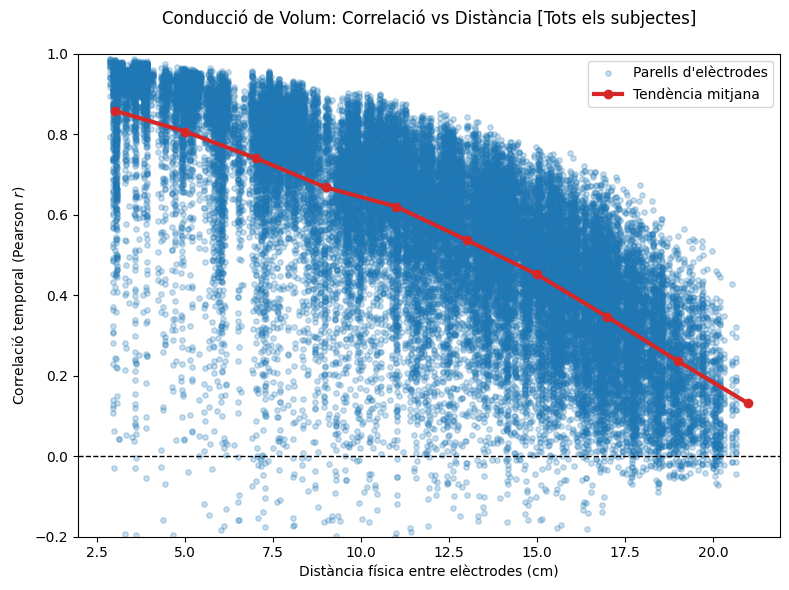

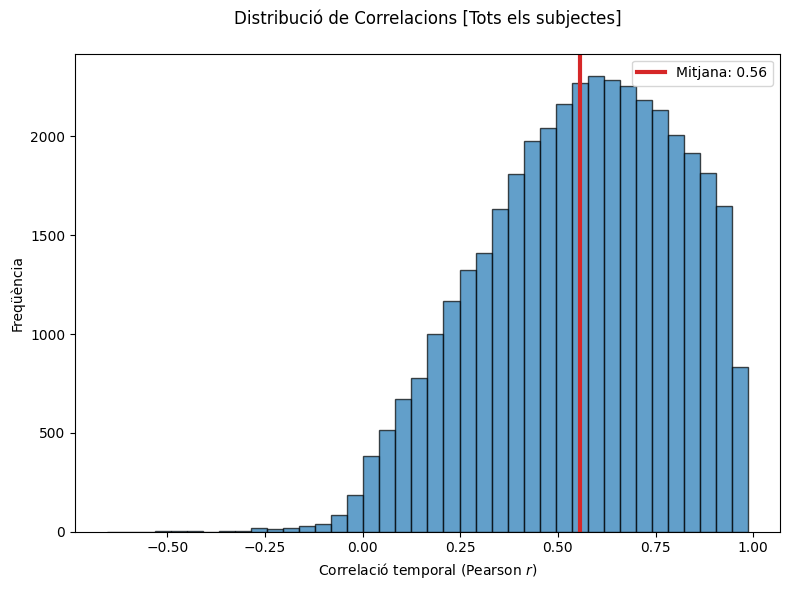

In [ ]:
def plot_spatial_correlation_drop(epochs, title_extra="", is_inter=False):
    """
    Calculates and visualizes spatial correlation vs distance between electrodes.

    Parameters:
    -----------
    epochs : mne.Epochs or list of mne.Epochs
        If is_inter=False: a single Epochs object (intra-subject)
        If is_inter=True: list of multiple Epochs (inter-subject)
    title_extra : str
        Extra text for the title
    is_inter : bool
        If True, combine data from multiple subjects (inter)
        If False, analyze a single subject (intra)
    """

    if is_inter and isinstance(epochs, list):
        # ============= INTER-SUBJECT MODE =============
        # Combine data from all subjects
        all_distances = []
        all_correlations = []

        for ep_subj in epochs:
            ep_temp = ep_subj.copy()
            montage = mne.channels.make_standard_montage("standard_1005")
            ep_temp.set_montage(montage, match_case=False, on_missing="ignore")

            positions = np.array([ch["loc"][:3] for ch in ep_temp.info["chs"]]) * 100
            valid_mask = np.any(positions != 0, axis=1)
            valid_positions = positions[valid_mask]

            if np.sum(valid_mask) < 4:
                continue

            dist_mat = squareform(pdist(valid_positions))
            data = ep_temp.get_data()[:, valid_mask, :].transpose(1, 0, 2).reshape(np.sum(valid_mask), -1)
            corr_mat = np.corrcoef(data)

            triu_idx = np.triu_indices_from(dist_mat, k=1)
            all_distances.append(dist_mat[triu_idx])
            all_correlations.append(corr_mat[triu_idx])

        # Match all pairs of all subjects
        distances_pairs = np.concatenate(all_distances)
        correlations_pairs = np.concatenate(all_correlations)

    else:
        # ============= INTRA-SUBJECT MODE =============
        ep_temp = epochs.copy()
        montage = mne.channels.make_standard_montage("standard_1005")
        ep_temp.set_montage(montage, match_case=False, on_missing="ignore")

        positions = np.array([ch["loc"][:3] for ch in ep_temp.info["chs"]]) * 100
        valid_mask = np.any(positions != 0, axis=1)
        valid_positions = positions[valid_mask]

        dist_mat = squareform(pdist(valid_positions))
        data = ep_temp.get_data()[:, valid_mask, :].transpose(1, 0, 2).reshape(np.sum(valid_mask), -1)
        corr_mat = np.corrcoef(data)

        triu_idx = np.triu_indices_from(dist_mat, k=1)
        distances_pairs = dist_mat[triu_idx]
        correlations_pairs = corr_mat[triu_idx]

    print(f"Using {len(distances_pairs)} pairs of electrodes.")

    # ---------------------------------------------------------
    # CALCULATION OF STATISTICS FOR BINS
    # ---------------------------------------------------------
    intervals = np.arange(0, distances_pairs.max() + 2, 2)
    bin_centers = (intervals[:-1] + intervals[1:]) / 2
    mean_corr = []

    for i in range(len(intervals) - 1):
        bin_mask = (distances_pairs >= intervals[i]) & (distances_pairs < intervals[i + 1])
        if np.any(bin_mask):
            vals = correlations_pairs[bin_mask]
            mean_corr.append(np.mean(vals))
        else:
            mean_corr.append(np.nan)

    mean_corr = np.array(mean_corr)

    mode_text = "All subjects" if is_inter else f"{title_extra}"

    # ---------------------------------------------------------
    # FIGURE 1: SCATTER + TREND
    # ---------------------------------------------------------
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    ax1.scatter(distances_pairs, correlations_pairs, alpha=0.25, color="tab:blue", s=15, label="Electrode pairs")
    ax1.plot(bin_centers, mean_corr, color="tab:red", linewidth=3, marker="o", label="Mean trend")
    ax1.axhline(0, color="black", linestyle="--", linewidth=1)
    ax1.set_title(f"Volume Conduction: Correlation vs Distance [{mode_text}]\n")
    ax1.set_xlabel("Physical distance between electrodes (cm)")
    ax1.set_ylabel("Temporal correlation (Pearson $r$)")
    ax1.set_ylim(-0.2, 1.0)
    ax1.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"spatial_correlation_scatter_{title_extra}.png", dpi=180, bbox_inches="tight")
    plt.show()

    # ---------------------------------------------------------
    # FIGURE 2: HISTOGRAM
    # ---------------------------------------------------------
    if is_inter:
        fig2, ax2 = plt.subplots(figsize=(8, 6))
        ax2.hist(correlations_pairs, bins=40, color="tab:blue", alpha=0.7, edgecolor="black")
        ax2.axvline(
            np.mean(correlations_pairs),
            color="tab:red",
            linewidth=3,
            label=f"Mean: {np.mean(correlations_pairs):.2f}",
        )
        ax2.set_title(f"Correlation Distribution [{mode_text}]\n")
        ax2.set_xlabel("Temporal correlation (Pearson $r$)")
        ax2.set_ylabel("Frequency")
        ax2.legend()
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"spatial_correlation_histogram.png", dpi=180, bbox_inches="tight")
        plt.show()
    else:
        # Histogram of distances between pairs of electrodes
        fig2, ax2 = plt.subplots(figsize=(8, 6))
        ax2.hist(distances_pairs, bins=20, color="tab:blue", alpha=0.7, edgecolor="black")
        ax2.axvline(
            np.mean(distances_pairs),
            color="tab:red",
            linewidth=3,
            label=f"Mean: {np.mean(distances_pairs):.1f} cm",
        )
        ax2.set_title(f"Distribution of Distances between Electrode Pairs [{mode_text}]\n")
        ax2.set_xlabel("Physical distance between electrodes (cm)")
        ax2.set_ylabel("Frequency")
        ax2.legend()
        plt.tight_layout()
        plt.savefig(
            FIGURES_DIR / f"spatial_correlation_distances_histogram_{title_extra}.png", dpi=180, bbox_inches="tight"
        )
        plt.show()


subj_data = sl_subjects[0]
subj_name = subj_data["subject"]
ep_subj = subj_data["epochs"]
print(f"\nProcessing subject: {subj_name}")
plot_spatial_correlation_drop(ep_subj, title_extra=subj_name, is_inter=False)

epochs_list = [s["epochs"] for s in sl_subjects]
plot_spatial_correlation_drop(epochs_list, title_extra="", is_inter=True)

## 12. Classification Spectrogram
A Short-Time Fourier Transform is used to continuously scan the power between 4Hz and 20Hz, applying a *logratio* correction to the pre-stimulus baseline. This plot makes it possible to carefully break down the oscillations of each frequency band, visualized on the central electrode `FCz' in 1 single subject.

Millor subjecte detectat: P057 (Accuracy mitjana: 0.592)


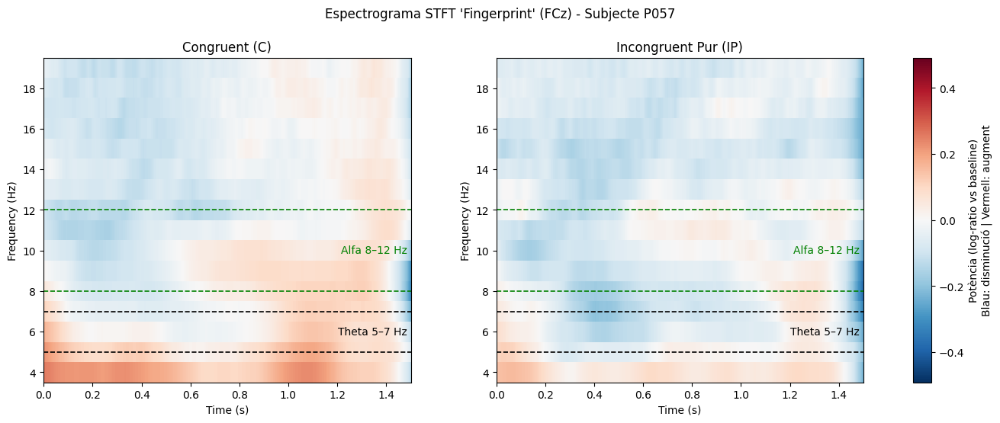

In [ ]:
best_subjects_by_task = {}

for task in ["c_vs_ip", "im_vs_ip"]:
    # 1. We find the subject with better general accuracy in the Theta band
    theta_acc = sl_results[task]["theta"]["acc"]  # Shape: (S, C, W)
    subj_mean_acc = np.mean(theta_acc, axis=(1, 2))
    best_subj_idx = int(np.argmax(subj_mean_acc))
    subjects_list = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    best_subj_name = subjects_list[best_subj_idx]["subject"]
    best_subjects_by_task[task] = best_subj_name

    print(
        f"[{task.upper()}] Best subject detected: {best_subj_name} (Mean accuracy: {subj_mean_acc[best_subj_idx]:.3f})"
    )

    # To have the full baseline (-0.74s), RELOAD the original epochs without the global crop at 0.0s
    fif_path = sl_fif_by_subject[best_subj_name]
    ep_raw, _ = sl_read_epochs_safe(fif_path)

    # Correct metadata
    for ch_idx, ch_name in enumerate(ep_raw.ch_names):
        if ep_raw.info["chs"][ch_idx]["unit"] == 0:
            ep_raw.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ep_raw.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE
    ep_raw.set_channel_types({ch: "eeg" for ch in ep_raw.ch_names}, on_unit_change="ignore")
    ep_raw = ep_raw.pick(mne.pick_types(ep_raw.info, eeg=True))

    # Crop including baseline
    ep_raw = ep_raw.crop(tmin=-0.75, tmax=1.5)

    # Filter by conditions C, IP, and IM
    events = ep_raw.events[:, 2]
    mask_c = np.isin(events, COND_CODES["C"])
    mask_ip = np.isin(events, COND_CODES["IP"])
    mask_im = np.isin(events, COND_CODES["IM"])

    ep_c = ep_raw[mask_c]
    ep_ip = ep_raw[mask_ip]
    ep_im = ep_raw[mask_im]

    # Calculate STFT with Multitaper (constant window) from 4Hz to 20Hz
    freqs = np.arange(4, 20, 1)
    n_cycles = freqs * 0.4

    tfr_c = mne.time_frequency.tfr_multitaper(
        ep_c, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
    )
    tfr_ip = mne.time_frequency.tfr_multitaper(
        ep_ip, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
    )
    tfr_im = mne.time_frequency.tfr_multitaper(
        ep_im, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
    )

    # Baseline (logratio)
    tfr_c.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")
    tfr_ip.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")
    tfr_im.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")

    # Crop only the plot at (0.0, 1.5)
    tfr_c.crop(tmin=0.0, tmax=1.5)
    tfr_ip.crop(tmin=0.0, tmax=1.5)
    tfr_im.crop(tmin=0.0, tmax=1.5)

    # Plot layout (3 panels)
    fig = plt.figure(figsize=(18, 5), constrained_layout=True)
    gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.15)
    ax_c = fig.add_subplot(gs[0, 0])
    ax_ip = fig.add_subplot(gs[0, 1], sharex=ax_c, sharey=ax_c)
    ax_im = fig.add_subplot(gs[0, 2], sharex=ax_c, sharey=ax_c)
    cax = fig.add_subplot(gs[0, 3])

    vmax = max(np.abs(tfr_c.data).max(), np.abs(tfr_ip.data).max(), np.abs(tfr_im.data).max())
    vlim = (-vmax, vmax)

    tfr_c.plot("FCz", axes=ax_c, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_c.set_title("Congruent (C)")

    tfr_ip.plot("FCz", axes=ax_ip, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_ip.set_title("Incongruent Pure (IP)")

    tfr_im.plot("FCz", axes=ax_im, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_im.set_title("Incongruent Mixed (IM)")

    for ax in (ax_c, ax_ip, ax_im):
        ax.axhline(5, color="black", linestyle="--", linewidth=1.2)
        ax.axhline(7, color="black", linestyle="--", linewidth=1.2)
        ax.axhline(8, color="green", linestyle="--", linewidth=1.2)
        ax.axhline(12, color="green", linestyle="--", linewidth=1.2)
        ax.text(
            0.99,
            6,
            "Theta 5–7 Hz",
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            color="black",
        )
        ax.text(
            0.99,
            10,
            "Alpha 8–12 Hz",
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            color="green",
        )

    mappable = ax_ip.images[0] if len(ax_ip.images) > 0 else ax_c.images[0]
    cbar = fig.colorbar(mappable, cax=cax)
    cbar.set_label("Power (log-ratio vs baseline)\nBlue: decrease | Red: increase")

    fig.suptitle(
        f"STFT Spectrogram 'Fingerprint' (FCz) - Subject {best_subj_name} ({task.upper().replace('_', ' ')})", y=1.08
    )

    out_tfr = FIGURES_DIR / f"spectrogram_fingerprint_{best_subj_name}_FCz_{task}.png"
    plt.savefig(out_tfr, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved spectrogram for {task}: {out_tfr}")

In [ ]:
print("Calculating Grand Average Spectrogram (STFT Multitaper)...")

freqs = np.arange(4, 20, 1)
n_cycles = freqs * 0.4

for task in ["c_vs_ip", "im_vs_ip"]:
    subjects_to_use = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    all_tfr_c = []
    all_tfr_ip = []
    all_tfr_im = []

    for s in subjects_to_use:
        subj_name = s["subject"]
        fif_path = sl_fif_by_subject[subj_name]
        ep_raw, _ = sl_read_epochs_safe(fif_path)

        if ep_raw is None:
            print(f"[{subj_name}] Epochs could not be loaded. Subject discarded.")
            continue

        for ch_idx, ch_name in enumerate(ep_raw.ch_names):
            if ep_raw.info["chs"][ch_idx]["unit"] == 0:
                ep_raw.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep_raw.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        ep_raw.set_channel_types({ch: "eeg" for ch in ep_raw.ch_names}, on_unit_change="ignore")
        ep_raw = ep_raw.pick(mne.pick_types(ep_raw.info, eeg=True))

        # Retrieve temporal negative part for baseline
        ep_raw = ep_raw.crop(tmin=-0.75, tmax=1.5)

        events = ep_raw.events[:, 2]
        ep_c_s = ep_raw[np.isin(events, COND_CODES["C"])]
        ep_ip_s = ep_raw[np.isin(events, COND_CODES["IP"])]
        ep_im_s = ep_raw[np.isin(events, COND_CODES["IM"])]

        tfr_c_s = mne.time_frequency.tfr_multitaper(
            ep_c_s, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
        )
        tfr_ip_s = mne.time_frequency.tfr_multitaper(
            ep_ip_s, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
        )
        tfr_im_s = mne.time_frequency.tfr_multitaper(
            ep_im_s, freqs=freqs, n_cycles=n_cycles, return_itc=False, average=True, time_bandwidth=2.0, verbose=False
        )

        all_tfr_c.append(tfr_c_s)
        all_tfr_ip.append(tfr_ip_s)
        all_tfr_im.append(tfr_im_s)

    ga_tfr_c = mne.grand_average(all_tfr_c)
    ga_tfr_ip = mne.grand_average(all_tfr_ip)
    ga_tfr_im = mne.grand_average(all_tfr_im)

    # Apply Baseline correction with logratio
    ga_tfr_c.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")
    ga_tfr_ip.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")
    ga_tfr_im.apply_baseline(baseline=(-0.74, -0.24), mode="logratio")

    # Crop task interval [0.0, 1.5] for display
    ga_tfr_c.crop(tmin=0.0, tmax=1.5)
    ga_tfr_ip.crop(tmin=0.0, tmax=1.5)
    ga_tfr_im.crop(tmin=0.0, tmax=1.5)

    # Plot layout (3 panels)
    fig = plt.figure(figsize=(18, 5), constrained_layout=True)
    gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.05], wspace=0.15)
    ax_c = fig.add_subplot(gs[0, 0])
    ax_ip = fig.add_subplot(gs[0, 1], sharex=ax_c, sharey=ax_c)
    ax_im = fig.add_subplot(gs[0, 2], sharex=ax_c, sharey=ax_c)
    cax = fig.add_subplot(gs[0, 3])

    vmax = max(
        np.percentile(np.abs(ga_tfr_c.data), 95),
        np.percentile(np.abs(ga_tfr_ip.data), 95),
        np.percentile(np.abs(ga_tfr_im.data), 95),
    )
    vlim = (-vmax, vmax)

    ga_tfr_c.plot("FCz", axes=ax_c, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_c.set_title("Congruent (C) - Grand Average")

    ga_tfr_ip.plot("FCz", axes=ax_ip, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_ip.set_title("Incongruent Pure (IP) - Grand Average")

    ga_tfr_im.plot("FCz", axes=ax_im, show=False, colorbar=False, cmap="RdBu_r", vlim=vlim)
    ax_im.set_title("Incongruent Mixed (IM) - Grand Average")

    for ax in (ax_c, ax_ip, ax_im):
        ax.axhline(5, color="black", linestyle="--", linewidth=1.2)
        ax.axhline(7, color="black", linestyle="--", linewidth=1.2)
        ax.axhline(8, color="green", linestyle="--", linewidth=1.2)
        ax.axhline(12, color="green", linestyle="--", linewidth=1.2)
        ax.text(
            0.99,
            6,
            "Theta 5–7 Hz",
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            color="black",
        )
        ax.text(
            0.99,
            10,
            "Alpha 8–12 Hz",
            transform=ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            color="green",
        )

    mappable = ax_ip.images[0] if len(ax_ip.images) > 0 else ax_c.images[0]
    cbar = fig.colorbar(mappable, cax=cax)
    cbar.set_label("Power (log-ratio vs baseline)\nBlue: decrease | Red: increase")

    fig.suptitle(f"STFT Spectrogram 'Fingerprint' (FCz) - Grand Average ({task.upper().replace('_', ' ')})", y=1.08)

    out_tfr_ga = FIGURES_DIR / f"spectrogram_fingerprint_GA_FCz_{task}.png"
    plt.savefig(out_tfr_ga, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved GA spectrogram for {task}: {out_tfr_ga}")

Calculant Espectrograma Grand Average (STFT Multitaper)...


## 13. ERP Image

It groups the entire time history into ordered series of readings across trials to represent a subject's amplitude and consecutive electrical persistence oscillation around the `FCz' central electrode. Below is the completed conventional global ERP scheme by largely vector summing.

In [ ]:
# To maintain compatibility, we select the best subject for the C vs IP task by default here.
best_subj_name_default = best_subjects_by_task["c_vs_ip"]
best_subj_idx_default = [si for si, s in enumerate(sl_subjects_c) if s["subject"] == best_subj_name_default][0]
best_subj_data = sl_subjects_c[best_subj_idx_default]
best_subj_name = best_subj_data["subject"]
ep_best = best_subj_data["epochs"].copy()
subj_name = best_subj_name
montage = mne.channels.make_standard_montage("standard_1005")
ep_best.set_montage(montage, match_case=False, on_missing="ignore")

In [ ]:
for task in ["c_vs_ip", "im_vs_ip"]:
    best_subj_name_task = best_subjects_by_task[task]
    subjects_list = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    best_subj_data_task = [s for s in subjects_list if s["subject"] == best_subj_name_task][0]
    ep_best_task = best_subj_data_task["epochs"].copy()
    montage = mne.channels.make_standard_montage("standard_1005")
    ep_best_task.set_montage(montage, match_case=False, on_missing="ignore")

    # Each condition needs 3 axes: [image, erp line plot, colorbar]
    fig = plt.figure(figsize=(11, 11), constrained_layout=True)
    gs = fig.add_gridspec(3, 1)

    # Set up subgridspec for C, IP, IM
    gs_c = gs[0].subgridspec(1, 3, width_ratios=[5, 4, 0.5])
    gs_ip = gs[1].subgridspec(1, 3, width_ratios=[5, 4, 0.5])
    gs_im = gs[2].subgridspec(1, 3, width_ratios=[5, 4, 0.5])

    axes_c = [fig.add_subplot(gs_c[i]) for i in range(3)]
    axes_ip = [fig.add_subplot(gs_ip[i]) for i in range(3)]
    axes_im = [fig.add_subplot(gs_im[i]) for i in range(3)]

    mne.viz.plot_epochs_image(
        ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["C"])],
        picks="FCz",
        title="Congruent (FCz)",
        axes=axes_c,
        show=False,
        combine=None,
        cmap="RdBu_r",
    )
    mne.viz.plot_epochs_image(
        ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["IP"])],
        picks="FCz",
        title="Incongruent Pure (FCz)",
        axes=axes_ip,
        show=False,
        combine=None,
        cmap="RdBu_r",
    )
    mne.viz.plot_epochs_image(
        ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["IM"])],
        picks="FCz",
        title="Incongruent Mixed (FCz)",
        axes=axes_im,
        show=False,
        combine=None,
        cmap="RdBu_r",
    )

    fig.suptitle(f"Trial-to-trial consistency — {best_subj_name_task} ({task.upper()})", fontsize=14, fontweight="bold")
    out_path = FIGURES_DIR / f"erp_images_{best_subj_name_task}_{task}.png"
    plt.savefig(out_path, dpi=300)
    plt.close(fig)
    print(f"Saved ERP image for {task}: {out_path}")

In [ ]:
def _collect_subject_data(sl_subjects, cond="C", picks="FCz"):
    per_subject_lists = []
    times = None
    for s in sl_subjects:
        ep = s["epochs"]
        ep_cond = ep[np.isin(ep.events[:, 2], COND_CODES[cond])]
        if len(ep_cond) == 0:
            per_subject_lists.append(None)
            continue
        data = ep_cond.get_data()
        if times is None:
            times = ep_cond.times.copy()
        try:
            ch_idx = ep_cond.ch_names.index(picks)
        except ValueError:
            ch_idx = 0
        arr = data[:, ch_idx, :]
        per_subject_lists.append(arr)
    return per_subject_lists, times


def plot_pooled_epochs_image(sl_subjects, cond="C", picks="FCz", out_path=None, cmap="RdBu_r"):
    per_subj, times = _collect_subject_data(sl_subjects, cond=cond, picks=picks)
    subj_names = [s["subject"] for s in sl_subjects]
    data_list = []
    counts = []
    for arr in per_subj:
        if arr is None:
            counts.append(0)
            continue

        mean = np.mean(arr)
        std = np.std(arr)
        if std == 0:
            std = 1.0
        arr = (arr - mean) / std
        data_list.append(arr)
        counts.append(arr.shape[0])
    if len(data_list) == 0:
        raise RuntimeError(f"No data for condition {cond} across subjects")
    pooled = np.concatenate(data_list, axis=0)
    n_trials, n_times = pooled.shape
    p_low, p_high = np.percentile(pooled.ravel(), [2, 98])
    fig = plt.figure(figsize=(11, 6), constrained_layout=True)
    gs = fig.add_gridspec(1, 3, width_ratios=[5, 4, 0.5])
    ax_img = fig.add_subplot(gs[0, 0])
    ax_erp = fig.add_subplot(gs[0, 1])
    ax_cb = fig.add_subplot(gs[0, 2])
    extent = [times[0], times[-1], 0, n_trials]
    im = ax_img.imshow(pooled, aspect="auto", origin="lower", cmap=cmap, vmin=p_low, vmax=p_high, extent=extent)
    ax_img.set_xlabel("Time (s)")
    ax_img.set_ylabel("Trials (pooled)")

    cond_labels = {"C": "Congruent", "IP": "Incongruent Pure", "IM": "Incongruent Mixed"}
    ax_img.set_title(f"Pooled trials ({cond_labels.get(cond, cond)}) — {picks}")

    cum = np.cumsum(counts)
    y = 0
    for i, c in enumerate(counts):
        if c == 0:
            continue
        y += c
        ax_img.hlines(y, times[0], times[-1], colors="k", linewidth=0.6, alpha=0.4)
        ax_img.text(
            times[0],
            y - c / 2,
            f"{subj_names[i]} ({c})",
            va="center",
            ha="left",
            fontsize=6,
            color="black",
            alpha=0.7,
        )
    mean_tc = pooled.mean(axis=0)
    sem_tc = pooled.std(axis=0) / np.sqrt(max(1, pooled.shape[0]))
    ax_erp.plot(times, mean_tc, color="black", linewidth=2, label="pooled mean")
    ax_erp.fill_between(times, mean_tc - sem_tc, mean_tc + sem_tc, color="gray", alpha=0.3, label="±SEM")
    ax_erp.set_title("Pooled ERP (mean ± SEM)")
    ax_erp.set_xlabel("Time (s)")
    ax_erp.set_ylabel("Amplitude")
    ax_erp.legend()
    fig.colorbar(im, cax=ax_cb)
    if out_path is not None:
        out_path = pathlib.Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved pooled image to: {out_path}")


def plot_evokeds_subjects_and_ga(sl_subjects, cond="C", picks="FCz", out_path=None):
    evoked_list = []
    for s in sl_subjects:
        ep = s["epochs"]
        ep_cond = ep[np.isin(ep.events[:, 2], COND_CODES[cond])]
        if len(ep_cond) == 0:
            continue
        ev = ep_cond.average()
        evoked_list.append(ev)

    times = evoked_list[0].times
    try:
        ch_idx = evoked_list[0].ch_names.index(picks)
    except ValueError:
        ch_idx = 0
    data_matrix = np.vstack([ev.data[ch_idx, :] for ev in evoked_list])
    mean_subject = data_matrix.mean(axis=0)
    sem_subject = data_matrix.std(axis=0, ddof=1) / np.sqrt(data_matrix.shape[0])
    ci95 = 1.96 * sem_subject
    fig, ax = plt.subplots(figsize=(10, 4))
    for row in data_matrix:
        ax.plot(times, row * 1e6, color="gray", alpha=0.5, linewidth=0.9)
    ax.plot(times, mean_subject * 1e6, color="black", linewidth=2.2, label="grand average (per subject)")
    ax.fill_between(
        times,
        (mean_subject - ci95) * 1e6,
        (mean_subject + ci95) * 1e6,
        color="purple",
        alpha=0.42,
        label="±95% CI (per-subject)",
    )
    cond_labels = {"C": "Congruent", "IP": "Incongruent Pure", "IM": "Incongruent Mixed"}
    ax.set_title(f"Evoked per-subject overlay — {cond_labels.get(cond, cond)} ({picks})")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude (µV)")
    ax.legend()
    plt.tight_layout()
    if out_path is not None:
        out_path = pathlib.Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved evoked overlay to: {out_path}")


# Generate pooled + grand-average figures for all conditions, using the correct cohort
# Cohort C vs IP (24 subjects):
plot_pooled_epochs_image(sl_subjects_c, cond="C", picks="FCz", out_path=FIGURES_DIR / "erp_pooled_FCz_C.png")
plot_evokeds_subjects_and_ga(sl_subjects_c, cond="C", picks="FCz", out_path=FIGURES_DIR / "evokeds_ga_FCz_C.png")

plot_pooled_epochs_image(sl_subjects_c, cond="IP", picks="FCz", out_path=FIGURES_DIR / "erp_pooled_FCz_IP_c_vs_ip.png")
plot_evokeds_subjects_and_ga(
    sl_subjects_c, cond="IP", picks="FCz", out_path=FIGURES_DIR / "evokeds_ga_FCz_IP_c_vs_ip.png"
)

# Cohort IM vs IP (29 subjects):
plot_pooled_epochs_image(
    sl_subjects_im, cond="IP", picks="FCz", out_path=FIGURES_DIR / "erp_pooled_FCz_IP_im_vs_ip.png"
)
plot_evokeds_subjects_and_ga(
    sl_subjects_im, cond="IP", picks="FCz", out_path=FIGURES_DIR / "evokeds_ga_FCz_IP_im_vs_ip.png"
)

plot_pooled_epochs_image(sl_subjects_im, cond="IM", picks="FCz", out_path=FIGURES_DIR / "erp_pooled_FCz_IM.png")
plot_evokeds_subjects_and_ga(sl_subjects_im, cond="IM", picks="FCz", out_path=FIGURES_DIR / "evokeds_ga_FCz_IM.png")

In the Congruent, there is a more marked peak of activity in the first 100ms (6 vs 3 μV) and in general a more intense and concentrated activity over time. On the other hand, in the Incongruent, there is a more irregular and uncertain oscillation.

## 14. Riemann Galaxy (PCA Projection of Tangent Space)

**The Technical Explanation:** We use Spatial Covariance Estimation (SPD) Matrices which completely ignore the strict "time" component and capture internal structural information of global responses for a single subject iterator. How they live in a space and complex deformed topological metric of *Riemann* vectorizes it by a rigid projective space in the *TangentSpace* that dimensions it forced to see a linear cut of the hyper-dimensional plane via SVM by visualizing 2 and 3 components *PCA*.

**In plainer language:** Just as we see when they want to make real or flat maps of the planet earth without falsifying shapes. Here the brain "waves" are super complex roughnesses that the AI ​​wouldn't know how to draw at first glance and we'd lose sight of them. What the equation does is iron the activation folds onto a smooth paper tablet as points of stable, isolated coordinates in the virtual lab; then we can quickly draw, very easily, a completely straight brush that separates the "Normal" states from the "Mental Saturation" states.

In [ ]:
for task in ["c_vs_ip", "im_vs_ip"]:
    best_subj_name = best_subjects_by_task[task]
    subjects_list = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    best_subj_data = [s for s in subjects_list if s["subject"] == best_subj_name][0]
    ep_best = best_subj_data["epochs"].copy()
    montage = mne.channels.make_standard_montage("standard_1005")
    ep_best.set_montage(montage, match_case=False, on_missing="ignore")

    print(f"\nGenerating Riemann Galaxy for subject {best_subj_name} (Task: {task})...")

    if task == "c_vs_ip":
        ep_c = ep_best[np.isin(ep_best.events[:, 2], COND_CODES["C"])]
        ep_ip = ep_best[np.isin(ep_best.events[:, 2], COND_CODES["IP"])]
        label_0 = "Congruent"
        label_1 = "Incongruent Pure"
    else:
        ep_c = ep_best[np.isin(ep_best.events[:, 2], COND_CODES["IM"])]
        ep_ip = ep_best[np.isin(ep_best.events[:, 2], COND_CODES["IP"])]
        label_0 = "Incongruent Mixed"
        label_1 = "Incongruent Pure"

    X_riemann = np.concatenate([ep_c.get_data(), ep_ip.get_data()])
    y_riemann = np.concatenate([np.zeros(len(ep_c)), np.ones(len(ep_ip))])

    # Step 1: Calculate spatial covariance matrices with OAS regularization
    cov_mats = Covariances(estimator="oas").fit_transform(X_riemann)
    # Step 2: Project the covariances into Tangent Space
    tangent_vectors = TangentSpace(metric="riemann").fit_transform(cov_mats)

    # 2D version: two-component PCA projection + simple linear boundary
    pca_2d = PCA(n_components=2)
    X_2d = pca_2d.fit_transform(tangent_vectors)
    scaler_2d = StandardScaler()
    X_2d_z = scaler_2d.fit_transform(X_2d)
    svm_2d = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=RANDOM_STATE)
    svm_2d.fit(X_2d_z, y_riemann)
    acc_2d = float(np.mean(svm_2d.predict(X_2d_z) == y_riemann))

    fig_2d, ax_2d = plt.subplots(figsize=(7.5, 6.5))

    x_min, x_max = float(X_2d[:, 0].min()), float(X_2d[:, 0].max())
    y_min, y_max = float(X_2d[:, 1].min()), float(X_2d[:, 1].max())
    xx, yy = np.meshgrid(
        np.linspace(x_min - 0.2 * (x_max - x_min), x_max + 0.2 * (x_max - x_min), 200),
        np.linspace(y_min - 0.2 * (y_max - y_min), y_max + 0.2 * (y_max - y_min), 200),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_z = svm_2d.decision_function(scaler_2d.transform(grid)).reshape(xx.shape)

    ax_2d.contourf(xx, yy, grid_z, levels=[-1e9, 0.0, 1e9], colors=["#d8e8ff", "#ffd8d8"], alpha=0.45)
    ax_2d.contour(xx, yy, grid_z, levels=[0.0], colors="black", linewidths=2)
    ax_2d.scatter(
        X_2d[y_riemann == 0, 0],
        X_2d[y_riemann == 0, 1],
        c="tab:blue",
        label=label_0,
        alpha=0.8,
        edgecolors="white",
        s=55,
    )
    ax_2d.scatter(
        X_2d[y_riemann == 1, 0],
        X_2d[y_riemann == 1, 1],
        c="tab:red",
        label=label_1,
        alpha=0.8,
        edgecolors="white",
        s=55,
    )
    task_title = task.replace("_", " ").upper()
    ax_2d.set_title(f"Riemann PCA 2D + Linear SVM ({task_title})\nTraining Accuracy = {acc_2d:.3f}", fontweight="bold")
    ax_2d.set_xlabel("Principal Component 1")
    ax_2d.set_ylabel("Principal Component 2")
    ax_2d.legend(loc="best", frameon=True)
    ax_2d.set_aspect("equal", adjustable="box")
    out_riemann_2d = FIGURES_DIR / f"riemann_galaxy_2d_{best_subj_name}_{task}.png"
    plt.savefig(out_riemann_2d, dpi=300, bbox_inches="tight")
    plt.close(fig_2d)
    print(f"2D version saved to: {out_riemann_2d}")

    # 3D version: with fixed angle (elev=20, azim=95) and black-white outlines
    pca_3d = PCA(n_components=3)
    X_3d = pca_3d.fit_transform(tangent_vectors)
    X_c_3d = X_3d[y_riemann == 0]
    X_ip_3d = X_3d[y_riemann == 1]

    scaler_3d = StandardScaler()
    X_3d_z = scaler_3d.fit_transform(X_3d)
    svm_3d = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=RANDOM_STATE)
    svm_3d.fit(X_3d_z, y_riemann)
    w_z = svm_3d.coef_[0]
    b_z = float(svm_3d.intercept_[0])
    w = w_z / scaler_3d.scale_
    b = b_z - float(np.dot(w_z, scaler_3d.mean_ / scaler_3d.scale_))

    pred_3d = svm_3d.predict(X_3d_z)
    correct_3d = pred_3d == y_riemann
    acc_3d = float(np.mean(correct_3d))

    plane_color = "#2f2f2f"
    margin_color = "#808080"
    x_lim = np.array([X_3d[:, 0].min(), X_3d[:, 0].max()])
    y_lim = np.array([X_3d[:, 1].min(), X_3d[:, 1].max()])
    z_lim = np.array([X_3d[:, 2].min(), X_3d[:, 2].max()])

    elev_fixed = 20
    azim_fixed = 95

    fig = plt.figure(figsize=(10, 9))
    ax = fig.add_subplot(111, projection="3d")

    pred_0_mask = pred_3d == 0
    pred_1_mask = pred_3d == 1

    ax.scatter(
        X_3d[pred_0_mask, 0],
        X_3d[pred_0_mask, 1],
        X_3d[pred_0_mask, 2],
        c=["tab:blue" if y == 0 else "tab:red" for y in y_riemann[pred_0_mask]],
        alpha=0.7,
        edgecolors="black",
        s=60,
        linewidth=0.8,
    )

    ax.scatter(
        X_3d[pred_1_mask, 0],
        X_3d[pred_1_mask, 1],
        X_3d[pred_1_mask, 2],
        c=["tab:blue" if y == 0 else "tab:red" for y in y_riemann[pred_1_mask]],
        alpha=0.7,
        edgecolors="white",
        s=60,
        linewidth=0.8,
    )

    # Hyperplane surface
    if abs(w[2]) >= max(abs(w[0]), abs(w[1])):
        xx, yy = np.meshgrid(
            np.linspace(x_lim[0], x_lim[1], 12),
            np.linspace(y_lim[0], y_lim[1], 12),
        )
        zz = -(w[0] * xx + w[1] * yy + b) / w[2]
        ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
        ax.contour(xx, yy, zz, zdir="z", offset=z_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)
    elif abs(w[1]) >= abs(w[0]):
        xx, zz = np.meshgrid(
            np.linspace(x_lim[0], x_lim[1], 12),
            np.linspace(z_lim[0], z_lim[1], 12),
        )
        yy = -(w[0] * xx + w[2] * zz + b) / w[1]
        ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
        ax.contour(xx, yy, zz, zdir="y", offset=y_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)
    else:
        yy, zz = np.meshgrid(
            np.linspace(y_lim[0], y_lim[1], 12),
            np.linspace(z_lim[0], z_lim[1], 12),
        )
        xx = -(w[1] * yy + w[2] * zz + b) / w[0]
        ax.plot_surface(xx, yy, zz, alpha=0.18, color=plane_color, linewidth=0, shade=False)
        ax.contour(xx, yy, zz, zdir="x", offset=x_lim[0], colors=margin_color, linewidths=0.8, alpha=0.35)

    ax.set_title(
        f"Riemann Tangent Space (PCA 3D) - {task_title}\nSubject {best_subj_name} | Training Accuracy = {acc_3d:.3f}",
        fontweight="bold",
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.set_zlabel("Principal Component 3")
    ax.view_init(elev=elev_fixed, azim=azim_fixed)

    legend_elements = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", markersize=8, label=label_0),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:red", markersize=8, label=label_1),
        Line2D([0], [0], color="w", linewidth=0, label=""),  # space
        Line2D([0], [0], color="black", linewidth=2.5, label="Black outline: SVM pred=0"),
        Line2D([0], [0], color="white", linewidth=2.5, label="White outline: SVM pred=1"),
    ]
    ax.legend(handles=legend_elements, loc="upper right", frameon=True, fontsize=9)
    plt.tight_layout()

    out_riemann_3d = FIGURES_DIR / f"riemann_galaxy_3d_{best_subj_name}_{task}.png"
    plt.savefig(out_riemann_3d, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"3D version saved to: {out_riemann_3d}")

## 15. Circular Connectivity Graph

A functional circular graph applying pure calculation on PLV (*Phase Locking Value*). Instead of looking at who spits out more electricity (amplitude) we look at the variations and changes on *which areas interact with a constant frequency harmonic oscillation of each other and are correlated side to side during a subject by limiting the epoch and amplitude resolution to the band where we know we have interocular conflict (0.2 to 0.8 in Theta's 5Hz to 7Hz band)*.

In [ ]:
def sl_build_far_weighted_connectivity(con_matrix, info, penalty_cm=3.5, amplify=2.0):
    pos = np.array([ch["loc"][:3] for ch in info["chs"]], dtype=float) * 100.0
    valid = ~np.all(pos == 0, axis=1)
    out = con_matrix.copy()
    if np.any(valid):
        full_dist = np.zeros((len(pos), len(pos)), dtype=float)
        idx_valid = np.where(valid)[0]
        pos_valid = pos[idx_valid]
        d_valid = np.linalg.norm(pos_valid[:, None, :] - pos_valid[None, :, :], axis=-1)
        for i, ii in enumerate(idx_valid):
            for j, jj in enumerate(idx_valid):
                full_dist[ii, jj] = d_valid[i, j]
        nonzero = full_dist[full_dist > 0]
        sigma = float(np.median(nonzero)) if nonzero.size > 0 else 1.0
        weight_far = 1.0 - np.exp(-(full_dist**2) / (2 * (sigma**2)))
        weight_far[full_dist < penalty_cm] *= 0.01
        weight_far = weight_far**amplify
        out = con_matrix * weight_far
    np.fill_diagonal(out, 0.0)
    return out


def sl_get_topomap_coords(info, ch_names, *, y_shift=-0.02):
    picks = mne.pick_channels(info["ch_names"], include=list(ch_names))
    if _find_topomap_coords is not None:
        coords = _find_topomap_coords(info, picks=picks)
    else:
        layout = mne.channels.find_layout(info)
        layout_map = {name: layout.pos[i, :2] for i, name in enumerate(layout.names)}
        coords = np.array([layout_map.get(name, [np.nan, np.nan]) for name in ch_names], dtype=float)
    if np.isnan(coords).any():
        raise RuntimeError("Topographical coordinates of channels could not be obtained.")
    coords = coords.copy()
    coords[:, 1] += y_shift
    return coords


def sl_plot_geographic_connectivity(
    ax,
    con_matrix,
    info,
    ch_names,
    title,
    *,
    n_lines=50,
    cmap="coolwarm",
    line_width=1.1,
    line_alpha=0.55,
    node_size=48,
    topomap_cmap="Greys_r",
    title_pad=6,
    min_edge_fraction=0.92,
):
    coords = sl_get_topomap_coords(info, ch_names)
    baseline = np.zeros(len(ch_names), dtype=float)
    mne.viz.plot_topomap(
        baseline,
        info,
        axes=ax,
        show=False,
        sensors=False,
        contours=0,
        cmap=topomap_cmap,
        vlim=(0.0, 1.0),
        outlines="head",
    )
    ax.set_facecolor("white")
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=node_size,
        c="#4158d0",
        edgecolors="white",
        linewidths=0.7,
        zorder=4,
    )

    upper = np.triu_indices_from(con_matrix, k=1)
    weights = con_matrix[upper]
    finite = np.isfinite(weights)
    if not np.any(finite):
        ax.set_title(title, fontsize=11, pad=title_pad)
        ax.set_axis_off()
        return

    weights = weights[finite]
    ii = upper[0][finite]
    jj = upper[1][finite]
    threshold = np.quantile(weights, min_edge_fraction) if weights.size > 1 else weights[0]
    keep = weights >= threshold
    if np.sum(keep) == 0:
        keep = np.ones_like(weights, dtype=bool)
    order = np.argsort(weights[keep])[::-1][:n_lines]
    sel_i = ii[keep][order]
    sel_j = jj[keep][order]
    sel_w = weights[keep][order]
    segments = np.stack([coords[sel_i], coords[sel_j]], axis=1)
    lc = LineCollection(
        segments,
        cmap=cmap,
        array=sel_w,
        linewidths=line_width,
        alpha=line_alpha,
        zorder=3,
    )
    ax.add_collection(lc)
    ax.set_title(title, fontsize=11, pad=title_pad)
    ax.set_axis_off()
    ax.set_aspect("equal", adjustable="box")


# Run for both tasks and their best subjects
for task in ["c_vs_ip", "im_vs_ip"]:
    best_subj_name_task = best_subjects_by_task[task]
    subjects_list = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    best_subj_data_task = [s for s in subjects_list if s["subject"] == best_subj_name_task][0]
    ep_best_task = best_subj_data_task["epochs"].copy()

    # Apply montage
    muntatge = mne.channels.make_standard_montage("standard_1005")
    ep_best_task.set_montage(muntatge, match_case=False, on_missing="ignore")

    ep_c = ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["C"])]
    ep_ip = ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["IP"])]
    ep_im = ep_best_task[np.isin(ep_best_task.events[:, 2], COND_CODES["IM"])]

    print(
        f"\nGenerating Circular Connectivity Graph for Best Subject {best_subj_name_task} (Task: {task}, Theta Band)..."
    )
    fmin, fmax = 5.0, 7.0
    sfreq = ep_best_task.info["sfreq"]

    all_con_mats = {}
    for cond_name, ep_cond in [("C", ep_c), ("IP", ep_ip), ("IM", ep_im)]:
        con = spectral_connectivity_epochs(
            ep_cond,
            method="plv",
            mode="multitaper",
            sfreq=sfreq,
            fmin=fmin,
            fmax=fmax,
            faverage=True,
            tmin=0.2,
            tmax=0.8,
            mt_adaptive=False,
            n_jobs=cpu_count() - 2 if cpu_count() > 2 else cpu_count(),
            verbose=False,
        )
        all_con_mats[cond_name] = con.get_data(output="dense")[:, :, 0]

    ch_names = ep_best_task.ch_names

    fig, axs = plt.subplots(3, 2, figsize=(13, 18), constrained_layout=True)

    cond_titles = {"C": "Congruent (C)", "IP": "Incongruent Pure (IP)", "IM": "Incongruent Mixed (IM)"}

    for i, cond in enumerate(["C", "IP", "IM"]):
        con_matrix = all_con_mats[cond]
        plot_matrix = sl_build_far_weighted_connectivity(con_matrix, ep_best_task.info, penalty_cm=3.5, amplify=2.5)

        sl_plot_geographic_connectivity(
            axs[i, 0],
            con_matrix,
            ep_best_task.info,
            ch_names,
            f"{cond_titles[cond]} - Original PLV",
            n_lines=100,
            line_alpha=0.30,
            line_width=0.9,
            min_edge_fraction=0.995,
            topomap_cmap="Greys",
        )
        sl_plot_geographic_connectivity(
            axs[i, 1],
            plot_matrix,
            ep_best_task.info,
            ch_names,
            f"{cond_titles[cond]} - Far-weighted PLV (penalties nearby)",
            n_lines=100,
            line_alpha=0.58,
            line_width=1.15,
            min_edge_fraction=0.99999,
            topomap_cmap="Greys",
        )

    fig.suptitle(
        f"Geographic Theta Connectivity - Subject {best_subj_name_task} ({task.upper()})",
        fontsize=15,
        y=1.01,
        fontweight="bold",
    )
    out_conn = FIGURES_DIR / f"connectivity_geographic_{best_subj_name_task}_original_and_far_{task}.png"
    fig.savefig(out_conn, dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)
    print(f"Connectivity Graph saved to: {out_conn}")

In [ ]:
print("\nGenerating Grand Average Circular Connectivity Graphs (Theta Band)...")

for task in ["c_vs_ip", "im_vs_ip"]:
    print(f"Cohort for task: {task.upper()}")
    subjects_to_use = sl_subjects_c if task == "c_vs_ip" else sl_subjects_im
    all_con_matrices = {"C": [], "IP": [], "IM": []}

    for s in subjects_to_use:
        ep_s = s["epochs"]
        muntatge = mne.channels.make_standard_montage("standard_1005")
        ep_s.set_montage(muntatge, match_case=False, on_missing="ignore")

        sfreq_s = ep_s.info["sfreq"]

        for cond in ["C", "IP", "IM"]:
            ep_cond = ep_s[np.isin(ep_s.events[:, 2], COND_CODES[cond])]
            con_s = spectral_connectivity_epochs(
                ep_cond,
                method="plv",
                mode="multitaper",
                sfreq=sfreq_s,
                fmin=5.0,
                fmax=7.0,
                faverage=True,
                tmin=0.2,
                tmax=0.8,
                mt_adaptive=False,
                n_jobs=1,
                verbose=False,
            )
            all_con_matrices[cond].append(con_s.get_data(output="dense")[:, :, 0])

    ga_con_matrix = {cond: np.mean(all_con_matrices[cond], axis=0) for cond in ["C", "IP", "IM"]}
    ch_names = subjects_to_use[0]["epochs"].ch_names

    muntatge = mne.channels.make_standard_montage("standard_1005")
    ep0 = subjects_to_use[0]["epochs"]
    ep0.set_montage(muntatge, match_case=False, on_missing="ignore")

    fig, axs = plt.subplots(3, 2, figsize=(13, 18), constrained_layout=True)

    cond_titles = {"C": "Congruent (C)", "IP": "Incongruent Pure (IP)", "IM": "Incongruent Mixed (IM)"}

    for i, cond in enumerate(["C", "IP", "IM"]):
        con_matrix = ga_con_matrix[cond]
        plot_ga = sl_build_far_weighted_connectivity(con_matrix, ep0.info, penalty_cm=3.5, amplify=2.5)

        sl_plot_geographic_connectivity(
            axs[i, 0],
            con_matrix,
            ep0.info,
            ch_names,
            f"GA {cond_titles[cond]} - Original PLV",
            n_lines=50,
            line_alpha=0.30,
            line_width=0.9,
            min_edge_fraction=0.96,
            topomap_cmap="Greys",
        )
        sl_plot_geographic_connectivity(
            axs[i, 1],
            plot_ga,
            ep0.info,
            ch_names,
            f"GA {cond_titles[cond]} - Far-weighted PLV (penalties nearby)",
            n_lines=70,
            line_alpha=0.58,
            line_width=1.15,
            min_edge_fraction=0.90,
            topomap_cmap="Greys",
        )

    fig.suptitle(
        f"Geographic Theta Connectivity - Grand Average ({task.upper().replace('_', ' ')})",
        fontsize=15,
        y=1.01,
        fontweight="bold",
    )
    out_conn_ga = FIGURES_DIR / f"connectivity_geographic_GA_original_and_far_{task}.png"
    fig.savefig(out_conn_ga, dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.03)
    plt.close(fig)
    print(f"GA Connectivity Graph saved to: {out_conn_ga}")

## 16. 3D Cortical Map - Location of sources

A projection of EEG axis data onto complex neural appearance structures generated using *Forward and Inverse Problem Solutions (dSPM Algorithm for Statistical Modeling Sources by "faverage" Type Subjects)*. It applies the electric trip rules of driving the head that we know to move directly against the direction in the core avoiding corruptions by predicting according to the actual noise study `noise_cov` what is active under a strip of the vector.

Fonts calculades per al subjecte P057: IP, IM i difèrencia IP-IM


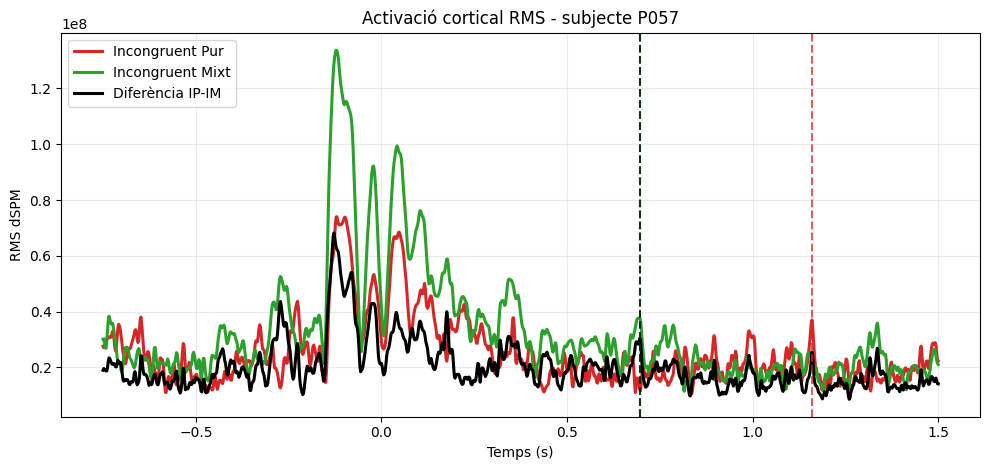

Corbes de fonts subjecte desades a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\source_activation_P057_IP_IM_diff.png


In [ ]:
# 16. Source location - best subject, Congruent vs IP and Incongruent Mixed vs IP
fs_dir = fetch_fsaverage(verbose=False)
subjects_dir = os.path.dirname(fs_dir)
subject = "fsaverage"
trans = "fsaverage"
src = os.path.join(fs_dir, "bem", "fsaverage-ico-5-src.fif")
bem = os.path.join(fs_dir, "bem", "fsaverage-5120-5120-5120-bem-sol.fif")

method = "dSPM"
snr = 3.0
lambda2 = 1.0 / snr**2


def prepare_evoked_for_sources(epochs):
    evoked = epochs.average()
    evoked.set_eeg_reference(projection=True).apply_proj()
    return evoked


def make_source_estimate(evoked, inverse_operator):
    return apply_inverse(evoked, inverse_operator, lambda2, method=method, pick_ori=None, verbose=False)


best_subject_stcs = {}

for task in ["c_vs_ip", "im_vs_ip"]:
    best_subj_name = best_subjects_by_task[task]
    print(f"\n==========================================")
    print(f"Calculating sources for best subject of {task}: {best_subj_name}")
    print(f"==========================================")

    # Load best subject's raw epochs to retain negative baseline
    fif_path = sl_fif_by_subject[best_subj_name]
    ep_raw, _ = sl_read_epochs_safe(fif_path)

    for ch_idx, ch_name in enumerate(ep_raw.ch_names):
        if ep_raw.info["chs"][ch_idx]["unit"] == 0:
            ep_raw.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
            ep_raw.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

    ep_raw.set_channel_types({ch: "eeg" for ch in ep_raw.ch_names}, on_unit_change="ignore")
    ep_raw = ep_raw.pick(mne.pick_types(ep_raw.info, eeg=True))
    ep_raw = ep_raw.crop(tmin=-0.75, tmax=1.5)

    events = ep_raw.events[:, 2]
    mask_c = np.isin(events, COND_CODES["C"])
    mask_ip = np.isin(events, COND_CODES["IP"])
    mask_im = np.isin(events, COND_CODES["IM"])

    ep_c = ep_raw[mask_c]
    ep_ip = ep_raw[mask_ip]
    ep_im = ep_raw[mask_im]

    evoked_c = prepare_evoked_for_sources(ep_c)
    evoked_ip = prepare_evoked_for_sources(ep_ip)
    evoked_im = prepare_evoked_for_sources(ep_im)

    noise_cov = mne.make_ad_hoc_cov(evoked_c.info)
    fwd = mne.make_forward_solution(evoked_c.info, trans=trans, src=src, bem=bem, eeg=True, verbose=False)
    inverse_operator = make_inverse_operator(evoked_c.info, fwd, noise_cov, loose=0.2, depth=0.8, verbose=False)

    stc_c = make_source_estimate(evoked_c, inverse_operator)
    stc_ip = make_source_estimate(evoked_ip, inverse_operator)
    stc_im = make_source_estimate(evoked_im, inverse_operator)

    stc_diff_c_vs_ip = stc_ip.copy()
    stc_diff_c_vs_ip.data = stc_ip.data - stc_c.data

    stc_diff_im_vs_ip = stc_ip.copy()
    stc_diff_im_vs_ip.data = stc_ip.data - stc_im.data

    best_subject_stcs[task] = {
        "stc_c": stc_c,
        "stc_ip": stc_ip,
        "stc_im": stc_im,
        "stc_diff_c_vs_ip": stc_diff_c_vs_ip,
        "stc_diff_im_vs_ip": stc_diff_im_vs_ip,
        "best_subj_name": best_subj_name,
    }

    print(f"Calculated sources for subject {best_subj_name} ({task}): C, IP, IM, difference IP-C and difference IP-IM")

    # 2D summary: global activation by condition and difference
    rms_c = np.sqrt(np.mean(stc_c.data**2, axis=0))
    rms_ip = np.sqrt(np.mean(stc_ip.data**2, axis=0))
    rms_im = np.sqrt(np.mean(stc_im.data**2, axis=0))
    rms_diff_c_vs_ip = np.sqrt(np.mean(stc_diff_c_vs_ip.data**2, axis=0))
    rms_diff_im_vs_ip = np.sqrt(np.mean(stc_diff_im_vs_ip.data**2, axis=0))

    _, t_peak_c = stc_c.get_peak(hemi=None, tmin=0.5, tmax=1.5)
    _, t_peak_ip = stc_ip.get_peak(hemi=None, tmin=0.5, tmax=1.5)
    _, t_peak_im = stc_im.get_peak(hemi=None, tmin=0.5, tmax=1.5)

    # Calculate peaks for difference curves
    def get_rms_peak_time(stc_obj, tmin=0.5, tmax=1.5):
        mask = (stc_obj.times >= tmin) & (stc_obj.times <= tmax)
        rms = np.sqrt(np.mean(stc_obj.data[:, mask] ** 2, axis=0))
        return float(stc_obj.times[mask][np.argmax(rms)])

    t_peak_diff_c_vs_ip = get_rms_peak_time(stc_diff_c_vs_ip)
    t_peak_diff_im_vs_ip = get_rms_peak_time(stc_diff_im_vs_ip)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(stc_c.times, rms_c, color="tab:blue", linewidth=2.0, label="Congruent (C)")
    ax.plot(stc_ip.times, rms_ip, color="tab:red", linewidth=2.0, label="Incongruent Pure (IP)")
    ax.plot(stc_im.times, rms_im, color="tab:green", linewidth=2.0, label="Incongruent Mixed (IM)")
    ax.plot(
        stc_diff_c_vs_ip.times,
        rms_diff_c_vs_ip,
        color="black",
        linestyle="-",
        linewidth=2.0,
        label="Difference (IP - C)",
    )
    ax.plot(
        stc_diff_im_vs_ip.times,
        rms_diff_im_vs_ip,
        color="purple",
        linestyle="-",
        linewidth=2.0,
        label="Difference (IP - IM)",
    )

    ax.axvline(t_peak_c, color="tab:blue", linestyle="--", alpha=0.6)
    ax.axvline(t_peak_ip, color="tab:red", linestyle="--", alpha=0.6)
    ax.axvline(t_peak_im, color="tab:green", linestyle="--", alpha=0.6)
    ax.axvline(t_peak_diff_c_vs_ip, color="black", linestyle="--", alpha=0.6)
    ax.axvline(t_peak_diff_im_vs_ip, color="purple", linestyle="--", alpha=0.6)

    ax.set_title(f"RMS Cortical Activation - Subject {best_subj_name} ({task.upper()})")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("RMS dSPM")
    ax.legend(loc="best")
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    out_subject_rms = FIGURES_DIR / f"source_activation_{best_subj_name}_{task}_conditions_and_diffs.png"
    plt.savefig(out_subject_rms, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Subject source curves saved to: {out_subject_rms}")

### Between 0.3 and 0.8s


In [ ]:
mne.viz.set_3d_backend("pyvistaqt")

limits = [50, 75, 95]


def _stc_peak_time_by_rms(stc_obj, tmin=0.5, tmax=1.5):
    mask = (stc_obj.times >= tmin) & (stc_obj.times <= tmax)
    rms = np.sqrt(np.mean(stc_obj.data[:, mask] ** 2, axis=0))
    return float(stc_obj.times[mask][int(np.argmax(rms))])


def _prepare_stc_for_render(stc_obj, *, signed=False):
    out = stc_obj.copy()
    denom = np.nanpercentile(np.abs(out.data), 99.7)
    if not np.isfinite(denom) or denom <= 0:
        denom = 1.0
    out.data = (out.data / denom) * 100.0
    if not signed:
        out.data = np.abs(out.data)
    return out


def render_source_panel(stc_obj, label, out_name, *, signed=False, tmin=0.5, tmax=1.5):
    stc_plot = _prepare_stc_for_render(stc_obj, signed=signed)
    t_peak = _stc_peak_time_by_rms(stc_plot, tmin=tmin, tmax=tmax)

    if signed:
        low = float(np.nanpercentile(stc_plot.data, 5))
        high = float(np.nanpercentile(stc_plot.data, 95))
        mid = float(np.nanmean(stc_plot.data))
        if mid <= low:
            mid = low + 1.0
        if high <= mid:
            high = mid + 1.0
        clim = dict(kind="value", lims=[low, mid, high])
        colormap = "RdBu_r"
        try:
            cbar_norm = mpl.colors.TwoSlopeNorm(vcenter=mid, vmin=low, vmax=high)
        except ValueError:
            cbar_norm = mpl.colors.Normalize(vmin=low, vmax=high)
    else:
        clim = dict(kind="value", lims=limits)
        colormap = "plasma"
        cbar_norm = mpl.colors.Normalize(vmin=limits[0], vmax=limits[2])

    render_kwargs = dict(
        subject=subject,
        subjects_dir=subjects_dir,
        initial_time=t_peak,
        surface="inflated",
        clim=clim,
        colormap=colormap,
        smoothing_steps=10,
        time_viewer=False,
        show_traces=False,
        background="w",
        size=(800, 800),
        colorbar=False,
    )

    def captura_i_retalla(hemi, vista):
        brain = stc_plot.plot(hemi=hemi, views=vista, **render_kwargs)
        img = brain.screenshot()
        brain.close()
        rgb = img[:, :, :3]
        non_white = np.any(rgb < 250, axis=-1)
        rows = np.any(non_white, axis=1)
        cols = np.any(non_white, axis=0)
        if not np.any(rows):
            return img
        ymin, ymax = np.where(rows)[0][[0, -1]]
        xmin, xmax = np.where(cols)[0][[0, -1]]
        m = 20
        return img[max(0, ymin - m) : ymax + m, max(0, xmin - m) : xmax + m]

    print(f"Rendering {label} @ {t_peak:.2f}s...")
    img_dor = captura_i_retalla("both", "dorsal")
    img_lat_l = captura_i_retalla("lh", "lateral")
    img_lat_r = captura_i_retalla("rh", "lateral")
    img_med_l = captura_i_retalla("lh", "medial")
    img_med_r = captura_i_retalla("rh", "medial")

    fig = plt.figure(figsize=(12, 18))
    gs = fig.add_gridspec(5, 4, height_ratios=[2, 0.15, 0.1, 1.2, 1.2], hspace=0.2, wspace=0.05)

    ax_dor = fig.add_subplot(gs[0, :])
    ax_dor.imshow(img_dor)
    ax_dor.axis("off")
    ax_dor.set_title(f"{label}\nCapture time: {t_peak:.2f} s", fontsize=18, fontweight="bold", pad=20)

    ax_cbar = fig.add_subplot(gs[1, 1:3])
    cmap = plt.get_cmap(colormap)
    cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=cbar_norm, cmap=cmap), cax=ax_cbar, orientation="horizontal")
    cbar.set_label(
        "Normalized difference (%)" if signed else "Normalized activation (%)", fontsize=14, fontweight="bold"
    )
    cbar.ax.tick_params(labelsize=12)

    axes = [
        (fig.add_subplot(gs[3, 0:2]), img_lat_l, "Left hemisphere lateral"),
        (fig.add_subplot(gs[3, 2:4]), img_lat_r, "Right hemisphere lateral"),
        (fig.add_subplot(gs[4, 0:2]), img_med_l, "Left hemisphere medial"),
        (fig.add_subplot(gs[4, 2:4]), img_med_r, "Right hemisphere medial"),
    ]
    for ax, img, title in axes:
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(title, fontsize=14)

    out_path = FIGURES_DIR / out_name
    plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Cortical panel saved to: {out_path}")
    return out_path


render_source_panel(stc_c, f"Cortical activation Congruent - {subj_name}", f"3d_source_{subj_name}_C.png")
render_source_panel(stc_ip, f"Cortical activation Incongruent Pure - {subj_name}", f"3d_source_{subj_name}_IP.png")
render_source_panel(stc_im, f"Cortical activation Incongruent Mixed - {subj_name}", f"3d_source_{subj_name}_IM.png")
render_source_panel(
    stc_diff_c_vs_ip, f"IP cortical difference - C - {subj_name}", f"3d_source_{subj_name}_IP_minus_C.png", signed=True
)
render_source_panel(
    stc_diff_im_vs_ip,
    f"IP cortical difference - IM - {subj_name}",
    f"3d_source_{subj_name}_IP_minus_IM.png",
    signed=True,
)

NameError: name 'mne' is not defined

### Between 0.5 and 1.5s


In [ ]:
# We ensure set 3d backend
mne.viz.set_3d_backend("pyvistaqt")


def make_poster_for_contrast(stc_diff_obj, contrast_name, out_filename):
    stc_plot = stc_diff_obj.copy()
    robust_max = np.percentile(np.abs(stc_plot.data), 99.7)
    if not np.isfinite(robust_max) or robust_max <= 0:
        robust_max = 1.0
    stc_plot.data = (stc_plot.data / robust_max) * 100

    t_inici, t_fi = 0.5, 1.5
    t_peak = _stc_peak_time_by_rms(stc_plot, tmin=t_inici, tmax=t_fi)
    print(f"[{contrast_name}] Difference peak RMS found in: {t_peak:.2f} s")

    # Calculate bounds for asymmetric colormap (5%, mean, 95%)
    low = float(np.percentile(stc_plot.data, 5))
    high = float(np.percentile(stc_plot.data, 95))
    mid = float(np.mean(stc_plot.data))
    if mid <= low:
        mid = low + 1.0
    if high <= mid:
        high = mid + 1.0
    llindars = dict(kind="value", lims=[low, mid, high])

    try:
        cbar_norm = mpl.colors.TwoSlopeNorm(vcenter=mid, vmin=low, vmax=high)
    except ValueError:
        cbar_norm = mpl.colors.Normalize(vmin=low, vmax=high)

    render_kwargs = dict(
        subject=subject,
        subjects_dir=subjects_dir,
        initial_time=t_peak,
        surface="inflated",
        clim=llindars,
        colormap="RdBu_r",
        smoothing_steps=10,
        time_viewer=False,
        show_traces=False,
        background="w",
        size=(800, 800),
        colorbar=False,
    )

    def captura_i_retalla(hemi, vista):
        brain = stc_plot.plot(hemi=hemi, views=vista, **render_kwargs)
        img = brain.screenshot()
        brain.close()

        rgb = img[:, :, :3]
        non_white = np.any(rgb < 250, axis=-1)
        rows = np.any(non_white, axis=1)
        cols = np.any(non_white, axis=0)

        if not np.any(rows):
            return img
        ymin, ymax = np.where(rows)[0][[0, -1]]
        xmin, xmax = np.where(cols)[0][[0, -1]]
        m = 20
        return img[max(0, ymin - m) : ymax + m, max(0, xmin - m) : xmax + m]

    print(f"[{contrast_name}] Taking high-resolution 3D photos...")
    img_dor = captura_i_retalla("both", "dorsal")
    img_lat_l = captura_i_retalla("lh", "lateral")
    img_lat_r = captura_i_retalla("rh", "lateral")
    img_med_l = captura_i_retalla("lh", "medial")
    img_med_r = captura_i_retalla("rh", "medial")

    print(f"[{contrast_name}] Assembling the final canvas...")
    fig = plt.figure(figsize=(12, 18))
    gs = gridspec.GridSpec(5, 4, height_ratios=[2, 0.15, 0.1, 1.2, 1.2], hspace=0.2, wspace=0.05)

    ax_dor = fig.add_subplot(gs[0, :])
    ax_dor.imshow(img_dor)
    ax_dor.axis("off")
    ax_dor.set_title(
        f"Cortical Difference {contrast_name}\nTime of capture: {t_peak:.2f} s", fontsize=18, fontweight="bold", pad=20
    )

    ax_cbar = fig.add_subplot(gs[1, 1:3])
    cmap = plt.get_cmap("RdBu_r")
    cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=cbar_norm, cmap=cmap), cax=ax_cbar, orientation="horizontal")
    cbar.set_label(f"{contrast_name} normalized difference (%)", fontsize=14, fontweight="bold")
    cbar.set_ticks([low, mid, high])
    cbar.ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.1f"))
    cbar.ax.tick_params(labelsize=12)

    ax_ll = fig.add_subplot(gs[3, 0:2])
    ax_ll.imshow(img_lat_l)
    ax_ll.axis("off")
    ax_ll.set_title("Left Hemisphere (Lateral / Exterior)", fontsize=14)

    ax_rl = fig.add_subplot(gs[3, 2:4])
    ax_rl.imshow(img_lat_r)
    ax_rl.axis("off")
    ax_rl.set_title("Right Hemisphere (Lateral / Exterior)", fontsize=14)

    ax_ml = fig.add_subplot(gs[4, 0:2])
    ax_ml.imshow(img_med_l)
    ax_ml.axis("off")
    ax_ml.set_title("Left Hemisphere (Medial / Interior)", fontsize=14)

    ax_mr = fig.add_subplot(gs[4, 2:4])
    ax_mr.imshow(img_med_r)
    ax_mr.axis("off")
    ax_mr.set_title("Right Hemisphere (Medial / Interior)", fontsize=14)

    out_path = FIGURES_DIR / out_filename
    plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"Poster saved to: {out_path}")


# Generate posters for both contrasts using the respective best subject STC differences
stc_diff_c_vs_ip = best_subject_stcs["c_vs_ip"]["stc_diff_c_vs_ip"]
subj_name_c = best_subject_stcs["c_vs_ip"]["best_subj_name"]
make_poster_for_contrast(stc_diff_c_vs_ip, "IP - C", f"3d_source_{subj_name_c}_IP_minus_C_custom.png")

stc_diff_im_vs_ip = best_subject_stcs["im_vs_ip"]["stc_diff_im_vs_ip"]
subj_name_im = best_subject_stcs["im_vs_ip"]["best_subj_name"]
make_poster_for_contrast(stc_diff_im_vs_ip, "IP - IM", f"3d_source_{subj_name_im}_IP_minus_IM_custom.png")

NameError: name 'sl_set_3d_backend' is not defined


Generant Localització de les fonts Grand Average...


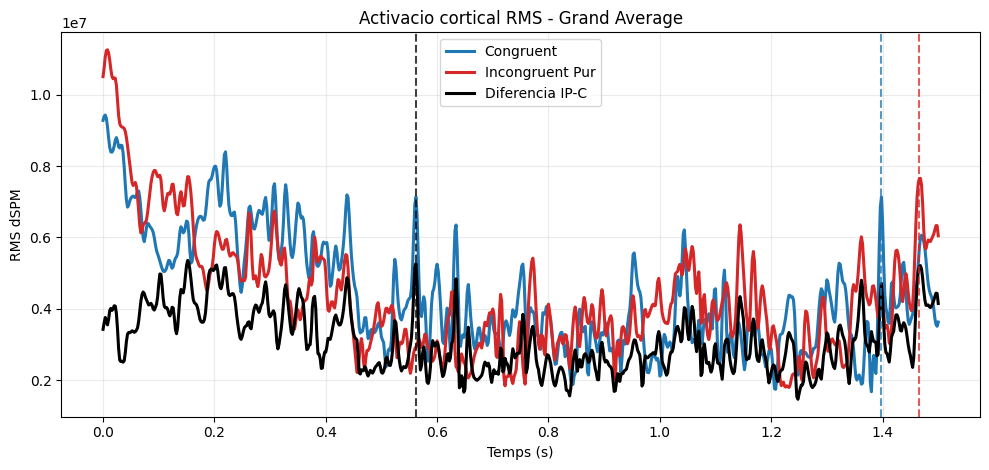

Corbes de fonts grand average desades a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\source_activation_GA_C_IP_diff.png
GA Congruent peak = 1.40s | GA IP peak = 1.47s | GA IP-C RMS peak = 0.56s
Renderitzant Activació cortical Congruent - Grand Average @ 0.56s...


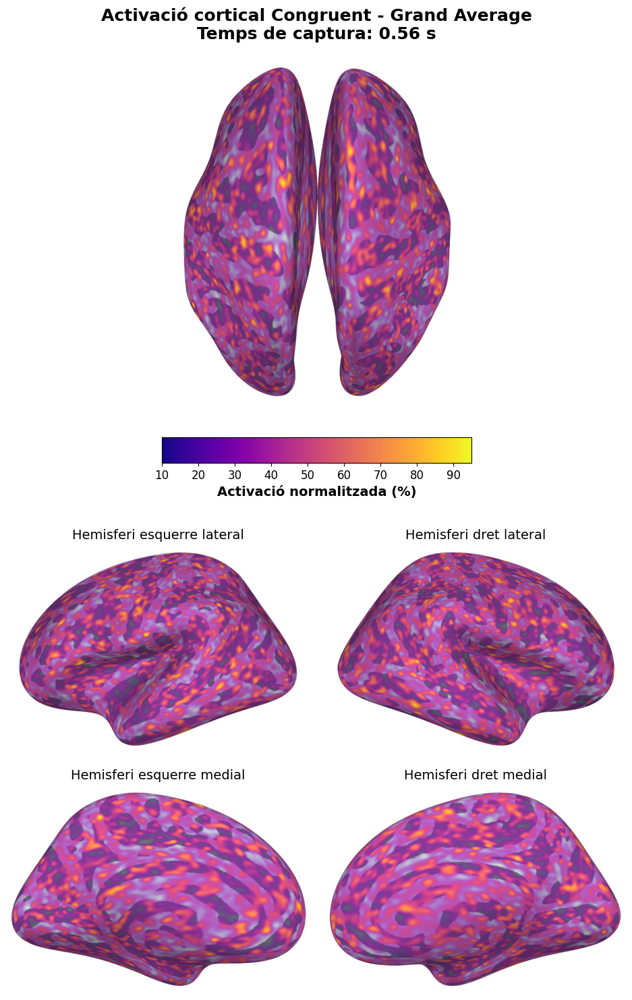

Panell cortical desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_source_GA_C.png
Renderitzant Activació cortical Incongruent Pur - Grand Average @ 1.47s...


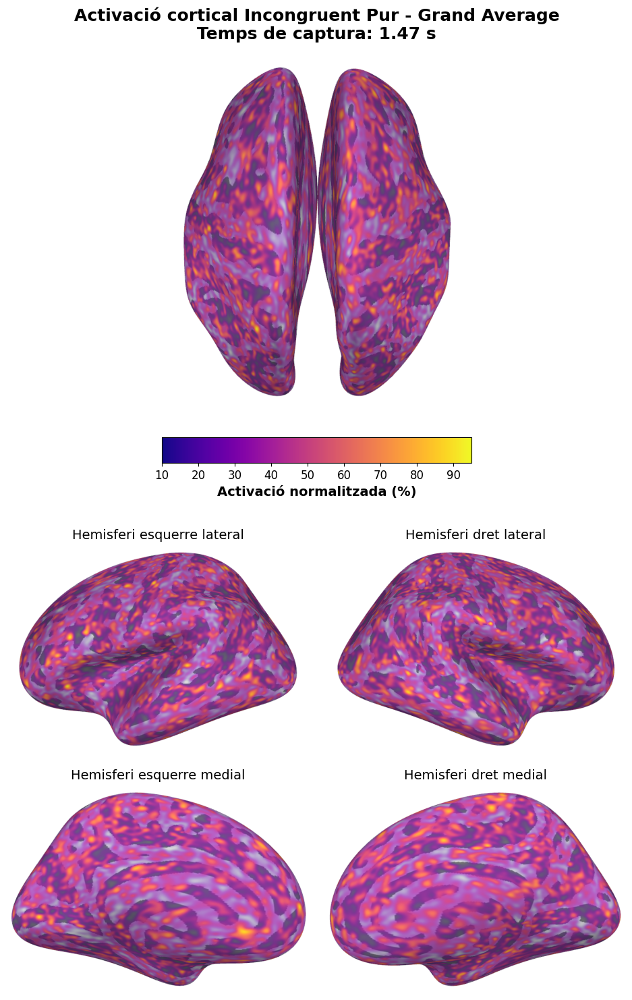

Panell cortical desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_source_GA_IP.png
Renderitzant Diferència cortical IP - C - Grand Average @ 0.56s...


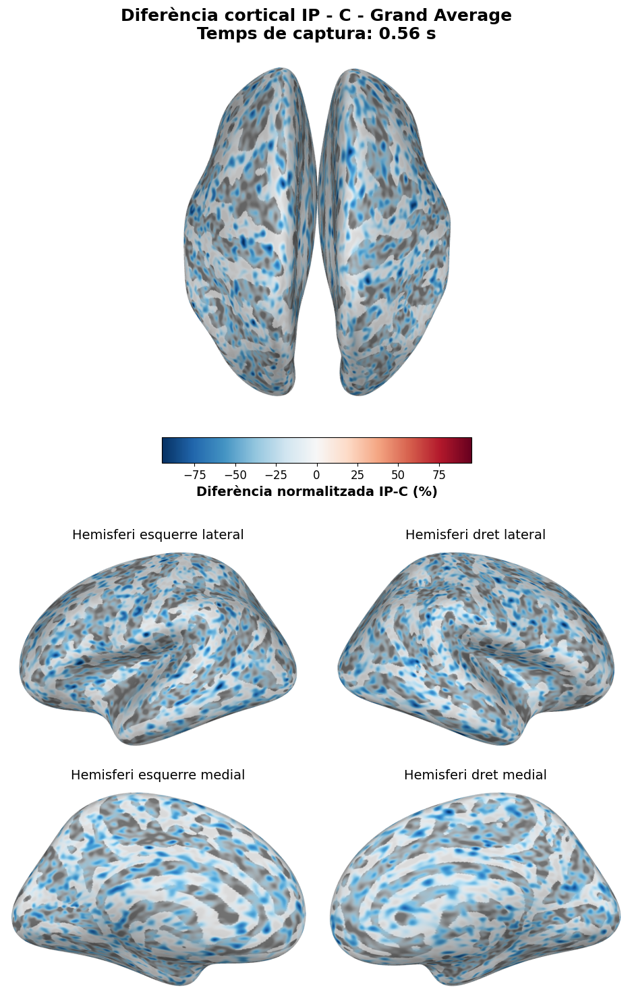

Panell cortical desat a: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\05_visualitzacions\figures\3d_source_GA_IP_minus_C.png


WindowsPath('H:/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026/04_Anàlisi/05_visualitzacions/figures/3d_source_GA_IP_minus_C.png')

In [ ]:
print("\nGenerating Grand Average Source Localization...")

# Cohort C vs IP (24 subjects):
all_evoked_c_c = []
all_evoked_ip_c = []
for s in sl_subjects_c:
    ep_s = s["epochs"]
    all_evoked_c_c.append(prepare_evoked_for_sources(ep_s[np.isin(ep_s.events[:, 2], COND_CODES["C"])]))
    all_evoked_ip_c.append(prepare_evoked_for_sources(ep_s[np.isin(ep_s.events[:, 2], COND_CODES["IP"])]))

ga_evoked_c = mne.grand_average(all_evoked_c_c)
ga_evoked_c.set_eeg_reference(projection=True).apply_proj()
ga_evoked_ip_c = mne.grand_average(all_evoked_ip_c)
ga_evoked_ip_c.set_eeg_reference(projection=True).apply_proj()

ga_noise_cov_c = mne.make_ad_hoc_cov(ga_evoked_c.info)
ga_inverse_operator_c = make_inverse_operator(
    ga_evoked_c.info, fwd, ga_noise_cov_c, loose=0.2, depth=0.8, verbose=False
)

ga_stc_c = make_source_estimate(ga_evoked_c, ga_inverse_operator_c)
ga_stc_ip_c = make_source_estimate(ga_evoked_ip_c, ga_inverse_operator_c)

ga_stc_diff_c_vs_ip = ga_stc_ip_c.copy()
ga_stc_diff_c_vs_ip.data = ga_stc_ip_c.data - ga_stc_c.data


# Cohort IM vs IP (29 subjects):
all_evoked_im_im = []
all_evoked_ip_im = []
for s in sl_subjects_im:
    ep_s = s["epochs"]
    all_evoked_im_im.append(prepare_evoked_for_sources(ep_s[np.isin(ep_s.events[:, 2], COND_CODES["IM"])]))
    all_evoked_ip_im.append(prepare_evoked_for_sources(ep_s[np.isin(ep_s.events[:, 2], COND_CODES["IP"])]))

ga_evoked_im = mne.grand_average(all_evoked_im_im)
ga_evoked_im.set_eeg_reference(projection=True).apply_proj()
ga_evoked_ip_im = mne.grand_average(all_evoked_ip_im)
ga_evoked_ip_im.set_eeg_reference(projection=True).apply_proj()

ga_noise_cov_im = mne.make_ad_hoc_cov(ga_evoked_im.info)
ga_inverse_operator_im = make_inverse_operator(
    ga_evoked_im.info, fwd, ga_noise_cov_im, loose=0.2, depth=0.8, verbose=False
)

ga_stc_im = make_source_estimate(ga_evoked_im, ga_inverse_operator_im)
ga_stc_ip_im = make_source_estimate(ga_evoked_ip_im, ga_inverse_operator_im)

ga_stc_diff_im_vs_ip = ga_stc_ip_im.copy()
ga_stc_diff_im_vs_ip.data = ga_stc_ip_im.data - ga_stc_im.data


# Compute RMS activations
rms_c = np.sqrt(np.mean(ga_stc_c.data**2, axis=0))
rms_ip_c = np.sqrt(np.mean(ga_stc_ip_c.data**2, axis=0))
rms_im = np.sqrt(np.mean(ga_stc_im.data**2, axis=0))
rms_ip_im = np.sqrt(np.mean(ga_stc_ip_im.data**2, axis=0))
rms_diff_c_vs_ip = np.sqrt(np.mean(ga_stc_diff_c_vs_ip.data**2, axis=0))
rms_diff_im_vs_ip = np.sqrt(np.mean(ga_stc_diff_im_vs_ip.data**2, axis=0))

_, t_peak_c = ga_stc_c.get_peak(hemi=None, tmin=0.5, tmax=1.5)
_, t_peak_ip_c = ga_stc_ip_c.get_peak(hemi=None, tmin=0.5, tmax=1.5)
_, t_peak_im = ga_stc_im.get_peak(hemi=None, tmin=0.5, tmax=1.5)
_, t_peak_ip_im = ga_stc_ip_im.get_peak(hemi=None, tmin=0.5, tmax=1.5)
t_peak_diff_c_vs_ip = _stc_peak_time_by_rms(ga_stc_diff_c_vs_ip, tmin=0.5, tmax=1.5)
t_peak_diff_im_vs_ip = _stc_peak_time_by_rms(ga_stc_diff_im_vs_ip, tmin=0.5, tmax=1.5)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ga_stc_c.times, rms_c, color="tab:blue", linewidth=2.0, label="Congruent (C)")
ax.plot(ga_stc_ip_c.times, rms_ip_c, color="tab:red", linewidth=2.0, label="Incongruent Pure (IP) - Cohort C")
ax.plot(ga_stc_im.times, rms_im, color="tab:green", linewidth=2.0, label="Incongruent Mixed (IM)")
ax.plot(ga_stc_ip_im.times, rms_ip_im, color="orange", linewidth=2.0, label="Incongruent Pure (IP) - Cohort IM")
ax.plot(
    ga_stc_diff_c_vs_ip.times,
    rms_diff_c_vs_ip,
    color="black",
    linestyle="-",
    linewidth=2.0,
    label="Difference (IP - C)",
)
ax.plot(
    ga_stc_diff_im_vs_ip.times,
    rms_diff_im_vs_ip,
    color="purple",
    linestyle="-",
    linewidth=2.0,
    label="Difference (IP - IM)",
)

ax.axvline(t_peak_c, color="tab:blue", linestyle="--", alpha=0.6)
ax.axvline(t_peak_ip_c, color="tab:red", linestyle="--", alpha=0.6)
ax.axvline(t_peak_im, color="tab:green", linestyle="--", alpha=0.6)
ax.axvline(t_peak_ip_im, color="orange", linestyle="--", alpha=0.6)
ax.axvline(t_peak_diff_c_vs_ip, color="black", linestyle="--", alpha=0.6)
ax.axvline(t_peak_diff_im_vs_ip, color="purple", linestyle="--", alpha=0.6)

ax.set_title("Cortical RMS Activation - Grand Average")
ax.set_xlabel("Time (s)")
ax.set_ylabel("RMS dSPM")
ax.legend(loc="best")
ax.grid(True, alpha=0.25)
plt.tight_layout()
out_rms_ga = FIGURES_DIR / "source_activation_GA_all_conditions_and_diffs.png"
plt.savefig(out_rms_ga, dpi=300, bbox_inches="tight")
plt.close(fig)

print(f"Grand average source curves saved to: {out_rms_ga}")
print(
    f"GA Congruent peak = {t_peak_c:.2f}s | GA IP (C Cohort) peak = {t_peak_ip_c:.2f}s | GA IP (IM Cohort) peak = {t_peak_ip_im:.2f}s"
)
print(f"GA IP-C RMS peak = {t_peak_diff_c_vs_ip:.2f}s | GA IP-IM RMS peak = {t_peak_diff_im_vs_ip:.2f}s")

render_source_panel(ga_stc_c, "Cortical activation Congruent - Grand Average", "3d_source_GA_C.png")
render_source_panel(
    ga_stc_ip_c, "Cortical activation Incongruent Pure (C Cohort) - Grand Average", "3d_source_GA_IP_C.png"
)
render_source_panel(ga_stc_im, "Cortical activation Incongruent Mixed - Grand Average", "3d_source_GA_IM.png")
render_source_panel(
    ga_stc_ip_im, "Cortical activation Incongruent Pure (IM Cohort) - Grand Average", "3d_source_GA_IP_IM.png"
)
render_source_panel(
    ga_stc_diff_c_vs_ip, "Cortical difference IP - C - Grand Average", "3d_source_GA_IP_minus_C.png", signed=True
)
render_source_panel(
    ga_stc_diff_im_vs_ip, "Cortical difference IP - IM - Grand Average", "3d_source_GA_IP_minus_IM.png", signed=True
)

With this plot we can see very clearly the hypothesis that the ACC (Anterior Cingulate Cortex) is the most active region in the Congruent vs Incongruent contrast. The cerebral cortex has little activity, but the opposite is true around the ACC.
